# 📓🧠 **Actividad 8. Monitorización proactiva y respuesta a incidentes**
## **Asistente de seguros de vida — VidaSegura**



### 🧠 **1. Conexión con Google Drive**

**Objetivo:** conectar Google Drive para localizar el paquete del modelo V3 y recuperar sus archivos.

Utilizaremos el modelo previamente entrenado. Los resultados de esta actividad se guardarán por separado para conservar intactos el modelo y sus evidencias originales.

In [1]:
# ============================================================
# 1. CONEXIÓN CON GOOGLE DRIVE
# ============================================================
# Propósito:
#   Acceder al paquete del modelo VidaSegura V3 y guardar
#   posteriormente las evidencias de la actividad.
#
# Resultado esperado:
#   Google Drive disponible en /content/drive.
# ============================================================

from google.colab import drive
from pathlib import Path

# Solicitar autorización y conectar la unidad al entorno de Colab.
drive.mount("/content/drive")

# Verificar que la carpeta principal de la unidad está disponible.
ruta_drive = Path("/content/drive/MyDrive")

if not ruta_drive.is_dir():
    raise RuntimeError("No se pudo verificar el acceso a Mi unidad.")

# Mostrar la confirmación después de verificar la conexión.
print("✅ Paso 1 completado: Google Drive está conectado y Mi unidad está disponible.")
print("📁 Ubicación de acceso:", ruta_drive)
print("➡️ Siguiente paso: localizar y verificar el paquete del modelo VidaSegura V3.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Paso 1 completado: Google Drive está conectado y Mi unidad está disponible.
📁 Ubicación de acceso: /content/drive/MyDrive
➡️ Siguiente paso: localizar y verificar el paquete del modelo VidaSegura V3.


### 🧠 **2. Localización y verificación del paquete V3**

**Objetivo:** localizar el modelo dentro de la carpeta de la materia y comprobar que el ZIP coincide con el paquete original.

La búsqueda respetará esta estructura:

**Master IA → 5-Gestión de Proyectos… → asistente-seguros-ia → Preparacion_Modelo_Espanol**

Como el nombre completo de la carpeta de la materia aparece recortado en Drive, lo identificaremos automáticamente.

**Resultado esperado:** mostrar la ruta completa del ZIP y confirmar su integridad mediante su huella SHA-256.

In [2]:
# ============================================================
# 2. LOCALIZACIÓN Y VERIFICACIÓN DEL PAQUETE VIDASEGURA V3
# ============================================================
# Propósito:
#   Encontrar el ZIP dentro de la carpeta de la materia y
#   comprobar que corresponde al paquete original entregado.
#
# Procedimiento:
#   1. Identificar la carpeta de Gestión de Proyectos.
#   2. Localizar el archivo en la estructura del proyecto.
#   3. Verificar que existe una única coincidencia.
#   4. Comparar su huella SHA-256 con la del paquete original.
#
# Resultado esperado:
#   Ruta del paquete identificada e integridad confirmada.
#   En este paso todavía no extraemos ni cargamos el modelo.
# ============================================================

from pathlib import Path
import hashlib
import unicodedata

# Ubicación principal de la maestría en Google Drive.
RUTA_MAESTRIA = Path("/content/drive/MyDrive/Master IA")

NOMBRE_PAQUETE = "Modelo_VidaSegura_ES_V3_Base_Actividad8.zip"

SHA256_ESPERADO = (
    "ca1c7873d96d75563c537ef220a814057"
    "c05b69b7b7a4aff74704610599e8542"
)

# Reiniciar la variable para evitar reutilizar una ruta anterior
# si esta ejecución encuentra algún problema.
RUTA_PAQUETE = None


def normalizar_nombre(texto):
    """
    Facilita la comparación de nombres de carpetas.

    Parámetros:
        texto (str): nombre que se desea comparar.

    Retorna:
        str: nombre en minúsculas y sin diferencias de acentos.
    """
    texto = unicodedata.normalize("NFKD", texto.casefold())
    return "".join(
        caracter for caracter in texto
        if not unicodedata.combining(caracter)
    )


# Comprobar que la carpeta principal está disponible.
if not RUTA_MAESTRIA.is_dir():
    raise FileNotFoundError(
        f"No se encontró la carpeta: {RUTA_MAESTRIA}. "
        "Comprueba la conexión y la cuenta de Google Drive."
    )

# Buscar únicamente dentro de las carpetas de la materia.
coincidencias = []

for carpeta in RUTA_MAESTRIA.iterdir():
    if (
        carpeta.is_dir()
        and normalizar_nombre(carpeta.name).startswith(
            "5-gestion de proyectos"
        )
    ):
        candidato = (
            carpeta
            / "asistente-seguros-ia"
            / "Preparacion_Modelo_Espanol"
            / NOMBRE_PAQUETE
        )

        if candidato.is_file():
            coincidencias.append(candidato)

# Evitar seleccionar un archivo incorrecto o ambiguo.
if not coincidencias:
    raise FileNotFoundError(
        "No se encontró el ZIP en la estructura esperada. "
        "Revisa su nombre y ubicación en Google Drive."
    )

if len(coincidencias) > 1:
    raise RuntimeError(
        "Se encontró más de un paquete. Debemos identificar "
        "la ubicación correcta antes de continuar:\n"
        + "\n".join(str(ruta) for ruta in coincidencias)
    )

# Calcular la huella sin modificar el archivo.
paquete_encontrado = coincidencias[0]
huella = hashlib.sha256()

with paquete_encontrado.open("rb") as archivo:
    for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
        huella.update(bloque)

if huella.hexdigest() != SHA256_ESPERADO:
    raise ValueError(
        "La huella del ZIP no coincide con el paquete original. "
        "Debemos revisar el archivo antes de utilizarlo."
    )

# Conservar la ruta verificada para los siguientes pasos.
RUTA_PAQUETE = paquete_encontrado

# Confirmar lo realizado únicamente después de las verificaciones.
print("✅ Paso 2 completado: paquete V3 localizado y verificado.")
print("📁 Ruta completa:", RUTA_PAQUETE)
print("🔎 Integridad SHA-256: coincide con el paquete original.")
print("➡️ Siguiente paso: extraer y revisar los archivos del paquete.")

✅ Paso 2 completado: paquete V3 localizado y verificado.
📁 Ruta completa: /content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/asistente-seguros-ia/Preparacion_Modelo_Espanol/Modelo_VidaSegura_ES_V3_Base_Actividad8.zip
🔎 Integridad SHA-256: coincide con el paquete original.
➡️ Siguiente paso: extraer y revisar los archivos del paquete.


### 🧠 **3. Extracción y revisión de los archivos del modelo**

**Objetivo:** recuperar los archivos del paquete V3 y verificar su integridad antes de cargar el modelo.

Extraeremos el ZIP en el almacenamiento temporal de Colab. El respaldo de Google Drive permanecerá intacto.

Revisaremos las huellas de los archivos, los metadatos del modelo y los tres conjuntos de datos:

- **448 consultas de desarrollo:** utilizadas para entrenar V3.
- **63 consultas sintéticas de prueba:** separadas del entrenamiento.
- **74 preguntas humanas revisadas:** utilizadas como diagnóstico.

**Resultado esperado:** archivos verificados y rutas disponibles para los siguientes pasos. Todavía no cargaremos el modelo ni ejecutaremos entrenamiento.

In [3]:
# ============================================================
# 3. EXTRACCIÓN Y VERIFICACIÓN DE LOS ARCHIVOS
# ============================================================
# Propósito:
#   Recuperar el contenido del ZIP verificado y comprobar sus
#   archivos mediante el manifiesto SHA-256 del paquete.
#
# Procedimiento:
#   1. Crear una carpeta temporal nueva en Colab.
#   2. Extraer el paquete sin modificar el respaldo de Drive.
#   3. Verificar las huellas de sus archivos.
#   4. Revisar los metadatos y tamaños de los conjuntos de datos.
#
# Resultado esperado:
#   Archivos íntegros y rutas preparadas para cargar V3.
# ============================================================

from pathlib import Path
import zipfile
import tempfile
import hashlib
import json
import csv


def calcular_sha256(ruta):
    """
    Calcula la huella de un archivo sin modificarlo.

    Parámetros:
        ruta (Path): ubicación del archivo que se verificará.

    Retorna:
        str: huella SHA-256 representada en hexadecimal.
    """
    huella = hashlib.sha256()

    with Path(ruta).open("rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            huella.update(bloque)

    return huella.hexdigest()


def contar_consultas(ruta):
    """
    Cuenta los registros de un CSV, excluyendo su encabezado.

    Parámetros:
        ruta (Path): ubicación del conjunto de datos.

    Retorna:
        int: número de consultas del archivo.
    """
    with Path(ruta).open(
        encoding="utf-8-sig", newline=""
    ) as archivo:
        return sum(1 for _ in csv.DictReader(archivo))


# Comprobar que el paso anterior dejó disponible el paquete.
if (
    "RUTA_PAQUETE" not in globals()
    or RUTA_PAQUETE is None
    or not RUTA_PAQUETE.is_file()
):
    raise RuntimeError(
        "Primero ejecuta correctamente el paso 2."
    )

# Confirmar nuevamente la integridad antes de extraer.
if calcular_sha256(RUTA_PAQUETE) != SHA256_ESPERADO:
    raise ValueError("El ZIP no coincide con el paquete original.")

# Cada ejecución utiliza una carpeta nueva y evita sobrescribir
# extracciones anteriores. El contenido es temporal en Colab.
carpeta_temporal = Path(
    tempfile.mkdtemp(prefix="actividad8_v3_", dir="/content")
)

with zipfile.ZipFile(RUTA_PAQUETE, "r") as paquete:
    archivo_danado = paquete.testzip()

    if archivo_danado is not None:
        raise ValueError(
            f"El ZIP contiene un archivo dañado: {archivo_danado}"
        )

    paquete.extractall(carpeta_temporal)

# Identificar la estructura interna del paquete.
RAIZ_V3 = carpeta_temporal / "VidaSegura_ES_V3"
RUTA_INSUMOS = RAIZ_V3 / "insumos"
RUTA_ENTRENAMIENTO = RAIZ_V3 / "entrenamiento"

# Comparar cada archivo con la huella registrada en el manifiesto.
ruta_manifiesto = RAIZ_V3 / "MANIFEST_PAQUETE_SHA256.json"
manifiesto = json.loads(
    ruta_manifiesto.read_text(encoding="utf-8")
)

for nombre, huella_esperada in manifiesto.items():
    ruta_archivo = RAIZ_V3 / nombre

    if not ruta_archivo.is_file():
        raise FileNotFoundError(f"Falta el archivo: {nombre}")

    if calcular_sha256(ruta_archivo) != huella_esperada:
        raise ValueError(
            f"La verificación de integridad falló: {nombre}"
        )

# Leer la información del modelo sin cargar todavía el joblib.
ruta_metadatos = (
    RUTA_ENTRENAMIENTO / "modelos" / "metadata_modelo.json"
)
METADATOS_V3 = json.loads(
    ruta_metadatos.read_text(encoding="utf-8")
)

# Verificar los tamaños esperados de los conjuntos.
conjuntos = {
    "desarrollo_v3.csv": 448,
    "prueba_sintetica_63.csv": 63,
    "referencia_humana_74.csv": 74,
}

for nombre, cantidad_esperada in conjuntos.items():
    cantidad = contar_consultas(RUTA_INSUMOS / nombre)

    if cantidad != cantidad_esperada:
        raise ValueError(
            f"{nombre}: se esperaban {cantidad_esperada} "
            f"consultas y se encontraron {cantidad}."
        )

# Mostrar lo realizado después de completar las verificaciones.
print("✅ Paso 3 completado: paquete extraído y archivos verificados.")
print("📁 Carpeta temporal:", RAIZ_V3)
print("🔎 Archivos verificados:", len(manifiesto))
print("🧠 Modelo seleccionado:", METADATOS_V3["seleccionado"])
print("🏷️ Categorías:", len(METADATOS_V3["categorias"]))
print("📊 Desarrollo: 448 | Prueba sintética: 63 | Diagnóstico: 74")
print("➡️ Siguiente paso: preparar las dependencias para cargar V3.")

✅ Paso 3 completado: paquete extraído y archivos verificados.
📁 Carpeta temporal: /content/actividad8_v3_o54ejm5v/VidaSegura_ES_V3
🔎 Archivos verificados: 45
🧠 Modelo seleccionado: regresion_logistica_C4
🏷️ Categorías: 7
📊 Desarrollo: 448 | Prueba sintética: 63 | Diagnóstico: 74
➡️ Siguiente paso: preparar las dependencias para cargar V3.


### 📓🧠 **4. Preparación y verificación de las dependencias**

**Objetivo:** disponer de las mismas versiones de las bibliotecas utilizadas para entrenar V3.

La celda revisará las versiones instaladas e instalará las dependencias únicamente si es necesario.

**Importante:** si se instalan paquetes, deberemos reiniciar la sesión y volver a ejecutar los pasos 1 al 4. Esto recupera las variables y evita mezclar bibliotecas antiguas con las recién instaladas. No repite el entrenamiento.

**Resultado esperado:** dependencias verificadas y entorno preparado para cargar el modelo.

In [4]:
# ============================================================
# 4. PREPARACIÓN Y VERIFICACIÓN DE LAS DEPENDENCIAS
# ============================================================
# Propósito:
#   Preparar un entorno compatible con el modelo V3 guardado.
#
# Procedimiento:
#   1. Consultar las versiones registradas en sus metadatos.
#   2. Compararlas con las bibliotecas instaladas.
#   3. Instalar las versiones requeridas si existen diferencias.
#   4. Comprobar que pueden importarse en un proceso separado.
#
# Resultado esperado:
#   Dependencias verificadas antes de cargar el modelo.
#
# Nota:
#   Si se instalan paquetes, es necesario reiniciar la sesión
#   y volver a ejecutar los pasos 1 al 4.
# ============================================================

from pathlib import Path
import importlib.metadata
import subprocess
import sys
import os
import json

if "METADATOS_V3" not in globals():
    raise RuntimeError(
        "Ejecuta primero los pasos 1 al 3."
    )

# Recuperar las versiones originales del entrenamiento.
versiones = METADATOS_V3["versiones"]

REQUISITOS_MODELO = {
    "numpy": versiones["numpy"],
    "pandas": versiones["pandas"],
    "scipy": versiones["scipy"],
    "scikit-learn": versiones["sklearn"],
    "joblib": versiones["joblib"],
}

# Este archivo permite comprobar que realmente se reinició
# la sesión después de instalar las dependencias.
MARCA_REINICIO = Path(
    "/content/actividad8_reinicio_dependencias.json"
)


def version_instalada(nombre):
    """
    Consulta la versión de un paquete sin importarlo.

    Parámetros:
        nombre (str): nombre del paquete instalado mediante pip.

    Retorna:
        str o None: versión encontrada o None si no está instalado.
    """
    try:
        return importlib.metadata.version(nombre)
    except importlib.metadata.PackageNotFoundError:
        return None


# Impedir continuar en la misma sesión tras una instalación.
if MARCA_REINICIO.exists():
    marca = json.loads(
        MARCA_REINICIO.read_text(encoding="utf-8")
    )

    if marca["pid"] == os.getpid():
        raise RuntimeError(
            "Todavía estás en la sesión donde se instalaron "
            "los paquetes. Reinicia la sesión desde el menú "
            "Entorno de ejecución y ejecuta los pasos 1 al 4."
        )

# Identificar diferencias sin importar las bibliotecas numéricas.
requiere_instalacion = any(
    version_instalada(nombre) != esperada
    for nombre, esperada in REQUISITOS_MODELO.items()
)

if requiere_instalacion:
    paquetes = [
        f"{nombre}=={version}"
        for nombre, version in REQUISITOS_MODELO.items()
    ]

    subprocess.run(
        [sys.executable, "-m", "pip", "install", "--quiet", *paquetes],
        check=True,
    )

    MARCA_REINICIO.write_text(
        json.dumps({"pid": os.getpid()}),
        encoding="utf-8",
    )

    print("📦 Las dependencias requeridas fueron instaladas.")
    print("🔄 Reinicia la sesión desde Entorno de ejecución.")
    print("➡️ Después vuelve a ejecutar los pasos 1 al 4.")

else:
    # Probar las importaciones en un proceso nuevo para comprobar
    # que las bibliotecas instaladas pueden cargarse juntas.
    codigo_verificacion = """
import json
import numpy
import pandas
import scipy
import sklearn
import joblib

print(json.dumps({
    "numpy": numpy.__version__,
    "pandas": pandas.__version__,
    "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
    "joblib": joblib.__version__,
}))
"""

    proceso = subprocess.run(
        [sys.executable, "-c", codigo_verificacion],
        capture_output=True,
        text=True,
    )

    if proceso.returncode != 0:
        raise RuntimeError(
            "No se pudieron importar las dependencias:\n"
            + proceso.stderr
        )

    versiones_verificadas = json.loads(proceso.stdout)

    if versiones_verificadas != REQUISITOS_MODELO:
        raise RuntimeError(
            "Las versiones importadas no coinciden "
            "con las del entrenamiento."
        )

    print("✅ Paso 4 completado: dependencias verificadas.")

    for nombre, version in versiones_verificadas.items():
        print(f"📦 {nombre}: {version}")

    print("🧠 No se ha cargado ni reentrenado el modelo.")
    print("➡️ Siguiente paso: cargar V3 y probar una consulta.")

✅ Paso 4 completado: dependencias verificadas.
📦 numpy: 2.1.3
📦 pandas: 2.2.3
📦 scipy: 1.15.3
📦 scikit-learn: 1.6.1
📦 joblib: 1.4.2
🧠 No se ha cargado ni reentrenado el modelo.
➡️ Siguiente paso: cargar V3 y probar una consulta.


### 🧠 **5. Carga del modelo V3 y prueba de funcionamiento**

**Objetivo:** recuperar el modelo entrenado y comprobar que puede
clasificar una consulta de seguros de vida.

Utilizaremos el cargador incluido en el paquete, que comprueba
la huella del modelo y la versión de scikit-learn.

La prueba mostrará categoría, puntaje, versión y tiempo de inferencia.
El puntaje no está calibrado: no representa una garantía de acierto.

**Resultado esperado:** modelo cargado y una predicción generada,
sin ejecutar un nuevo entrenamiento.

Esta es una prueba de funcionamiento, no una evaluación de calidad.

In [5]:
# ============================================================
# 5. CARGA DEL MODELO V3 Y PRUEBA DE FUNCIONAMIENTO
# ============================================================
# Propósito:
#   Cargar el pipeline completo de TF-IDF y regresión logística
#   y comprobar que puede procesar una consulta.
#
# Procedimiento:
#   1. Confirmar las dependencias verificadas en el paso 4.
#   2. Importar el cargador incluido en el paquete.
#   3. Cargar V3 comprobando su huella y versión.
#   4. Generar y mostrar una predicción de ejemplo.
#
# Resultado esperado:
#   Modelo disponible en MODELO_V3 y predicción visible.
#   No se ejecuta entrenamiento ni se modifica el modelo.
# ============================================================

import importlib.util
import json

# Verificar que se completaron los pasos anteriores.
if "RUTA_ENTRENAMIENTO" not in globals():
    raise RuntimeError("Ejecuta primero los pasos 1 al 4.")

if (
    "versiones_verificadas" not in globals()
    or versiones_verificadas != REQUISITOS_MODELO
):
    raise RuntimeError(
        "Completa la verificación de dependencias del paso 4."
    )


def cargar_componentes_v3(ruta_entrenamiento):
    """
    Recupera el cargador y el modelo previamente entrenado.

    Parámetros:
        ruta_entrenamiento (Path):
            Carpeta que contiene el cargador y los modelos.

    Retorna:
        tuple: módulo cargador, pipeline entrenado y metadatos.

    Verificaciones:
        El cargador comprueba la huella del modelo y la versión
        de scikit-learn antes de devolver el pipeline.
    """
    ruta_cargador = ruta_entrenamiento / "cargar_modelo.py"

    if not ruta_cargador.is_file():
        raise FileNotFoundError(
            f"No se encontró el cargador: {ruta_cargador}"
        )

    especificacion = importlib.util.spec_from_file_location(
        "cargador_vidasegura_v3",
        ruta_cargador,
    )

    if especificacion is None or especificacion.loader is None:
        raise ImportError("No se pudo preparar el cargador V3.")

    cargador = importlib.util.module_from_spec(especificacion)
    especificacion.loader.exec_module(cargador)

    # Recuperar el modelo guardado; esta función no lo entrena.
    modelo, metadatos = cargador.cargar(ruta_entrenamiento)

    return cargador, modelo, metadatos


# Cargar los componentes para utilizarlos durante la actividad.
CARGADOR_V3, MODELO_V3, METADATOS_V3 = cargar_componentes_v3(
    RUTA_ENTRENAMIENTO
)

# Consulta de ejemplo para comprobar el funcionamiento.
CONSULTA_EJEMPLO = (
    "¿Qué documentos necesito para reclamar el seguro "
    "por fallecimiento?"
)

RESULTADO_EJEMPLO = CARGADOR_V3.clasificar(
    CONSULTA_EJEMPLO,
    MODELO_V3,
    METADATOS_V3,
)

if RESULTADO_EJEMPLO["estado"] != "clasificado":
    raise RuntimeError(
        "El modelo se cargó, pero no clasificó la consulta."
    )

# Mostrar los resultados después de verificar la ejecución.
print("✅ Paso 5 completado: modelo V3 cargado y consulta procesada.")
print("🧠 Modelo:", METADATOS_V3["seleccionado"])
print("🏷️ Versión:", METADATOS_V3["version_modelo"])
print("💬 Consulta:", CONSULTA_EJEMPLO)
print("📋 Resultado:")
print(json.dumps(RESULTADO_EJEMPLO, ensure_ascii=False, indent=2))
print("ℹ️ El puntaje no está calibrado y no garantiza un acierto.")
print("➡️ Siguiente paso: crear la carpeta de resultados en Drive.")

✅ Paso 5 completado: modelo V3 cargado y consulta procesada.
🧠 Modelo: regresion_logistica_C4
🏷️ Versión: 3
💬 Consulta: ¿Qué documentos necesito para reclamar el seguro por fallecimiento?
📋 Resultado:
{
  "request_id": "1a62a19bb5474b7ba6909a2ec069539b",
  "modelo_version": "3",
  "run_id": "es_v3_20261111T023400Z_13c684",
  "categoria": "CLAIMS",
  "puntaje_no_calibrado": 0.720295770731703,
  "estado": "clasificado",
  "latencia_ms": 11.01995099998021
}
ℹ️ El puntaje no está calibrado y no garantiza un acierto.
➡️ Siguiente paso: crear la carpeta de resultados en Drive.


### 🧠 **6. Organización y conservación de las evidencias**

**Objetivo:** crear una carpeta independiente en Google Drive
para guardar los resultados de esta ejecución de la actividad 8.

Registraremos la versión del modelo, la ubicación del paquete,
las dependencias y la prueba de funcionamiento del paso anterior.

Las métricas, logs, trazas, alertas e incidentes tendrán carpetas
propias para facilitar su revisión y la elaboración de entregables.

**Resultado esperado:** carpeta de ejecución creada y primeras
evidencias guardadas. El paquete original V3 permanece intacto.

**Nota:** cada ejecución de esta celda crea una carpeta nueva.
Durante los siguientes pasos utilizaremos la ruta que genere.

In [6]:
# ============================================================
# 6. ORGANIZACIÓN Y CONSERVACIÓN DE LAS EVIDENCIAS
# ============================================================
# Propósito:
#   Guardar los resultados de la actividad en Google Drive,
#   separados del modelo y sus evidencias de entrenamiento.
#
# Procedimiento:
#   1. Crear una carpeta con identificador único.
#   2. Preparar subcarpetas para resultados y evidencias.
#   3. Registrar el modelo, el entorno y el paquete utilizado.
#   4. Guardar la predicción de prueba y sus dependencias.
#
# Resultado esperado:
#   Carpeta persistente en Drive disponible en RUTA_EJECUCION.
#   Sus subcarpetas estarán disponibles mediante RUTAS.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import importlib.metadata
import platform
import shutil
import uuid
import json

# Verificar que el modelo ya fue cargado y probado.
variables_necesarias = [
    "RUTA_PAQUETE",
    "RUTA_ENTRENAMIENTO",
    "METADATOS_V3",
    "CONSULTA_EJEMPLO",
    "RESULTADO_EJEMPLO",
    "REQUISITOS_MODELO",
]

if any(nombre not in globals() for nombre in variables_necesarias):
    raise RuntimeError(
        "Completa los pasos anteriores antes de crear "
        "la carpeta de resultados."
    )


def guardar_json(ruta, contenido):
    """
    Guarda información estructurada en un archivo JSON.

    Parámetros:
        ruta (Path): ubicación del archivo de salida.
        contenido (dict o list): información que se guardará.

    Retorna:
        Path: ubicación del archivo guardado.
    """
    ruta = Path(ruta)
    ruta.write_text(
        json.dumps(contenido, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    return ruta


# Recuperar la carpeta del proyecto desde la ubicación real
# del ZIP: asistente-seguros-ia/Preparacion_Modelo_Espanol.
RUTA_PROYECTO = RUTA_PAQUETE.parent.parent
RUTA_ACTIVIDAD8 = RUTA_PROYECTO / "Actividad8"

# Usar UTC en los registros para ordenar los eventos sin
# ambigüedad entre zonas horarias.
fecha_inicio = datetime.now(timezone.utc)
ID_EJECUCION = (
    "act8_"
    + fecha_inicio.strftime("%Y%m%dT%H%M%SZ")
    + "_"
    + uuid.uuid4().hex[:6]
)

RUTA_EJECUCION = (
    RUTA_ACTIVIDAD8 / "resultados" / ID_EJECUCION
)
RUTA_EJECUCION.mkdir(parents=True, exist_ok=False)

# Preparar las ubicaciones que utilizaremos en los demás pasos.
nombres_carpetas = [
    "configuracion",
    "metricas",
    "logs",
    "trazas",
    "alertas",
    "incidentes",
    "evidencias",
]

RUTAS = {}

for nombre in nombres_carpetas:
    carpeta = RUTA_EJECUCION / nombre
    carpeta.mkdir()
    RUTAS[nombre] = carpeta

# Registrar las versiones reales del entorno actual.
versiones_actuales = {
    nombre: importlib.metadata.version(nombre)
    for nombre in REQUISITOS_MODELO
}

CONTEXTO_EJECUCION = {
    "id_ejecucion_actividad8": ID_EJECUCION,
    "inicio_utc": fecha_inicio.isoformat(),
    "proyecto": "VidaSegura — clasificación de seguros de vida",
    "entorno": "Laboratorio controlado en Google Colab",
    "ruta_paquete_drive": str(RUTA_PAQUETE),
    "sha256_paquete": SHA256_ESPERADO,
    "run_id_entrenamiento": METADATOS_V3["run_id"],
    "version_modelo": METADATOS_V3["version_modelo"],
    "modelo": METADATOS_V3["seleccionado"],
    "sha256_modelo": METADATOS_V3["sha256"],
    "python": platform.python_version(),
    "dependencias": versiones_actuales,
    "reentrenamiento_realizado_en_actividad8": False,
}

guardar_json(
    RUTAS["configuracion"] / "contexto_ejecucion.json",
    CONTEXTO_EJECUCION,
)

guardar_json(
    RUTAS["configuracion"] / "metadata_modelo_v3.json",
    METADATOS_V3,
)

# Conservar el resultado observado en el paso 5.
# Es una prueba funcional, no una evaluación de calidad.
guardar_json(
    RUTAS["evidencias"] / "prueba_funcionamiento_v3.json",
    {
        "tipo": "Prueba de funcionamiento",
        "consulta": CONSULTA_EJEMPLO,
        "resultado": RESULTADO_EJEMPLO,
    },
)

# Copiar las dependencias originales para facilitar la reproducción.
shutil.copy2(
    RUTA_ENTRENAMIENTO / "configuracion" / "requirements_modelo.txt",
    RUTAS["configuracion"] / "requirements_modelo.txt",
)

# Comprobar que el contexto puede recuperarse desde Drive.
contexto_recuperado = json.loads(
    (RUTAS["configuracion"] / "contexto_ejecucion.json")
    .read_text(encoding="utf-8")
)

if contexto_recuperado != CONTEXTO_EJECUCION:
    raise RuntimeError(
        "No se pudo verificar el contexto guardado en Drive."
    )

# Confirmar las acciones completadas.
print("✅ Paso 6 completado: carpeta de ejecución y evidencias guardadas.")
print("📁 Ubicación en Drive:", RUTA_EJECUCION)
print("🏷️ Identificador:", ID_EJECUCION)
print("🗂️ Subcarpetas creadas:", ", ".join(RUTAS))
print("💾 Guardados: contexto, metadatos, prueba y dependencias.")
print("➡️ Siguiente paso: definir los indicadores y objetivos del servicio.")

✅ Paso 6 completado: carpeta de ejecución y evidencias guardadas.
📁 Ubicación en Drive: /content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/asistente-seguros-ia/Actividad8/resultados/act8_20261115T183737Z_2601a7
🏷️ Identificador: act8_20261115T183737Z_2601a7
🗂️ Subcarpetas creadas: configuracion, metricas, logs, trazas, alertas, incidentes, evidencias
💾 Guardados: contexto, metadatos, prueba y dependencias.
➡️ Siguiente paso: definir los indicadores y objetivos del servicio.


### 🧠 **7. Definición de indicadores y objetivos del servicio**

**Objetivo:** establecer qué mediremos, qué comportamiento
consideraremos aceptable y qué información registraremos.

### **7.1 Indicadores y objetivos propuestos**

| Indicador | Objetivo del laboratorio | Propósito |
|---|---|---|
| Éxito técnico | Al menos 99 % de solicitudes válidas atendidas sin fallo interno | Evitar interrupciones |
| Latencia | Al menos 95 % de solicitudes válidas atendidas correctamente en menos de 200 ms | Mantener respuestas ágiles |
| Exactitud diagnóstica | Al menos 80 % de aciertos en las 74 preguntas etiquetadas | Detectar degradación del clasificador |
| Data drift | Comparar entradas recientes contra una referencia fija | Detectar cambios que requieran revisión |

Los objetivos técnicos se evaluarán sobre periodos de **100 solicitudes
válidas**. También observaremos ventanas recientes de 20 solicitudes
para detectar problemas durante la ejecución.

La exactitud requiere conocer la categoría correcta. No se calculará
a partir del puntaje del modelo ni se presentará como calidad de
consultas reales sin etiquetar.

### **7.2 Presupuesto de errores**

El presupuesto representa los eventos desfavorables permitidos:

**Presupuesto = número de solicitudes × (1 − objetivo).**

En 100 solicitudes, el objetivo de éxito técnico permite como máximo
un fallo interno y el de latencia permite cinco eventos desfavorables.

Cada indicador tiene su propio presupuesto. Un fallo puede afectar
a ambos indicadores; sus presupuestos no se suman.

### **.3 Logs, trazas y cambios en los datos**

Registraremos identificadores, versión, estado y tiempos. Las trazas
permitirán distinguir validación, transformación y predicción.

Las entradas inválidas se registrarán por separado. Un rechazo
controlado no equivale a una caída del servicio.

El umbral de drift se establecerá después de construir la referencia;
un cambio en entradas no demuestra por sí solo pérdida de exactitud.

**Resultado esperado:** política de observabilidad guardada en Drive.
En este paso todavía no se activan alertas.

**Referencia conceptual:** Google SRE, “Alerting on SLOs”.
https://sre.google/workbook/alerting-on-slos/

In [7]:
# ============================================================
# 7. DEFINICIÓN DE LA POLÍTICA DE OBSERVABILIDAD
# ============================================================
# Propósito:
#   Establecer indicadores y objetivos antes de implementar
#   el monitoreo, las alertas y las simulaciones.
#
# Procedimiento:
#   1. Definir objetivos, periodos y ventanas de observación.
#   2. Precisar los eventos favorables de cada indicador.
#   3. Definir los campos de logs y trazas.
#   4. Guardar la política en la carpeta de esta ejecución.
#
# Resultado esperado:
#   Política disponible en POLITICA_OBSERVABILIDAD y guardada
#   en Drive para utilizarla en los siguientes pasos.
#
# Nota:
#   Estos objetivos son del laboratorio académico.
#   Todavía no se afirma que se estén cumpliendo.
# ============================================================

from datetime import datetime, timezone
import json

if "RUTAS" not in globals():
    raise RuntimeError("Completa primero el paso 6.")

# Definir objetivos y su interpretación para evitar mezclar
# fallos internos con entradas inválidas o errores de categoría.
POLITICA_OBSERVABILIDAD = {
    "version_politica": "1.0",
    "id_ejecucion": ID_EJECUCION,
    "fecha_utc": datetime.now(timezone.utc).isoformat(),
    "alcance": "Laboratorio controlado en Google Colab",
    "estado": "Definida; pendiente de validación operativa",

    "operacion": {
        "periodo_solicitudes_validas": 100,
        "ventana_reciente_solicitudes": 20,
        "solicitud_valida": (
            "Texto no vacío, de hasta 2000 caracteres. "
            "Entradas inválidas se contabilizan por separado."
        ),
        "slo_exito_tecnico": 0.99,
        "evento_exitoso": (
            "Solicitud válida atendida sin excepción interna, "
            "incluida una respuesta controlada sin clasificación."
        ),
        "slo_latencia": 0.95,
        "limite_latencia_ms": 200.0,
        "evento_latencia_favorable": (
            "Solicitud válida sin fallo interno y con tiempo "
            "de procesamiento inferior a 200 ms."
        ),
        "alcance_latencia": (
            "Validación, transformación y predicción. "
            "Excluye carga inicial, escritura en Drive, "
            "registro en MLflow y tiempo de red."
        ),
    },

    "calidad": {
        "indicador": "Exactitud",
        "objetivo": 0.80,
        "conjunto": "referencia_humana_74.csv",
        "numero_consultas": 74,
        "evento_favorable": (
            "Categoría predicha igual a categoría de referencia."
        ),
        "limitacion": (
            "Conjunto diagnóstico conocido durante el desarrollo; "
            "no representa una prueba externa o ciega."
        ),
    },

    "drift": {
        "referencia": "desarrollo_v3.csv",
        "ventana_consultas": 40,
        "estado_umbral": "Pendiente de calibración con la referencia",
        "interpretacion": (
            "Cambio en las entradas; requiere diagnóstico. "
            "No demuestra automáticamente pérdida de calidad."
        ),
    },

    "logs": {
        "campos": [
            "timestamp_utc", "request_id", "id_ejecucion",
            "version_modelo", "estado", "categoria",
            "puntaje_no_calibrado", "latencia_ms", "tipo_error",
        ],
        "guardar_texto_completo_por_defecto": False,
    },

    "trazas": {
        "correlacion": "request_id",
        "etapas": ["validacion", "transformacion", "prediccion"],
        "campos": [
            "request_id", "etapa", "inicio_utc",
            "duracion_ms", "estado",
        ],
    },

    "referencia_metodologica": (
        "https://sre.google/workbook/alerting-on-slos/"
    ),
}

# Calcular los presupuestos de cada objetivo técnico.
operacion = POLITICA_OBSERVABILIDAD["operacion"]
n_solicitudes = operacion["periodo_solicitudes_validas"]

presupuesto_fallos = (
    n_solicitudes * (1 - operacion["slo_exito_tecnico"])
)
presupuesto_latencia = (
    n_solicitudes * (1 - operacion["slo_latencia"])
)

# Guardar y verificar la política antes de utilizarla.
ruta_politica = (
    RUTAS["configuracion"] / "politica_observabilidad.json"
)

guardar_json(ruta_politica, POLITICA_OBSERVABILIDAD)

politica_recuperada = json.loads(
    ruta_politica.read_text(encoding="utf-8")
)

if politica_recuperada != POLITICA_OBSERVABILIDAD:
    raise RuntimeError("No se pudo verificar la política guardada.")

# Mostrar las decisiones registradas, sin afirmar cumplimiento.
print("✅ Paso 7 completado: política de observabilidad guardada.")
print("📁 Archivo:", ruta_politica)
print("🎯 Éxito técnico: ≥99 % por cada 100 solicitudes válidas.")
print("⏱️ Latencia: ≥95 % atendidas correctamente en menos de 200 ms.")
print(f"📉 Presupuesto de fallos internos: {presupuesto_fallos:.0f}/100.")
print(f"📉 Presupuesto de latencia desfavorable: {presupuesto_latencia:.0f}/100.")
print("🏷️ Exactitud diagnóstica objetivo: ≥80 % en 74 preguntas.")
print("🔎 Drift: umbral pendiente de calibración.")
print("➡️ Siguiente paso: instrumentar métricas, logs y trazas.")

✅ Paso 7 completado: política de observabilidad guardada.
📁 Archivo: /content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/asistente-seguros-ia/Actividad8/resultados/act8_20261115T183737Z_2601a7/configuracion/politica_observabilidad.json
🎯 Éxito técnico: ≥99 % por cada 100 solicitudes válidas.
⏱️ Latencia: ≥95 % atendidas correctamente en menos de 200 ms.
📉 Presupuesto de fallos internos: 1/100.
📉 Presupuesto de latencia desfavorable: 5/100.
🏷️ Exactitud diagnóstica objetivo: ≥80 % en 74 preguntas.
🔎 Drift: umbral pendiente de calibración.
➡️ Siguiente paso: instrumentar métricas, logs y trazas.


### 🧠 **8. Instrumentación de métricas, logs y trazas**

**Objetivo:** registrar cómo se procesa cada solicitud y distinguir
entradas inválidas, fallos internos y resultados de clasificación.

### **8.1 Logs**
Cada consulta generará un evento con identificador, estado,
versión del modelo, categoría y latencia. No guardaremos
el texto completo de la consulta.

### **8.2 Trazas**
Mediremos las etapas de validación, transformación y predicción.
Sus registros compartirán el identificador de la solicitud.

### **8.3 Métricas**
Los eventos permitirán calcular éxito técnico, latencia y,
cuando exista una etiqueta de referencia, exactitud.

El tiempo de procesamiento excluye la escritura en Drive.

**Resultado esperado:** función de inferencia instrumentada,
logs y trazas guardados y una prueba funcional verificada.

Los parámetros de simulación quedan preparados para los incidentes
posteriores. En este paso no activaremos fallos artificiales.

In [26]:
# ============================================================
# 8. INSTRUMENTACIÓN DE MÉTRICAS, LOGS Y TRAZAS
# ============================================================
# Propósito:
#   Registrar el procesamiento y resultado de cada solicitud,
#   distinguiendo entradas inválidas de fallos internos.
#
# Procedimiento:
#   1. Medir validación, transformación y predicción.
#   2. Registrar eventos y trazas unidos por request_id.
#   3. Guardar registros sin el texto completo de la consulta.
#   4. Probar una consulta válida y una entrada inválida.
#
# Resultado esperado:
#   Función procesar_consulta disponible y archivos JSONL
#   recuperables desde Drive.
# ============================================================

from datetime import datetime, timezone
from contextlib import contextmanager
import time
import uuid
import json
import math

if any(nombre not in globals() for nombre in [
    "MODELO_V3", "RUTAS", "POLITICA_OBSERVABILIDAD"
]):
    raise RuntimeError("Completa primero los pasos 1 al 7.")


class EntradaInvalida(ValueError):
    """Identifica entradas rechazadas sin atribuirlas al modelo."""


def anexar_jsonl(ruta, registros):
    """
    Añade registros a un archivo JSONL sin borrar los anteriores.

    Parámetros:
        ruta (Path): archivo de destino.
        registros (list[dict]): eventos o trazas que se guardarán.

    Retorna:
        None. Cada diccionario se escribe en una línea.
    """
    with ruta.open("a", encoding="utf-8") as archivo:
        for registro in registros:
            archivo.write(
                json.dumps(registro, ensure_ascii=False) + "\n"
            )


@contextmanager
def medir_etapa(nombre, request_id, trazas):
    """
    Mide una etapa y registra su resultado, incluso si falla.

    Parámetros:
        nombre (str): etapa del procesamiento.
        request_id (str): identificador de la solicitud.
        trazas (list): lista donde se añadirá la medición.

    Uso:
        Envuelve un bloque with y añade su traza al finalizar.
        Los errores se registran y se propagan al bloque exterior.
    """
    inicio_utc = datetime.now(timezone.utc).isoformat()
    inicio = time.perf_counter()
    estado = "ok"

    try:
        yield
    except Exception:
        estado = "error"
        raise
    finally:
        trazas.append({
            "request_id": request_id,
            "id_ejecucion": ID_EJECUCION,
            "etapa": nombre,
            "inicio_utc": inicio_utc,
            "duracion_ms": (time.perf_counter() - inicio) * 1000,
            "estado": estado,
        })


def procesar_consulta(
    texto,
    categoria_real=None,
    escenario="normal",
    modelo=None,
    variante="V3",
    retardo_ms=0,
    simular_fallo=False,
):
    """
    Clasifica una consulta y conserva su evento y sus trazas.

    Parámetros:
        texto: entrada que se validará; se espera un str.
        categoria_real: categoría correcta o None si se desconoce.
        escenario: nombre del ensayo para separar sus métricas.
        modelo: pipeline alternativo; None utiliza V3.
        variante: identificador del modelo utilizado.
        retardo_ms: demora artificial para simulaciones posteriores.
        simular_fallo: activa un fallo controlado de inferencia.

    Retorna:
        dict con resultado, latencia y estado, sin texto completo.

    Notas:
        Las entradas inválidas no cuentan como fallos internos.
        Los errores al guardar en Drive se propagan, sin ocultarlos.
    """
    if (
        categoria_real is not None
        and categoria_real not in METADATOS_V3["categorias"]
    ):
        raise ValueError("La categoría de referencia no es válida.")

    if (
        not isinstance(retardo_ms, (int, float))
        or not math.isfinite(retardo_ms)
        or retardo_ms < 0
    ):
        raise ValueError("El retardo debe ser finito y no negativo.")

    modelo = MODELO_V3 if modelo is None else modelo
    request_id = uuid.uuid4().hex
    trazas = []

    evento = {
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "request_id": request_id,
        "id_ejecucion": ID_EJECUCION,
        "version_modelo": METADATOS_V3["version_modelo"],
        "variante_modelo": variante,
        "escenario": escenario,
        "simulacion_activa": bool(
            retardo_ms or simular_fallo or variante != "V3"
        ),
        "solicitud_valida": False,
        "exito_tecnico": False,
        "categoria": None,
        "categoria_real": categoria_real,
        "puntaje_no_calibrado": None,
        "tipo_error": None,
        "longitud_caracteres": None,
        "acierto": None,
    }

    inicio = time.perf_counter()

    try:
        # Etapa 1: validar la entrada sin modificar el modelo.
        with medir_etapa("validacion", request_id, trazas):
            if (
                not isinstance(texto, str)
                or not texto.strip()
                or len(texto) > 2000
            ):
                raise EntradaInvalida(
                    "Se requiere texto de 1 a 2000 caracteres."
                )

            texto = texto.strip()
            evento["solicitud_valida"] = True
            evento["longitud_caracteres"] = len(texto)

        # Etapa 2: utilizar el TF-IDF previamente entrenado.
        with medir_etapa("transformacion", request_id, trazas):
            vector = modelo.named_steps["tfidf"].transform([texto])

        # Etapa 3: obtener la predicción o una respuesta controlada.
        with medir_etapa("prediccion", request_id, trazas):
            if retardo_ms:
                time.sleep(retardo_ms / 1000)

            if simular_fallo:
                raise RuntimeError("Fallo de inferencia simulado.")

            if vector.nnz == 0:
                evento["estado"] = "sin_caracteristicas_conocidas"
            else:
                probabilidades = (
                    modelo.named_steps["clasificador"]
                    .predict_proba(vector)[0]
                )
                indice = int(probabilidades.argmax())

                evento["categoria"] = str(modelo.classes_[indice])
                evento["puntaje_no_calibrado"] = float(
                    probabilidades[indice]
                )
                evento["estado"] = "clasificado"

            evento["exito_tecnico"] = True

    except EntradaInvalida:
        evento["estado"] = "entrada_invalida"
        evento["tipo_error"] = "EntradaInvalida"

    except Exception as error:
        evento["estado"] = "fallo_interno"
        evento["tipo_error"] = type(error).__name__

    # Detener el reloj antes de escribir los archivos en Drive.
    evento["latencia_ms"] = (time.perf_counter() - inicio) * 1000

    limite_ms = (
        POLITICA_OBSERVABILIDAD["operacion"]["limite_latencia_ms"]
    )
    evento["latencia_favorable"] = bool(
        evento["solicitud_valida"]
        and evento["exito_tecnico"]
        and evento["latencia_ms"] < limite_ms
    )

    # Evaluar exactitud únicamente cuando conocemos la referencia.
    if categoria_real is not None and evento["solicitud_valida"]:
        evento["acierto"] = (
            evento["categoria"] == categoria_real
        )

    # Persistir eventos y trazas sin guardar la consulta completa.
    anexar_jsonl(
        RUTAS["logs"] / "solicitudes.jsonl", [evento]
    )
    anexar_jsonl(
        RUTAS["trazas"] / "etapas.jsonl", trazas
    )

    return evento


# Probar la instrumentación. Estas pruebas no son los incidentes
# simulados que exige la actividad.
prueba_valida = procesar_consulta(
    CONSULTA_EJEMPLO,
    categoria_real="CLAIMS",
    escenario="prueba_instrumentacion",
)

prueba_invalida = procesar_consulta(
    "   ",
    escenario="prueba_instrumentacion",
)

if (
    prueba_valida["estado"] != "clasificado"
    or prueba_invalida["estado"] != "entrada_invalida"
):
    raise RuntimeError(
        "La prueba de instrumentación no terminó como se esperaba."
    )

# Recuperar los archivos para comprobar que se guardaron.
with (RUTAS["logs"] / "solicitudes.jsonl").open(
    encoding="utf-8"
) as archivo:
    eventos_guardados = [
        json.loads(linea) for linea in archivo if linea.strip()
    ]

with (RUTAS["trazas"] / "etapas.jsonl").open(
    encoding="utf-8"
) as archivo:
    trazas_guardadas = [
        json.loads(linea) for linea in archivo if linea.strip()
    ]

ids_prueba = {
    prueba_valida["request_id"],
    prueba_invalida["request_id"],
}

assert ids_prueba <= {
    evento["request_id"] for evento in eventos_guardados
}
assert ids_prueba <= {
    traza["request_id"] for traza in trazas_guardadas
}

# Confirmar las acciones realizadas.
print("✅ Paso 8 completado: instrumentación probada y registros guardados.")
print("💬 Consulta válida:", prueba_valida["estado"], "→", prueba_valida["categoria"])
print("🛑 Entrada vacía:", prueba_invalida["estado"], "— no cuenta como fallo interno.")
print("📁 Logs:", RUTAS["logs"] / "solicitudes.jsonl")
print("📁 Trazas:", RUTAS["trazas"] / "etapas.jsonl")
print("🔗 Eventos y trazas vinculados mediante request_id.")
print("➡️ Siguiente paso: medir el comportamiento normal del servicio.")

✅ Paso 8 completado: instrumentación probada y registros guardados.
💬 Consulta válida: clasificado → CLAIMS
🛑 Entrada vacía: entrada_invalida — no cuenta como fallo interno.
📁 Logs: /content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/asistente-seguros-ia/Actividad8/resultados/act8_20261115T183737Z_2601a7/logs/solicitudes.jsonl
📁 Trazas: /content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/asistente-seguros-ia/Actividad8/resultados/act8_20261115T183737Z_2601a7/trazas/etapas.jsonl
🔗 Eventos y trazas vinculados mediante request_id.
➡️ Siguiente paso: medir el comportamiento normal del servicio.


### 📓🧠 **9. Medición del comportamiento normal del servicio**

**Objetivo:** establecer una referencia antes de activar alertas
o simular incidentes.

### **9.1 Referencia operativa**
Procesaremos 100 consultas válidas seleccionadas del conjunto de
desarrollo. Mediremos éxito técnico y latencia.

Usar desarrollo para esta carga no evalúa generalización:
estas consultas solo sirven para medir funcionamiento y tiempos.

### **9.2 Referencia de calidad**
Evaluaremos por separado las 74 preguntas humanas revisadas,
comparando las predicciones con sus categorías de referencia.

Este conjunto es diagnóstico conocido, no una prueba externa o ciega.

### **9.3 Conservación de resultados**
Guardaremos métricas, predicciones y la identificación del ensayo.
Los logs y las trazas se conservarán mediante la instrumentación
del paso anterior.

**Resultado esperado:** referencia operativa y diagnóstica guardada,
con su comparación frente a los objetivos del paso 7.

Los objetivos no se modificarán para favorecer los resultados.

In [10]:
# ============================================================
# 9. MEDICIÓN DEL COMPORTAMIENTO NORMAL
# ============================================================
# Propósito:
#   Establecer una referencia de operación y calidad antes
#   de activar alertas o simular incidentes.
#
# Procedimiento:
#   1. Seleccionar 100 consultas para medir operación.
#   2. Evaluar por separado las 74 preguntas de diagnóstico.
#   3. Comparar los resultados con los objetivos definidos.
#   4. Guardar métricas y predicciones en Drive.
#
# Resultado esperado:
#   Baseline registrado sin reentrenar ni cambiar objetivos.
# ============================================================

import pandas as pd
import numpy as np
import uuid
from sklearn.metrics import f1_score

if any(nombre not in globals() for nombre in [
    "procesar_consulta", "RUTA_INSUMOS", "POLITICA_OBSERVABILIDAD"
]):
    raise RuntimeError("Completa primero los pasos 1 al 8.")

# Identificar este ensayo para distinguirlo de posibles repeticiones.
ID_BASELINE = "baseline_" + uuid.uuid4().hex[:8]

desarrollo = pd.read_csv(
    RUTA_INSUMOS / "desarrollo_v3.csv",
    keep_default_na=False,
)
diagnostico = pd.read_csv(
    RUTA_INSUMOS / "referencia_humana_74.csv",
    keep_default_na=False,
)

assert len(desarrollo) == 448 and len(diagnostico) == 74
assert diagnostico["id"].is_unique

# Selección reproducible para medir operación, no calidad.
carga_operativa = desarrollo.sample(n=100, random_state=42)

carga_operativa.to_csv(
    RUTAS["configuracion"] / f"{ID_BASELINE}_carga100.csv",
    index=False,
    encoding="utf-8-sig",
)

# Calentar el modelo: la carga inicial no forma parte del SLI.
MODELO_V3.predict(["Quiero información del seguro de vida."])

print("⏳ Procesando 100 solicitudes para medir operación...")
REGISTROS_BASELINE = []

for numero, texto in enumerate(carga_operativa["consulta_es"], 1):
    REGISTROS_BASELINE.append(
        procesar_consulta(
            texto,
            escenario=ID_BASELINE + "_operacion",
        )
    )

    if numero % 25 == 0:
        print(f"   Operación: {numero}/100 solicitudes registradas.")

# Calcular indicadores únicamente sobre solicitudes válidas.
validas = [
    r for r in REGISTROS_BASELINE if r["solicitud_valida"]
]

if len(validas) != 100:
    raise RuntimeError(
        "La carga no produjo 100 solicitudes válidas."
    )

op = POLITICA_OBSERVABILIDAD["operacion"]
exitos = sum(r["exito_tecnico"] for r in validas)
favorables = sum(r["latencia_favorable"] for r in validas)
latencias = [r["latencia_ms"] for r in validas]

BASELINE_OPERACION = {
    "id_baseline": ID_BASELINE,
    "escenario": ID_BASELINE + "_operacion",
    "solicitudes_validas": len(validas),
    "fallos_internos": sum(
        r["estado"] == "fallo_interno" for r in validas
    ),
    "exito_tecnico": exitos / len(validas),
    "latencia_favorable": favorables / len(validas),
    "latencia_mediana_ms": float(np.median(latencias)),
    "latencia_p95_ms": float(np.percentile(latencias, 95)),
    "presupuesto_fallos_permitidos": (
        len(validas) * (1 - op["slo_exito_tecnico"])
    ),
    "eventos_sin_exito_tecnico": len(validas) - exitos,
    "presupuesto_latencia_permitidos": (
        len(validas) * (1 - op["slo_latencia"])
    ),
    "eventos_latencia_desfavorables": len(validas) - favorables,
    "cumple_slo_exito": (
        exitos / len(validas) >= op["slo_exito_tecnico"]
    ),
    "cumple_slo_latencia": (
        favorables / len(validas) >= op["slo_latencia"]
    ),
    "alcance": (
        "Procesamiento local; excluye persistencia en Drive y red."
    ),
}

print("⏳ Evaluando las 74 preguntas etiquetadas...")
REGISTROS_DIAGNOSTICO = []

for numero, (_, fila) in enumerate(diagnostico.iterrows(), 1):
    resultado = procesar_consulta(
        fila["pregunta"],
        categoria_real=fila["categoria_referencia"],
        escenario=ID_BASELINE + "_calidad",
    )

    REGISTROS_DIAGNOSTICO.append({
        "id_pregunta": fila["id"],
        **resultado,
    })

    if numero % 25 == 0 or numero == len(diagnostico):
        print(f"   Diagnóstico: {numero}/74 preguntas registradas.")

# La ausencia de predicción cuenta como error: no se descarta.
aciertos = sum(
    r["acierto"] is True for r in REGISTROS_DIAGNOSTICO
)
exactitud = aciertos / len(diagnostico)

predicciones = [
    r["categoria"] or "SIN_PREDICCION"
    for r in REGISTROS_DIAGNOSTICO
]

BASELINE_CALIDAD = {
    "id_baseline": ID_BASELINE,
    "escenario": ID_BASELINE + "_calidad",
    "preguntas": len(diagnostico),
    "aciertos": aciertos,
    "errores": len(diagnostico) - aciertos,
    "exactitud": exactitud,
    "f1_macro": float(
        f1_score(
            diagnostico["categoria_referencia"],
            predicciones,
            labels=METADATOS_V3["categorias"],
            average="macro",
            zero_division=0,
        )
    ),
    "cumple_objetivo": (
        exactitud
        >= POLITICA_OBSERVABILIDAD["calidad"]["objetivo"]
    ),
    "limitacion": (
        "Diagnóstico conocido; no es evaluación externa o ciega."
    ),
}

# Guardar resultados de este ensayo sin sobrescribir otros.
RESUMEN_BASELINE = {
    "id_baseline": ID_BASELINE,
    "operacion": BASELINE_OPERACION,
    "calidad": BASELINE_CALIDAD,
}

ruta_resumen = (
    RUTAS["metricas"] / f"{ID_BASELINE}_resumen.json"
)
guardar_json(ruta_resumen, RESUMEN_BASELINE)

pd.DataFrame(REGISTROS_DIAGNOSTICO).to_csv(
    RUTAS["evidencias"] / f"{ID_BASELINE}_predicciones74.csv",
    index=False,
    encoding="utf-8-sig",
)

# Confirmar lo medido y guardado.
print("✅ Paso 9 completado: referencia operativa y diagnóstica guardada.")
print(f"📊 Éxito técnico: {BASELINE_OPERACION['exito_tecnico']:.1%}")
print(f"⏱️ Latencia favorable: {BASELINE_OPERACION['latencia_favorable']:.1%}")
print(f"⏱️ Latencia p95: {BASELINE_OPERACION['latencia_p95_ms']:.2f} ms")
print(f"🏷️ Diagnóstico: {aciertos}/74 aciertos ({exactitud:.1%})")
print(f"📐 F1 macro diagnóstico: {BASELINE_CALIDAD['f1_macro']:.4f}")
print("🎯 Cumple éxito técnico:", BASELINE_OPERACION["cumple_slo_exito"])
print("🎯 Cumple latencia:", BASELINE_OPERACION["cumple_slo_latencia"])
print("🎯 Cumple exactitud diagnóstica:", BASELINE_CALIDAD["cumple_objetivo"])
print("📁 Resumen:", ruta_resumen)
print("➡️ Siguiente paso: preparar el seguimiento con MLflow.")

⏳ Procesando 100 solicitudes para medir operación...
   Operación: 25/100 solicitudes registradas.
   Operación: 50/100 solicitudes registradas.
   Operación: 75/100 solicitudes registradas.
   Operación: 100/100 solicitudes registradas.
⏳ Evaluando las 74 preguntas etiquetadas...
   Diagnóstico: 25/74 preguntas registradas.
   Diagnóstico: 50/74 preguntas registradas.
   Diagnóstico: 74/74 preguntas registradas.
✅ Paso 9 completado: referencia operativa y diagnóstica guardada.
📊 Éxito técnico: 100.0%
⏱️ Latencia favorable: 100.0%
⏱️ Latencia p95: 17.73 ms
🏷️ Diagnóstico: 65/74 aciertos (87.8%)
📐 F1 macro diagnóstico: 0.8762
🎯 Cumple éxito técnico: True
🎯 Cumple latencia: True
🎯 Cumple exactitud diagnóstica: True
📁 Resumen: /content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/asistente-seguros-ia/Actividad8/resultados/act8_20261115T183737Z_2601a7/metricas/baseline_255ce402_resumen.json
➡️ Siguiente paso: preparar el seguimiento con MLflow.


### 🧠 **10. Preparación de MLflow**

**Objetivo:** preparar la herramienta que utilizará la actividad
para registrar métricas, parámetros y evidencias de ejecución.

Utilizaremos una versión fija de MLflow para facilitar la
reproducción. Sus paquetes se instalarán en una carpeta separada
del entorno que ya utiliza el modelo.

MLflow se ejecutará mediante procesos independientes, conservando
las versiones requeridas por V3.

**Resultado esperado:** instalación verificada y configuración
del entorno guardada en Drive.

En este paso todavía no se registran experimentos ni se abre
el dashboard de MLflow.

In [11]:
# ============================================================
# 10. PREPARACIÓN DEL ENTORNO DE MLFLOW
# ============================================================
# Propósito:
#   Disponer de MLflow sin modificar el entorno del modelo V3.
#
# Procedimiento:
#   1. Preparar una carpeta local para sus dependencias.
#   2. Fijar las versiones compatibles con el modelo.
#   3. Instalar únicamente si la verificación lo requiere.
#   4. Probar las importaciones en un proceso independiente.
#   5. Guardar la configuración en Drive.
#
# Resultado esperado:
#   Entorno de MLflow verificado, sin reiniciar Colab.
# ============================================================

from pathlib import Path
import subprocess
import sys
import os
import json

if any(nombre not in globals() for nombre in [
    "RUTAS", "REQUISITOS_MODELO", "RESUMEN_BASELINE"
]):
    raise RuntimeError("Completa primero los pasos 1 al 9.")

# Versión fija para reproducir esta actividad.
VERSION_MLFLOW = "3.5.0"

# Los paquetes se instalarán aquí, no sobre el entorno del modelo.
RUTA_PAQUETES_MLFLOW = Path(
    "/content/actividad8_dependencias_mlflow"
)
RUTA_PAQUETES_MLFLOW.mkdir(parents=True, exist_ok=True)

# Conservar las versiones de las bibliotecas utilizadas por V3.
ruta_restricciones = (
    RUTAS["configuracion"] / "restricciones_mlflow.txt"
)
ruta_restricciones.write_text(
    "\n".join(
        f"{nombre}=={version}"
        for nombre, version in REQUISITOS_MODELO.items()
    ) + "\n",
    encoding="utf-8",
)

# Esta configuración se utilizará solo en procesos independientes.
ENTORNO_MLFLOW = os.environ.copy()
ENTORNO_MLFLOW["PYTHONPATH"] = (
    str(RUTA_PAQUETES_MLFLOW)
    + os.pathsep
    + ENTORNO_MLFLOW.get("PYTHONPATH", "")
)

VERSIONES_ESPERADAS_MLFLOW = {
    **REQUISITOS_MODELO,
    "mlflow": VERSION_MLFLOW,
}


def verificar_entorno_mlflow():
    """
    Comprueba las importaciones en un proceso independiente.

    Parámetros:
        Ninguno. Utiliza ENTORNO_MLFLOW.

    Retorna:
        dict: versiones importadas, si coinciden con las esperadas.
        None: si falta algún paquete o existe incompatibilidad.
    """
    codigo = """
import json
import mlflow
import numpy
import pandas
import scipy
import sklearn
import joblib

print(json.dumps({
    "numpy": numpy.__version__,
    "pandas": pandas.__version__,
    "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
    "joblib": joblib.__version__,
    "mlflow": mlflow.__version__,
}))
"""
    resultado = subprocess.run(
        [sys.executable, "-c", codigo],
        env=ENTORNO_MLFLOW,
        capture_output=True,
        text=True,
    )

    if resultado.returncode != 0:
        return None

    try:
        versiones = json.loads(resultado.stdout)
    except json.JSONDecodeError:
        return None

    if versiones != VERSIONES_ESPERADAS_MLFLOW:
        return None

    return versiones


# Evitar reinstalaciones si el entorno ya está preparado.
versiones_mlflow = verificar_entorno_mlflow()

if versiones_mlflow is None:
    print("⏳ Instalando MLflow en su carpeta independiente...")

    subprocess.run(
        [
            sys.executable, "-m", "pip", "install",
            "--quiet",
            "--disable-pip-version-check",
            "--upgrade",
            "--target", str(RUTA_PAQUETES_MLFLOW),
            "--constraint", str(ruta_restricciones),
            f"mlflow=={VERSION_MLFLOW}",
        ],
        check=True,
    )

    versiones_mlflow = verificar_entorno_mlflow()

if versiones_mlflow is None:
    raise RuntimeError(
        "No se pudo verificar el entorno de MLflow. "
        "Comparte la salida de esta celda antes de continuar."
    )

# Guardar la configuración para documentar la reproducción.
CONFIGURACION_MLFLOW = {
    "version": VERSION_MLFLOW,
    "paquetes_locales": str(RUTA_PAQUETES_MLFLOW),
    "versiones_verificadas": versiones_mlflow,
    "ejecucion": "Procesos independientes del entorno del modelo",
    "almacenamiento": (
        "Se configurará en el siguiente paso, con respaldo en Drive."
    ),
}

guardar_json(
    RUTAS["configuracion"] / "entorno_mlflow.json",
    CONFIGURACION_MLFLOW,
)

# Confirmar lo realizado después de verificar las importaciones.
print("✅ Paso 10 completado: entorno de MLflow preparado.")
print("📦 MLflow:", versiones_mlflow["mlflow"])
print("📁 Dependencias:", RUTA_PAQUETES_MLFLOW)
print("🧠 Versiones de V3 conservadas.")
print("💾 Configuración guardada en Drive.")
print("➡️ Siguiente paso: registrar la referencia normal en MLflow.")

⏳ Instalando MLflow en su carpeta independiente...
✅ Paso 10 completado: entorno de MLflow preparado.
📦 MLflow: 3.5.0
📁 Dependencias: /content/actividad8_dependencias_mlflow
🧠 Versiones de V3 conservadas.
💾 Configuración guardada en Drive.
➡️ Siguiente paso: registrar la referencia normal en MLflow.


### 🧠 **11. Registro del baseline en MLflow y respaldo en Drive**

**Objetivo:** registrar la referencia normal del servicio en MLflow,
vinculando métricas, configuración, logs y trazas.

### **11.1 Registro del experimento**
Guardaremos los objetivos, la identificación del modelo y las
métricas operativas y diagnósticas en una ejecución de MLflow.

Los logs y las trazas se conservarán como archivos asociados.

### **11.2 Verificación**
Recuperaremos las métricas desde MLflow para comprobar que
coinciden con los valores calculados en el paso 9.

### **11.3 Respaldo**
MLflow utilizará SQLite y archivos en el almacenamiento local
de Colab. Guardaremos una copia consistente en Drive para
conservar los resultados si se cierra la sesión.

**Resultado esperado:** ejecución finalizada en MLflow y respaldo
verificado en Drive. Todavía no se abre su interfaz visual.

In [15]:
# ============================================================
# 11. REGISTRO DEL BASELINE EN MLFLOW Y RESPALDO EN DRIVE
# ============================================================
# Propósito:
#   Vincular métricas, configuración, logs y trazas con una
#   ejecución real de MLflow, sin repetir las inferencias.
#
# Procedimiento:
#   1. Preparar el almacenamiento local de MLflow.
#   2. Registrar el baseline desde un proceso independiente.
#   3. Recuperar y verificar las métricas registradas.
#   4. Respaldar SQLite y los archivos asociados en Drive.
#
# Resultado esperado:
#   Run finalizado y respaldo verificable en Google Drive.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import subprocess
import sys
import sqlite3
import tempfile
import shutil
import zipfile
import json

if any(nombre not in globals() for nombre in [
    "ENTORNO_MLFLOW", "RESUMEN_BASELINE", "RUTAS"
]):
    raise RuntimeError("Completa primero los pasos 1 al 10.")

# Fijar versiones compatibles del almacenamiento.
# Se instalan únicamente en la carpeta independiente de MLflow.
comprobacion = subprocess.run(
    [
        sys.executable, "-c",
        "import sqlalchemy,alembic; "
        "print(sqlalchemy.__version__+'|'+alembic.__version__)"
    ],
    env=ENTORNO_MLFLOW,
    capture_output=True,
    text=True,
)

if (
    comprobacion.returncode != 0
    or comprobacion.stdout.strip() != "2.0.43|1.16.5"
):
    subprocess.run(
        [
            sys.executable, "-m", "pip", "install",
            "--quiet", "--upgrade",
            "--target", str(RUTA_PAQUETES_MLFLOW),
            "SQLAlchemy==2.0.43",
            "alembic==1.16.5",
        ],
        check=True,
    )

guardar_json(
    RUTAS["configuracion"] / "mlflow_dependencias_sqlite.json",
    {"SQLAlchemy": "2.0.43", "alembic": "1.16.5"},
)

# Mantener la base activa en Colab, no directamente en Drive.
RUTA_MLFLOW_LOCAL = (
    Path("/content/actividad8_mlflow") / ID_EJECUCION
)
RUTA_MLFLOW_LOCAL.mkdir(parents=True, exist_ok=True)

URI_MLFLOW = (
    "sqlite:///" + str(RUTA_MLFLOW_LOCAL / "mlflow.db")
)
NOMBRE_EXPERIMENTO = (
    "VidaSegura_Actividad8_" + ID_EJECUCION
)

# Guardar el registrador como script reproducible.
# Este script se ejecuta con las dependencias independientes.
RUTA_REGISTRADOR_MLFLOW = (
    RUTAS["configuracion"] / "registrar_mlflow.py"
)

codigo_registrador = '''
from pathlib import Path
import sys
import json
import math
import mlflow
from mlflow import MlflowClient


def registrar(especificacion):
    """
    Registra una ejecución y comprueba las métricas recuperadas.

    Parámetros:
        especificacion (dict): ubicación, experimento,
            parámetros, métricas y archivos asociados.

    Retorna:
        dict: identificadores, estado y métricas verificadas.
    """
    mlflow.set_tracking_uri(especificacion["uri"])
    cliente = MlflowClient()

    experimento = cliente.get_experiment_by_name(
        especificacion["experimento"]
    )

    if experimento is None:
        experiment_id = cliente.create_experiment(
            especificacion["experimento"],
            artifact_location=Path(
                especificacion["artefactos"]
            ).as_uri(),
        )
    else:
        experiment_id = experimento.experiment_id

    with mlflow.start_run(
        experiment_id=experiment_id,
        run_name=especificacion["nombre_run"],
    ) as run:
        mlflow.set_tags(especificacion["etiquetas"])
        mlflow.log_params(especificacion["parametros"])
        mlflow.log_metrics(especificacion["metricas"])

        for archivo in especificacion["archivos"]:
            mlflow.log_artifact(
                archivo["ruta"],
                artifact_path=archivo["grupo"],
            )

        run_id = run.info.run_id

    recuperado = cliente.get_run(run_id)
    assert recuperado.info.status == "FINISHED"

    for nombre, valor in especificacion["metricas"].items():
        assert math.isclose(
            recuperado.data.metrics[nombre],
            float(valor),
            rel_tol=1e-9,
            abs_tol=1e-9,
        ), nombre

    return {
        "run_id": run_id,
        "experiment_id": experiment_id,
        "estado": recuperado.info.status,
        "metricas_verificadas": recuperado.data.metrics,
        "uri": especificacion["uri"],
    }


if __name__ == "__main__":
    entrada = json.loads(
        Path(sys.argv[1]).read_text(encoding="utf-8")
    )
    resultado = registrar(entrada)

    Path(sys.argv[2]).write_text(
        json.dumps(resultado, indent=2),
        encoding="utf-8",
    )
'''

RUTA_REGISTRADOR_MLFLOW.write_text(
    codigo_registrador, encoding="utf-8"
)

# Preparar las métricas calculadas en el paso 9.
operacion = RESUMEN_BASELINE["operacion"]
calidad = RESUMEN_BASELINE["calidad"]
politica_operacion = POLITICA_OBSERVABILIDAD["operacion"]

ESPECIFICACION_BASELINE = {
    "uri": URI_MLFLOW,
    "experimento": NOMBRE_EXPERIMENTO,
    "artefactos": str(RUTA_MLFLOW_LOCAL / "artefactos"),
    "nombre_run": ID_BASELINE,

    "etiquetas": {
        "tipo": "baseline_normal",
        "actividad8_id": ID_EJECUCION,
        "alcance": "laboratorio_colab",
        "calidad": "diagnostico_conocido_no_ciego",
    },

    "parametros": {
        "modelo": METADATOS_V3["seleccionado"],
        "sha256_modelo": METADATOS_V3["sha256"],
        "slo_exito": politica_operacion["slo_exito_tecnico"],
        "slo_latencia": politica_operacion["slo_latencia"],
        "limite_latencia_ms": politica_operacion["limite_latencia_ms"],
        "objetivo_exactitud": (
            POLITICA_OBSERVABILIDAD["calidad"]["objetivo"]
        ),
    },

    "metricas": {
        "operacion_solicitudes": operacion["solicitudes_validas"],
        "operacion_exito_tecnico": operacion["exito_tecnico"],
        "operacion_latencia_favorable": operacion["latencia_favorable"],
        "operacion_latencia_p95_ms": operacion["latencia_p95_ms"],
        "operacion_fallos_internos": operacion["fallos_internos"],
        "diagnostico_preguntas": calidad["preguntas"],
        "diagnostico_aciertos": calidad["aciertos"],
        "diagnostico_exactitud": calidad["exactitud"],
        "diagnostico_f1_macro": calidad["f1_macro"],
    },

    "archivos": [
        {"ruta": str(ruta), "grupo": grupo}
        for ruta, grupo in [
            (
                RUTAS["configuracion"] / "politica_observabilidad.json",
                "configuracion",
            ),
            (
                RUTAS["configuracion"] / "contexto_ejecucion.json",
                "configuracion",
            ),
            (
                RUTAS["metricas"] / f"{ID_BASELINE}_resumen.json",
                "metricas",
            ),
            (
                RUTAS["evidencias"] / f"{ID_BASELINE}_predicciones74.csv",
                "evidencias",
            ),
            (
                RUTAS["logs"] / "solicitudes.jsonl",
                "logs",
            ),
            (
                RUTAS["trazas"] / "etapas.jsonl",
                "trazas",
            ),
        ]
    ],
}

ruta_especificacion = (
    RUTAS["configuracion"] / "mlflow_baseline_entrada.json"
)
ruta_registro = (
    RUTAS["evidencias"] / f"mlflow_{ID_BASELINE}_registro.json"
)

guardar_json(ruta_especificacion, ESPECIFICACION_BASELINE)

# Ejecutar MLflow fuera del proceso que mantiene cargado V3.
print("⏳ Registrando métricas y evidencias en MLflow...")

proceso = subprocess.run(
    [
        sys.executable,
        str(RUTA_REGISTRADOR_MLFLOW),
        str(ruta_especificacion),
        str(ruta_registro),
    ],
    env=ENTORNO_MLFLOW,
    capture_output=True,
    text=True,
)

(RUTAS["evidencias"] / "mlflow_registro_salida.txt").write_text(
    proceso.stdout + "\n" + proceso.stderr,
    encoding="utf-8",
)

if proceso.returncode != 0:
    raise RuntimeError(
        "No se completó el registro en MLflow:\n"
        + proceso.stderr[-4000:]
    )

REGISTRO_MLFLOW_BASELINE = json.loads(
    ruta_registro.read_text(encoding="utf-8")
)
RUN_ID_MLFLOW_BASELINE = REGISTRO_MLFLOW_BASELINE["run_id"]


def respaldar_mlflow():
    """
    Guarda una instantánea consistente de MLflow en Drive.

    Parámetros:
        Ninguno. Utiliza las rutas de esta ejecución.

    Retorna:
        Path: ZIP verificado con la base SQLite y los artefactos.

    Nota:
        Conserva respaldos anteriores y registra la ubicación
        local necesaria para restaurar los archivos asociados.
    """
    with tempfile.TemporaryDirectory() as temporal:
        carpeta = Path(temporal) / "respaldo"
        carpeta.mkdir()

        origen = sqlite3.connect(
            str(RUTA_MLFLOW_LOCAL / "mlflow.db")
        )
        destino = sqlite3.connect(str(carpeta / "mlflow.db"))

        try:
            origen.backup(destino)
        finally:
            destino.close()
            origen.close()

        shutil.copytree(
            RUTA_MLFLOW_LOCAL / "artefactos",
            carpeta / "artefactos",
        )

        guardar_json(
            carpeta / "ubicacion_original.json",
            {
                "ruta_local": str(RUTA_MLFLOW_LOCAL),
                "uri": URI_MLFLOW,
                "experimento": NOMBRE_EXPERIMENTO,
            },
        )

        archivo_local = Path(
            shutil.make_archive(
                str(Path(temporal) / "checkpoint"),
                "zip",
                root_dir=carpeta,
            )
        )

        marca = datetime.now(timezone.utc).strftime(
            "%Y%m%dT%H%M%S%fZ"
        )
        destino_drive = RUTA_EJECUCION / "mlflow"
        destino_drive.mkdir(exist_ok=True)

        archivo_drive = (
            destino_drive / f"checkpoint_{marca}.zip"
        )
        shutil.copy2(archivo_local, archivo_drive)

        assert (
            calcular_sha256(archivo_local)
            == calcular_sha256(archivo_drive)
        )

        with zipfile.ZipFile(archivo_drive) as archivo:
            assert archivo.testzip() is None

    return archivo_drive


# Conservar el seguimiento fuera del almacenamiento temporal.
RESPALDO_MLFLOW = respaldar_mlflow()

guardar_json(
    RUTAS["configuracion"] / "mlflow_ubicaciones.json",
    {
        "uri_local": URI_MLFLOW,
        "ruta_local": str(RUTA_MLFLOW_LOCAL),
        "experimento": NOMBRE_EXPERIMENTO,
        "run_id_baseline": RUN_ID_MLFLOW_BASELINE,
        "respaldo_drive": str(RESPALDO_MLFLOW),
    },
)

# Confirmar el registro y su conservación.
print("✅ Paso 11 completado: baseline registrado y respaldado.")
print("🧪 Experimento:", NOMBRE_EXPERIMENTO)
print("🏷️ Run ID de MLflow:", RUN_ID_MLFLOW_BASELINE)
print(
    "📊 Métricas verificadas:",
    len(REGISTRO_MLFLOW_BASELINE["metricas_verificadas"]),
)
print("📌 Estado:", REGISTRO_MLFLOW_BASELINE["estado"])
print("💾 Respaldo en Drive:", RESPALDO_MLFLOW)
print("➡️ Siguiente paso: visualizar la ejecución registrada en MLflow.")

⏳ Registrando métricas y evidencias en MLflow...
✅ Paso 11 completado: baseline registrado y respaldado.
🧪 Experimento: VidaSegura_Actividad8_act8_20261115T183737Z_2601a7
🏷️ Run ID de MLflow: de754e26b1164e6b8aa3ce7ec63d76fb
📊 Métricas verificadas: 9
📌 Estado: FINISHED
💾 Respaldo en Drive: /content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/asistente-seguros-ia/Actividad8/resultados/act8_20261115T183737Z_2601a7/mlflow/checkpoint_20261115T191658870218Z.zip
➡️ Siguiente paso: visualizar la ejecución registrada en MLflow.


## 🧠 **12. Consulta directa y exportación de evidencias de MLflow**

**Objetivo:** recuperar desde la API de MLflow el experimento,
las métricas, los parámetros y los archivos del baseline,
sin depender de la interfaz web.

### **12.1 Consulta directa**
Utilizaremos MlflowClient en el entorno independiente que
preparamos anteriormente. La consulta no modifica el experimento.

### **12.2 Visualización y exportación**
Mostraremos los resultados como tablas dentro del notebook y
guardaremos exportes JSON y CSV en Drive.

Los indicadores proporcionales, como exactitud y éxito técnico,
están expresados entre 0 y 1: por ejemplo, 0.8784 equivale
aproximadamente a 87.84 %.

**Resultado esperado:** baseline verificado, tablas visibles
y exportes guardados como evidencia del uso de MLflow.

Esta consulta no sustituye el dashboard operativo actualizado
durante la ejecución, que construiremos posteriormente.

In [19]:
# ============================================================
# 12. CONSULTA DIRECTA Y EXPORTACIÓN DE EVIDENCIAS DE MLFLOW
# ============================================================
# Propósito:
#   Recuperar las evidencias reales de MLflow sin utilizar
#   la interfaz web que presenta problemas de acceso en Colab.
#
# Procedimiento:
#   1. Consultar MLflow desde su entorno independiente.
#   2. Recuperar y verificar el baseline.
#   3. Mostrar métricas, parámetros y archivos asociados.
#   4. Guardar los exportes en Drive.
#
# Resultado esperado:
#   Ejecución FINISHED, métricas verificadas y tablas visibles.
#   No se entrena ni se modifica el experimento.
# ============================================================

from pathlib import Path
from IPython.display import display
import subprocess
import sys
import json
import math
import pandas as pd

if any(nombre not in globals() for nombre in [
    "ENTORNO_MLFLOW", "URI_MLFLOW",
    "RUN_ID_MLFLOW_BASELINE", "ESPECIFICACION_BASELINE"
]):
    raise RuntimeError("Completa primero el paso 11.")

# Conservar el código de consulta como parte de la actividad.
ruta_script_consulta = (
    RUTAS["configuracion"] / "consultar_mlflow.py"
)

codigo_consulta = '''
from pathlib import Path
import json
import sys
from mlflow import MlflowClient


def consultar_mlflow(uri, run_id):
    """
    Consulta una ejecución existente sin modificarla.

    Parámetros:
        uri (str): ubicación del almacenamiento de MLflow.
        run_id (str): identificador de la ejecución.

    Retorna:
        dict: experimento, estado, métricas, parámetros,
              etiquetas y listado de archivos asociados.
    """
    cliente = MlflowClient(tracking_uri=uri)
    run = cliente.get_run(run_id)
    experimento = cliente.get_experiment(run.info.experiment_id)

    # Recorrer las carpetas para recuperar los archivos asociados.
    archivos = []
    pendientes = [""]

    while pendientes:
        carpeta = pendientes.pop()

        for item in cliente.list_artifacts(run_id, path=carpeta):
            if item.is_dir:
                pendientes.append(item.path)
            else:
                archivos.append({
                    "ruta": item.path,
                    "tamano_bytes": item.file_size,
                })

    return {
        "experimento": experimento.name,
        "experiment_id": experimento.experiment_id,
        "run_id": run.info.run_id,
        "nombre_run": run.data.tags.get("mlflow.runName", ""),
        "estado": run.info.status,
        "metricas": dict(run.data.metrics),
        "parametros": dict(run.data.params),
        "etiquetas": dict(run.data.tags),
        "artefactos": archivos,
        "metodo": "Consulta directa mediante MlflowClient",
    }


if __name__ == "__main__":
    datos = consultar_mlflow(sys.argv[1], sys.argv[2])

    Path(sys.argv[3]).write_text(
        json.dumps(datos, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
'''

ruta_script_consulta.write_text(
    codigo_consulta, encoding="utf-8"
)

ruta_exporte_json = (
    RUTAS["evidencias"] / "mlflow_consulta_directa_baseline.json"
)

print("⏳ Consultando el baseline directamente en MLflow...")

proceso_consulta = subprocess.run(
    [
        sys.executable,
        str(ruta_script_consulta),
        URI_MLFLOW,
        RUN_ID_MLFLOW_BASELINE,
        str(ruta_exporte_json),
    ],
    env=ENTORNO_MLFLOW,
    capture_output=True,
    text=True,
)

# Conservar el resultado técnico de la consulta.
(RUTAS["logs"] / "mlflow_consulta_salida.txt").write_text(
    proceso_consulta.stdout + "\n" + proceso_consulta.stderr,
    encoding="utf-8",
)

if proceso_consulta.returncode != 0:
    raise RuntimeError(
        "No se pudo consultar MLflow:\n"
        + proceso_consulta.stderr[-4000:]
    )

DATOS_MLFLOW_BASELINE = json.loads(
    ruta_exporte_json.read_text(encoding="utf-8")
)

# Comprobar que se recuperó la ejecución correcta.
if (
    DATOS_MLFLOW_BASELINE["run_id"] != RUN_ID_MLFLOW_BASELINE
    or DATOS_MLFLOW_BASELINE["estado"] != "FINISHED"
):
    raise RuntimeError(
        "La ejecución recuperada no coincide con el baseline esperado."
    )

# Comparar las métricas recuperadas con las registradas.
for nombre, valor in ESPECIFICACION_BASELINE["metricas"].items():
    recuperado = DATOS_MLFLOW_BASELINE["metricas"].get(nombre)

    if recuperado is None or not math.isclose(
        float(recuperado),
        float(valor),
        rel_tol=1e-9,
        abs_tol=1e-9,
    ):
        raise ValueError(
            f"La métrica recuperada no coincide: {nombre}"
        )

# Preparar tablas con los datos obtenidos de MLflow.
tabla_metricas_mlflow = pd.DataFrame(
    sorted(DATOS_MLFLOW_BASELINE["metricas"].items()),
    columns=["Indicador", "Valor"],
)

tabla_parametros_mlflow = pd.DataFrame(
    sorted(DATOS_MLFLOW_BASELINE["parametros"].items()),
    columns=["Parametro", "Valor"],
)

tabla_artefactos_mlflow = pd.DataFrame(
    DATOS_MLFLOW_BASELINE["artefactos"]
)

if tabla_artefactos_mlflow.empty:
    raise RuntimeError(
        "No se encontraron archivos asociados al baseline."
    )

# Guardar exportes auténticos de la herramienta en Drive.
tabla_metricas_mlflow.to_csv(
    RUTAS["evidencias"] / "mlflow_metricas_baseline.csv",
    index=False,
    encoding="utf-8-sig",
)
tabla_parametros_mlflow.to_csv(
    RUTAS["evidencias"] / "mlflow_parametros_baseline.csv",
    index=False,
    encoding="utf-8-sig",
)
tabla_artefactos_mlflow.to_csv(
    RUTAS["evidencias"] / "mlflow_artefactos_baseline.csv",
    index=False,
    encoding="utf-8-sig",
)

# Mostrar la evidencia dentro del notebook.
print("🧪 Experimento:", DATOS_MLFLOW_BASELINE["experimento"])
print("🏷️ Run ID:", DATOS_MLFLOW_BASELINE["run_id"])
print("📌 Estado:", DATOS_MLFLOW_BASELINE["estado"])

print("\n📊 MÉTRICAS RECUPERADAS DESDE MLFLOW")
display(tabla_metricas_mlflow.round({"Valor": 6}))

print("\n⚙️ PARÁMETROS REGISTRADOS")
display(tabla_parametros_mlflow)

print("\n📁 ARCHIVOS ASOCIADOS A LA EJECUCIÓN")
display(tabla_artefactos_mlflow)

print("✅ Paso 12 completado: consulta directa y exportes verificados.")
print("📊 Métricas verificadas:", len(tabla_metricas_mlflow))
print("📁 Archivos asociados:", len(tabla_artefactos_mlflow))
print("💾 Exportes JSON y CSV guardados en:", RUTAS["evidencias"])
print("➡️ Siguiente paso: preparar la referencia para detectar data drift.")

⏳ Consultando el baseline directamente en MLflow...
🧪 Experimento: VidaSegura_Actividad8_act8_20261115T183737Z_2601a7
🏷️ Run ID: de754e26b1164e6b8aa3ce7ec63d76fb
📌 Estado: FINISHED

📊 MÉTRICAS RECUPERADAS DESDE MLFLOW


,Indicador,Valor
0,diagnostico_aciertos,65.000000
1,diagnostico_exactitud,0.878378
2,diagnostico_f1_macro,0.876177
3,diagnostico_preguntas,74.000000
4,operacion_exito_tecnico,1.000000
5,operacion_fallos_internos,0.000000
6,operacion_latencia_favorable,1.000000
7,operacion_latencia_p95_ms,17.727373
8,operacion_solicitudes,100.000000



⚙️ PARÁMETROS REGISTRADOS


,Parametro,Valor
0,limite_latencia_ms,200.0
1,modelo,regresion_logistica_C4
2,objetivo_exactitud,0.8
3,sha256_modelo,073f19153c965c29db2c5061c1f9b7980a0a36b58d6cdb...
4,slo_exito,0.99
5,slo_latencia,0.95



📁 ARCHIVOS ASOCIADOS A LA EJECUCIÓN


,ruta,tamano_bytes
0,trazas/etapas.jsonl,118214
1,metricas/baseline_255ce402_resumen.json,1029
2,logs/solicitudes.jsonl,99918
3,evidencias/baseline_255ce402_predicciones74.csv,17295
4,configuracion/contexto_ejecucion.json,956
5,configuracion/politica_observabilidad.json,2186


✅ Paso 12 completado: consulta directa y exportes verificados.
📊 Métricas verificadas: 9
📁 Archivos asociados: 6
💾 Exportes JSON y CSV guardados en: /content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/asistente-seguros-ia/Actividad8/resultados/act8_20261115T183737Z_2601a7/evidencias
➡️ Siguiente paso: preparar la referencia para detectar data drift.


### 🧠 **13. Referencia y detector de data drift**

**Objetivo:** detectar cambios en características de las consultas
respecto a una referencia fija.

### **13.1 Señales observadas**
Utilizaremos dos señales:

- Longitud del texto en caracteres.
- Proporción de términos desconocidos para el vocabulario de V3.

Los términos incluyen palabras y combinaciones de dos palabras
del analizador utilizado durante el entrenamiento.

### **13.2 Referencia y umbral**
La referencia serán las 448 consultas de desarrollo.

Compararemos ventanas de 40 consultas mediante el estadístico
Kolmogorov-Smirnov (KS). Utilizaremos el mayor cambio de las dos señales.

El umbral se calibrará con 300 ventanas remuestreadas de la referencia,
utilizando el percentil 99 de sus resultados.

Esta calibración es empírica y académica: no garantiza una tasa
determinada de falsas alarmas con usuarios reales.

### **13.3 Prueba funcional**
Comprobaremos una muestra del dominio y otra con consultas
artificiales de temática culinaria.

Estas pruebas verifican el detector; no cuentan como los dos
incidentes formales que ejecutaremos posteriormente.

**Resultado esperado:** referencia, umbral, detector y pruebas
guardados en Drive.

**Limitación:** estas dos señales no detectan todos los cambios
semánticos. Detectar drift no demuestra pérdida de exactitud
ni justifica por sí solo un rollback.

In [20]:
# ============================================================
# 13. REFERENCIA Y DETECTOR DE DATA DRIFT
# ============================================================
# Propósito:
#   Detectar cambios en señales de los textos frente a una
#   referencia fija, sin entrenar ni modificar el modelo.
#
# Procedimiento:
#   1. Extraer longitud y proporción de términos desconocidos.
#   2. Calibrar un umbral con ventanas remuestreadas.
#   3. Comparar ventanas recientes de 40 consultas mediante KS.
#   4. Probar el detector con entradas normales y alteradas.
#
# Resultado esperado:
#   Detector disponible y referencia, umbral y pruebas guardados.
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import ks_2samp

if any(nombre not in globals() for nombre in [
    "MODELO_V3", "RUTA_INSUMOS",
    "POLITICA_OBSERVABILIDAD", "RUTAS"
]):
    raise RuntimeError("Completa los pasos anteriores.")

# Recuperar el vocabulario aprendido sin ejecutar fit.
vectorizador_palabras = dict(
    MODELO_V3.named_steps["tfidf"].transformer_list
)["palabras"]

analizador_drift = vectorizador_palabras.build_analyzer()
vocabulario_drift = set(vectorizador_palabras.vocabulary_)

VENTANA_DRIFT = (
    POLITICA_OBSERVABILIDAD["drift"]["ventana_consultas"]
)


def extraer_senales_drift(textos):
    """
    Convierte consultas válidas en dos señales numéricas.

    Parámetros:
        textos: iterable de textos no vacíos de hasta 2000 caracteres.

    Retorna:
        DataFrame con longitud y fracción de términos desconocidos.

    Nota:
        Los términos incluyen palabras y bigramas del analizador V3.
    """
    filas = []

    for texto in textos:
        if (
            not isinstance(texto, str)
            or not texto.strip()
            or len(texto) > 2000
        ):
            raise ValueError(
                "El detector requiere consultas válidas."
            )

        texto = texto.strip()
        terminos = analizador_drift(texto)

        desconocidos = sum(
            termino not in vocabulario_drift
            for termino in terminos
        )

        filas.append({
            "longitud_caracteres": len(texto),
            "fraccion_terminos_desconocidos": (
                desconocidos / len(terminos)
                if terminos else 1.0
            ),
        })

    return pd.DataFrame(filas)


def calcular_cambio_drift(senales):
    """
    Compara una ventana con la referencia fija.

    Parámetros:
        senales (DataFrame): señales numéricas de las consultas.

    Retorna:
        dict con estadísticos KS entre 0 y 1 por señal.

    Nota:
        Mayor KS indica mayor diferencia entre distribuciones.
        No se interpreta como porcentaje de errores del modelo.
    """
    return {
        columna: float(
            ks_2samp(
                REFERENCIA_DRIFT[columna],
                senales[columna],
                method="asymp",
            ).statistic
        )
        for columna in REFERENCIA_DRIFT.columns
    }


# Construir la referencia con los datos de desarrollo.
datos_referencia = pd.read_csv(
    RUTA_INSUMOS / "desarrollo_v3.csv",
    keep_default_na=False,
)

REFERENCIA_DRIFT = extraer_senales_drift(
    datos_referencia["consulta_es"]
)

# Calibrar el máximo de ambas señales conjuntamente.
# El resultado no equivale a una garantía de falsas alarmas.
generador = np.random.default_rng(43)
puntajes_calibracion = []

for _ in range(300):
    indices = generador.choice(
        len(REFERENCIA_DRIFT),
        size=VENTANA_DRIFT,
        replace=True,
    )

    cambio = calcular_cambio_drift(
        REFERENCIA_DRIFT.iloc[indices]
    )
    puntajes_calibracion.append(max(cambio.values()))

UMBRAL_DRIFT = float(
    np.quantile(puntajes_calibracion, 0.99)
)


def detectar_drift(textos):
    """
    Evalúa la última ventana completa de consultas válidas.

    Parámetros:
        textos: iterable de consultas en orden de llegada.

    Retorna:
        dict con estado, tamaño, señales, puntaje y umbral.

    Notas:
        Con menos de 40 consultas devuelve muestra_insuficiente.
        Una señal positiva requiere diagnóstico, no rollback automático.
    """
    textos = list(textos)

    if len(textos) < VENTANA_DRIFT:
        return {
            "estado": "muestra_insuficiente",
            "drift": None,
            "n": len(textos),
            "minimo": VENTANA_DRIFT,
        }

    senales = extraer_senales_drift(
        textos[-VENTANA_DRIFT:]
    )
    cambios = calcular_cambio_drift(senales)
    puntaje = max(cambios.values())
    cambio_detectado = puntaje > UMBRAL_DRIFT

    return {
        "estado": (
            "cambio_detectado"
            if cambio_detectado
            else "sin_cambio_detectado"
        ),
        "drift": cambio_detectado,
        "n": len(senales),
        "ks_por_senal": cambios,
        "puntaje_maximo_ks": puntaje,
        "umbral": UMBRAL_DRIFT,
    }


# Probar el detector con una muestra de control reproducible.
consultas_control = (
    datos_referencia["consulta_es"]
    .sample(n=VENTANA_DRIFT, random_state=99)
    .tolist()
)

# Cambio temático artificial para una prueba técnica del detector.
consultas_alteradas = [
    f"Receta culinaria {i}: azafrán, cúrcuma, quinoa y horneado."
    for i in range(VENTANA_DRIFT)
]

CONTROL_DRIFT = detectar_drift(consultas_control)
PRUEBA_CAMBIO_DRIFT = detectar_drift(consultas_alteradas)

CONFIGURACION_DRIFT = {
    "metodo": "Máximo KS de dos señales textuales",
    "senales": list(REFERENCIA_DRIFT.columns),
    "consultas_referencia": len(REFERENCIA_DRIFT),
    "ventana_consultas": VENTANA_DRIFT,
    "umbral": UMBRAL_DRIFT,
    "calibracion": {
        "remuestreos": 300,
        "cuantil": 0.99,
        "semilla": 43,
    },
    "sha256_datos_referencia": calcular_sha256(
        RUTA_INSUMOS / "desarrollo_v3.csv"
    ),
    "sha256_modelo": METADATOS_V3["sha256"],
    "limitacion": (
        "Dos señales no detectan todos los cambios semánticos. "
        "Referencia sintética y balanceada; umbral empírico, "
        "no garantía de falsas alarmas ni de calidad en producción."
    ),
}

# Guardar las señales, no los textos recibidos por el detector.
REFERENCIA_DRIFT.to_csv(
    RUTAS["configuracion"] / "drift_senales_referencia.csv",
    index=False,
)

guardar_json(
    RUTAS["configuracion"] / "drift_configuracion.json",
    CONFIGURACION_DRIFT,
)

guardar_json(
    RUTAS["evidencias"] / "drift_pruebas_detector.json",
    {
        "control": CONTROL_DRIFT,
        "cambio_artificial": PRUEBA_CAMBIO_DRIFT,
        "nota": (
            "Prueba técnica, no consultas reales "
            "ni incidentes formales."
        ),
    },
)

# Actualizar solo el componente de drift de la política.
# Los objetivos operativos y de calidad permanecen iguales.
POLITICA_OBSERVABILIDAD["version_politica"] = "1.1"

POLITICA_OBSERVABILIDAD["drift"].update({
    "estado_umbral": (
        "Calibrado empíricamente en referencia sintética"
    ),
    "umbral_ks_maximo": UMBRAL_DRIFT,
    "metodo": CONFIGURACION_DRIFT["metodo"],
})

guardar_json(
    RUTAS["configuracion"] / "politica_observabilidad.json",
    POLITICA_OBSERVABILIDAD,
)

# Confirmar las acciones realizadas.
print("✅ Paso 13 completado: referencia y detector de drift preparados.")
print("📊 Consultas de referencia:", len(REFERENCIA_DRIFT))
print("🪟 Tamaño de ventana:", VENTANA_DRIFT)
print(f"🔎 Umbral empírico KS máximo: {UMBRAL_DRIFT:.4f}")
print("🧪 Control:", CONTROL_DRIFT["estado"])
print("🧪 Cambio artificial:", PRUEBA_CAMBIO_DRIFT["estado"])
print("ℹ️ Detectar un cambio no demuestra pérdida de exactitud.")
print("💾 Referencia, configuración y pruebas guardados en Drive.")
print("➡️ Siguiente paso: preparar las reglas de alerta y sus runbooks.")

✅ Paso 13 completado: referencia y detector de drift preparados.
📊 Consultas de referencia: 448
🪟 Tamaño de ventana: 40
🔎 Umbral empírico KS máximo: 0.2228
🧪 Control: sin_cambio_detectado
🧪 Cambio artificial: cambio_detectado
ℹ️ Detectar un cambio no demuestra pérdida de exactitud.
💾 Referencia, configuración y pruebas guardados en Drive.
➡️ Siguiente paso: preparar las reglas de alerta y sus runbooks.


## 🧠 **14. Configuración de alertas y runbooks**

**Objetivo:** definir alertas accionables y preparar sus procedimientos
de respuesta antes de simular incidentes.

### **14.1 Prioridades**

| Prioridad | Condición | Respuesta prevista |
|---|---|---|
| P1 | Fallos internos | Revisar la causa y recuperar la atención |
| P2 | Latencia elevada | Identificar y retirar el retardo artificial confirmado |
| P2 | Pérdida de exactitud | Restaurar V3 estable ante una variante degradada confirmada |
| P3 | Data drift | Registrar revisión; no cambiar automáticamente el modelo |

### **14.2 Relación con los objetivos**

Para éxito técnico y latencia compararemos una ventana reciente
de 20 solicitudes válidas y otra de hasta 100.

El burn rate se calculará como:

**Proporción de eventos desfavorables / (1 − SLO).**

La alerta operativa requerirá un burn rate de al menos 2
en ambas ventanas. Antes de reunir 100 solicitudes, la ventana
larga tendrá carácter provisional.

La calidad se evaluará con 74 consultas etiquetadas.
El drift requerirá una ventana completa de 40 consultas.

### **14.3 Reducción de ruido**

- No repetir una alerta mientras siga activa.
- Agrupar por escenario y regla.
- No evaluar con muestras insuficientes.
- Exigir dos evaluaciones sanas con solicitudes nuevas para cerrar.
- No confundir releer los mismos datos con observar recuperación.

### 14.4 Runbooks

Cada procedimiento incluirá impacto, diagnóstico, respuesta,
validación y escalamiento.

**Resultado esperado:** reglas y cuatro runbooks guardados en Drive.
El motor de alertas se implementará en el siguiente paso.

In [21]:
# ============================================================
# 14. CONFIGURACIÓN DE ALERTAS Y RUNBOOKS
# ============================================================
# Propósito:
#   Preparar alertas accionables y procedimientos de respuesta
#   antes de ejecutar los incidentes de la actividad.
#
# Procedimiento:
#   1. Vincular reglas con los objetivos definidos.
#   2. Establecer prioridad, ventanas y control de duplicados.
#   3. Escribir los procedimientos de respuesta y recuperación.
#   4. Guardar configuración y runbooks en Drive.
#
# Resultado esperado:
#   Cuatro reglas y cuatro runbooks preparados.
#   El motor todavía no se activa.
# ============================================================

from datetime import datetime, timezone

if any(nombre not in globals() for nombre in [
    "POLITICA_OBSERVABILIDAD", "UMBRAL_DRIFT", "RUTAS"
]):
    raise RuntimeError("Completa primero los pasos 1 al 13.")

op = POLITICA_OBSERVABILIDAD["operacion"]

RUTA_RUNBOOKS = RUTAS["incidentes"] / "runbooks"
RUTA_RUNBOOKS.mkdir(exist_ok=True)

# Relacionar cada regla con su indicador y procedimiento.
REGLAS_ALERTAS = {
    "latencia": {
        "id": "AL_LATENCIA",
        "prioridad": "P2",
        "tipo": "operacion",
        "indicador": "latencia_favorable",
        "slo": op["slo_latencia"],
        "ventana_corta": 20,
        "ventana_larga": 100,
        "minimo": 20,
        "burn_rate_corto": 2.0,
        "burn_rate_largo": 2.0,
        "runbook": "RB01_LATENCIA.md",
        "accion_laboratorio": (
            "Retirar retardo artificial confirmado."
        ),
    },
    "fallos_internos": {
        "id": "AL_FALLOS",
        "prioridad": "P1",
        "tipo": "operacion",
        "indicador": "exito_tecnico",
        "slo": op["slo_exito_tecnico"],
        "ventana_corta": 20,
        "ventana_larga": 100,
        "minimo": 20,
        "burn_rate_corto": 2.0,
        "burn_rate_largo": 2.0,
        "runbook": "RB03_FALLOS.md",
        "accion_laboratorio": (
            "Desactivar fallo artificial confirmado."
        ),
    },
    "calidad": {
        "id": "AL_CALIDAD",
        "prioridad": "P2",
        "tipo": "calidad",
        "indicador": "exactitud",
        "slo": POLITICA_OBSERVABILIDAD["calidad"]["objetivo"],
        "minimo": 74,
        "ventana": 74,
        "runbook": "RB02_CALIDAD.md",
        "accion_laboratorio": (
            "Restaurar V3 estable ante una variante "
            "degradada confirmada."
        ),
    },
    "drift": {
        "id": "AL_DRIFT",
        "prioridad": "P3",
        "tipo": "drift",
        "indicador": "ks_maximo",
        "minimo": 40,
        "umbral": float(UMBRAL_DRIFT),
        "runbook": "RB04_DRIFT.md",
        "accion_laboratorio": (
            "Registrar revisión; no cambiar "
            "automáticamente el modelo."
        ),
    },
}

CONTROL_RUIDO = {
    "deduplicacion": ["escenario", "id_regla"],
    "repetir_alerta_mientras_activa": False,
    "evaluaciones_sanas_para_cerrar": 2,
    "evaluacion_nueva": (
        "Debe incorporar una solicitud nueva, "
        "no releer los mismos datos."
    ),
    "cierre_operativo": (
        "Ventana larga dentro del SLO "
        "y sin condición activa."
    ),
    "muestra_insuficiente": (
        "No evaluar ni resolver como si estuviera sano."
    ),
    "reapertura": (
        "Permitir un nuevo episodio después del cierre."
    ),
}

# Preparar los procedimientos antes de ejecutar incidentes.
RUNBOOKS = {
    "RB01_LATENCIA.md": {
        "titulo": "Latencia elevada — P2",
        "impacto": "Respuestas lentas para consultas válidas.",
        "diagnostico": [
            "Revisar trazas y consumo del presupuesto de latencia.",
            "Confirmar si existe retardo artificial; "
            "no atribuirlo al modelo sin evidencia.",
        ],
        "respuesta": [
            "Si se confirma la inyección, desactivar únicamente "
            "el retardo del servicio simulado.",
            "Registrar acción, hora, escenario y alerta de origen.",
        ],
        "validacion": [
            "Procesar 100 consultas nuevas sin retardo "
            "y comprobar el SLO de latencia.",
            "Verificar ausencia de fallos y registrar el cierre "
            "tras dos evaluaciones sanas nuevas.",
        ],
        "escalamiento": (
            "Si no recupera, detener el ensayo y revisar "
            "recursos y trazas con el operador."
        ),
    },
    "RB02_CALIDAD.md": {
        "titulo": "Degradación del clasificador — P2",
        "impacto": "Consultas asignadas a categorías incorrectas.",
        "diagnostico": [
            "Comparar las 74 consultas etiquetadas con el baseline "
            "y verificar la integridad de sus etiquetas.",
            "Comprobar variante activa y orden de clases; "
            "no deducir calidad del puntaje sin calibrar.",
        ],
        "respuesta": [
            "Ante una variante degradada confirmada, restaurar "
            "la referencia en memoria al modelo V3 estable.",
            "Conservar el original y registrar variante anterior, "
            "nueva, hora y alerta. No reentrenar.",
        ],
        "validacion": [
            "Repetir las 74 preguntas con V3 restaurada "
            "y comprobar exactitud mínima del 80 %.",
            "Comparar con el baseline, comprobar ausencia "
            "de fallos y registrar la recuperación.",
        ],
        "escalamiento": (
            "Si V3 estable tampoco cumple, detener cambios "
            "automáticos y revisar datos y etiquetas."
        ),
    },
    "RB03_FALLOS.md": {
        "titulo": "Fallos internos — P1",
        "impacto": (
            "Solicitudes válidas que el servicio no puede atender."
        ),
        "diagnostico": [
            "Revisar errores y trazas; separar entradas inválidas "
            "de fallos internos.",
            "Confirmar si se activó una inyección de fallo.",
        ],
        "respuesta": [
            "Desactivar la inyección solo si está confirmada; "
            "no ocultar errores desconocidos.",
            "Conservar registros de la causa y de la acción.",
        ],
        "validacion": [
            "Procesar 100 solicitudes válidas nuevas "
            "y comprobar éxito técnico mínimo del 99 %.",
            "Comprobar dos evaluaciones sanas nuevas "
            "y registrar el cierre.",
        ],
        "escalamiento": (
            "Si persiste, detener el ensayo y solicitar "
            "diagnóstico al operador."
        ),
    },
    "RB04_DRIFT.md": {
        "titulo": "Cambio en los datos — P3",
        "impacto": (
            "Entradas diferentes de la referencia; "
            "la calidad podría verse afectada."
        ),
        "diagnostico": [
            "Revisar tamaño de ventana, señales KS "
            "y procedencia de las consultas.",
            "Distinguir cambio temático, estilo de escritura "
            "y entradas fuera del alcance de seguros de vida.",
        ],
        "respuesta": [
            "Registrar una solicitud de revisión al operador, "
            "sin enviar comunicaciones externas.",
            "No ejecutar rollback ni reentrenar solo por drift; "
            "obtener etiquetas y evaluar el impacto primero.",
        ],
        "validacion": [
            "Revisar ventanas nuevas completas "
            "y documentar si el cambio continúa.",
            "No cerrar por ausencia de muestras ni afirmar "
            "recuperación de exactitud sin etiquetas.",
        ],
        "escalamiento": (
            "Si persiste o afecta calidad, preparar una revisión "
            "del dataset y un entrenamiento separado."
        ),
    },
}


def guardar_runbook(nombre, contenido):
    """
    Escribe un procedimiento estructurado en Markdown.

    Parámetros:
        nombre (str): nombre del archivo.
        contenido (dict): secciones del procedimiento.

    Retorna:
        Path: archivo guardado. No ejecuta acciones correctivas.
    """
    lineas = [
        "# " + contenido["titulo"],
        "",
        "## Impacto",
        contenido["impacto"],
    ]

    for seccion in ["diagnostico", "respuesta", "validacion"]:
        lineas += ["", "## " + seccion.capitalize()]
        lineas += [
            f"{i}. {paso}"
            for i, paso in enumerate(contenido[seccion], 1)
        ]

    lineas += [
        "",
        "## Escalamiento",
        contenido["escalamiento"],
        "",
        "Responsable: operador del laboratorio (Mauro).",
        "Estado: preparado; ejecución y recuperación pendientes.",
    ]

    ruta = RUTA_RUNBOOKS / nombre
    ruta.write_text("\n".join(lineas), encoding="utf-8")
    return ruta


for nombre, contenido in RUNBOOKS.items():
    guardar_runbook(nombre, contenido)

# Registrar fecha y huellas para conservar trazabilidad.
CONFIGURACION_ALERTAS = {
    "fecha_preparacion_utc": datetime.now(timezone.utc).isoformat(),
    "reglas": REGLAS_ALERTAS,
    "control_ruido": CONTROL_RUIDO,
    "formula_presupuesto": "N * (1 - SLO)",
    "formula_burn_rate": (
        "Proporción de eventos desfavorables / (1 - SLO)"
    ),
    "ventanas_incompletas": (
        "Con 20 a 99 solicitudes, "
        "la ventana larga es provisional."
    ),
    "denominador_operacion": "Solo solicitudes válidas.",
    "sha256_runbooks": {
        nombre: calcular_sha256(RUTA_RUNBOOKS / nombre)
        for nombre in RUNBOOKS
    },
    "estado": (
        "Reglas y procedimientos preparados; "
        "motor pendiente de activar."
    ),
}

guardar_json(
    RUTAS["configuracion"] / "alertas_configuracion.json",
    CONFIGURACION_ALERTAS,
)

# Comprobar que todas las reglas tienen su procedimiento.
assert all(
    (RUTA_RUNBOOKS / regla["runbook"]).is_file()
    for regla in REGLAS_ALERTAS.values()
)

print("✅ Paso 14 completado: reglas y runbooks guardados antes de los incidentes.")
print("🚨 Prioridades: P1 fallos internos; P2 latencia/calidad; P3 drift.")
print("🔕 Control de ruido: deduplicación y dos evaluaciones sanas nuevas para cerrar.")
print("📋 Runbooks creados:", len(RUNBOOKS))
print("📁 Ubicación:", RUTA_RUNBOOKS)
print("ℹ️ Aún no se han activado alertas ni ejecutado respuestas automáticas.")
print("➡️ Siguiente paso: implementar y probar el motor de alertas.")

✅ Paso 14 completado: reglas y runbooks guardados antes de los incidentes.
🚨 Prioridades: P1 fallos internos; P2 latencia/calidad; P3 drift.
🔕 Control de ruido: deduplicación y dos evaluaciones sanas nuevas para cerrar.
📋 Runbooks creados: 4
📁 Ubicación: /content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/asistente-seguros-ia/Actividad8/resultados/act8_20261115T183737Z_2601a7/incidentes/runbooks
ℹ️ Aún no se han activado alertas ni ejecutado respuestas automáticas.
➡️ Siguiente paso: implementar y probar el motor de alertas.


## 🧠 **15. Motor de alertas y control de ruido**

**Objetivo:** evaluar las reglas y registrar aperturas y resoluciones
de alertas, sin ejecutar todavía acciones correctivas.

### **15.1 Evaluación**
El motor utilizará únicamente las solicitudes del escenario indicado.
Cada alerta incluirá prioridad, métricas, identificador y runbook.

### **15.2 Control de ruido**
Una condición activa no generará notificaciones repetidas.
Para cerrar una alerta se requerirán dos evaluaciones sanas
que incorporen solicitudes nuevas.

Releer los mismos datos no contará como recuperación.
Una muestra insuficiente tampoco se considerará saludable.

### **15.3 Pruebas del motor**
Probaremos condiciones normales, un pico aislado, un problema
sostenido, duplicados, recuperación y pérdida de calidad.

Estas pruebas utilizan registros artificiales en una memoria separada:
no son los incidentes formales ni mediciones del modelo.

**Resultado esperado:** motor probado y evidencia guardada en Drive.

In [22]:
# ============================================================
# 15.1 MOTOR DE ALERTAS Y CONTROL DE RUIDO
# ============================================================
# Propósito:
#   Evaluar reglas, abrir/cerrar alertas y suprimir duplicados.
#
# Procedimiento:
#   1. Comprobar que existen muestras suficientes.
#   2. Calcular condiciones y criterios de recuperación.
#   3. Registrar cambios de estado y vincularlos con runbooks.
#
# Resultado esperado:
#   Función evaluar_alertas disponible.
#   No se ejecutan acciones correctivas automáticamente.
# ============================================================

from datetime import datetime, timezone
import uuid
import json

if "REGLAS_ALERTAS" not in globals():
    raise RuntimeError("Completa primero el paso 14.")


def nueva_memoria_alertas():
    """Retorna un diccionario vacío de estados y contadores."""
    return {"reglas": {}, "duplicados_suprimidos": 0}


def calcular_regla_alerta(registros, regla, resultado_drift=None):
    """
    Calcula la condición de alerta y su recuperación.

    Parámetros:
        registros: solicitudes del escenario seleccionado.
        regla (dict): configuración del indicador.
        resultado_drift: resultado del detector o None.

    Retorna:
        dict con condición, recuperación y evidencia numérica.
        None si no existe una muestra suficiente.
    """
    validas = [
        r for r in registros if r["solicitud_valida"]
    ]
    tipo = regla["tipo"]

    if tipo == "operacion":
        if len(validas) < regla["minimo"]:
            return None

        corta = validas[-regla["ventana_corta"]:]
        larga = validas[-regla["ventana_larga"]:]
        campo = regla["indicador"]

        malas_c = sum(not r[campo] for r in corta)
        malas_l = sum(not r[campo] for r in larga)

        burn_c = (
            malas_c / len(corta)
        ) / (1 - regla["slo"])

        burn_l = (
            malas_l / len(larga)
        ) / (1 - regla["slo"])

        # Tolerancia numérica para comparaciones en los límites.
        condicion = (
            burn_c >= regla["burn_rate_corto"] - 1e-9
            and burn_l >= regla["burn_rate_largo"] - 1e-9
        )

        # Para confirmar recuperación se exige la ventana larga completa.
        sana = (
            len(larga) == regla["ventana_larga"]
            and 1 - malas_l / len(larga) >= regla["slo"] - 1e-12
        )

        datos = {
            "n_corta": len(corta),
            "n_larga": len(larga),
            "malas_corta": malas_c,
            "malas_larga": malas_l,
            "burn_corto": burn_c,
            "burn_largo": burn_l,
            "slo": regla["slo"],
            "presupuesto_ventana_larga": (
                len(larga) * (1 - regla["slo"])
            ),
            "ventana_larga_provisional": (
                len(larga) < regla["ventana_larga"]
            ),
        }
        ultimo_id = validas[-1]["request_id"]

    elif tipo == "calidad":
        etiquetadas = [
            r for r in validas
            if r.get("categoria_real") is not None
        ]

        if len(etiquetadas) < regla["minimo"]:
            return None

        ventana = etiquetadas[-regla["ventana"]:]
        aciertos = sum(
            r.get("acierto") is True for r in ventana
        )
        exactitud = aciertos / len(ventana)

        condicion = exactitud < regla["slo"] - 1e-12
        sana = not condicion

        datos = {
            "n": len(ventana),
            "aciertos": aciertos,
            "exactitud": exactitud,
            "objetivo": regla["slo"],
        }
        ultimo_id = ventana[-1]["request_id"]

    else:
        # El drift requiere consultas y resultado completos.
        if (
            len(validas) < regla["minimo"]
            or resultado_drift is None
            or resultado_drift.get("n", 0) < regla["minimo"]
            or resultado_drift.get("drift") is None
        ):
            return None

        puntaje = float(
            resultado_drift["puntaje_maximo_ks"]
        )
        condicion = puntaje > regla["umbral"]
        sana = not condicion

        datos = {
            "n": resultado_drift["n"],
            "ks_maximo": puntaje,
            "umbral": regla["umbral"],
        }
        ultimo_id = validas[-1]["request_id"]

    return {
        "condicion": bool(condicion),
        "sana": bool(sana),
        "ultimo_id": ultimo_id,
        "datos": datos,
    }


# Recuperar el estado si se vuelve a ejecutar esta celda.
RUTA_ESTADO_ALERTAS = (
    RUTAS["alertas"] / "estado_motor.json"
)

MEMORIA_ALERTAS = (
    json.loads(
        RUTA_ESTADO_ALERTAS.read_text(encoding="utf-8")
    )
    if RUTA_ESTADO_ALERTAS.exists()
    else nueva_memoria_alertas()
)


def evaluar_alertas(
    registros,
    escenario,
    resultado_drift=None,
    memoria=None,
    persistir=True,
):
    """
    Abre o cierra alertas sin repetir notificaciones activas.

    Parámetros:
        registros: historial acumulado, en orden de llegada.
        escenario: nombre exacto del ensayo.
        resultado_drift: salida de detectar_drift o None.
        memoria: estado separado para pruebas; None usa el real.
        persistir: False para no guardar pruebas como alertas reales.

    Retorna:
        Lista de eventos APERTURA/RESOLUCION por prioridad.

    Nota:
        No ejecuta runbooks ni acciones correctivas.
    """
    estado = MEMORIA_ALERTAS if memoria is None else memoria

    seleccion = [
        r for r in registros if r["escenario"] == escenario
    ]
    eventos = []

    for tipo, regla in REGLAS_ALERTAS.items():
        clave = escenario + "::" + regla["id"]

        evaluacion = calcular_regla_alerta(
            seleccion, regla, resultado_drift
        )

        if evaluacion is None:
            if clave in estado["reglas"]:
                estado["reglas"][clave]["sanas"] = 0
            continue

        previo = estado["reglas"].setdefault(
            clave,
            {
                "activa": False,
                "ultimo_id": None,
                "sanas": 0,
                "alerta_id": None,
            },
        )

        # Releer la misma observación no demuestra recuperación.
        if previo["ultimo_id"] == evaluacion["ultimo_id"]:
            if previo["activa"] and evaluacion["condicion"]:
                estado["duplicados_suprimidos"] += 1
            continue

        previo["ultimo_id"] = evaluacion["ultimo_id"]
        cambio = None

        if evaluacion["condicion"]:
            previo["sanas"] = 0

            if previo["activa"]:
                estado["duplicados_suprimidos"] += 1
            else:
                previo["activa"] = True
                previo["alerta_id"] = uuid.uuid4().hex
                cambio = "APERTURA"

        elif previo["activa"]:
            previo["sanas"] = (
                previo["sanas"] + 1
                if evaluacion["sana"] else 0
            )

            if (
                previo["sanas"]
                >= CONTROL_RUIDO["evaluaciones_sanas_para_cerrar"]
            ):
                previo["activa"] = False
                cambio = "RESOLUCION"

        if cambio:
            eventos.append({
                "timestamp_utc": datetime.now(
                    timezone.utc
                ).isoformat(),
                "id_ejecucion": ID_EJECUCION,
                "escenario": escenario,
                "tipo": tipo,
                "regla": regla["id"],
                "prioridad": regla["prioridad"],
                "evento": cambio,
                "alerta_id": previo["alerta_id"],
                "request_id": evaluacion["ultimo_id"],
                "runbook": str(
                    RUTA_RUNBOOKS / regla["runbook"]
                ),
                "metricas": evaluacion["datos"],
            })

    eventos.sort(
        key=lambda e: {"P1": 1, "P2": 2, "P3": 3}[e["prioridad"]]
    )

    if persistir:
        if eventos:
            anexar_jsonl(
                RUTAS["alertas"] / "eventos_alertas.jsonl",
                eventos,
            )
        guardar_json(RUTA_ESTADO_ALERTAS, estado)

    return eventos


print("✅ Paso 15.1 completado: motor disponible.")
print("➡️ Ejecuta la siguiente celda para verificar su funcionamiento.")

✅ Paso 15.1 completado: motor disponible.
➡️ Ejecuta la siguiente celda para verificar su funcionamiento.


In [23]:
# ============================================================
# 15.2 PRUEBAS AISLADAS DEL MOTOR
# ============================================================
# Propósito:
#   Verificar detección, deduplicación y recuperación.
#
# Resultado esperado:
#   Pruebas superadas y evidencia guardada.
#
# Nota:
#   Son registros artificiales, no inferencias ni incidentes.
#   La memoria de pruebas está separada del estado real.
# ============================================================


def registro_prueba(numero, lento=False, acierto=None):
    """
    Genera un registro artificial para probar las reglas.

    Parámetros:
        numero: identificador de la observación.
        lento: indica latencia desfavorable.
        acierto: resultado etiquetado o None.

    Retorna:
        dict de prueba; no representa una medición del modelo.
    """
    return {
        "request_id": f"unit_{numero}",
        "escenario": "prueba_motor",
        "solicitud_valida": True,
        "exito_tecnico": True,
        "latencia_favorable": not lento,
        "categoria_real": (
            "CLAIMS" if acierto is not None else None
        ),
        "acierto": acierto,
    }


def evaluar_prueba(registros, memoria):
    """
    Evalúa registros artificiales sin persistir alertas reales.

    Parámetros:
        registros: datos artificiales del ensayo.
        memoria: estado exclusivo de las pruebas.

    Retorna:
        Lista de eventos producidos por las reglas.
    """
    return evaluar_alertas(
        registros,
        "prueba_motor",
        memoria=memoria,
        persistir=False,
    )


memoria_prueba = nueva_memoria_alertas()

# 1. Condiciones normales: ninguna alerta.
normal = [registro_prueba(i) for i in range(100)]
assert evaluar_prueba(normal, memoria_prueba) == []

# 2. Un pico aislado: no supera ambos umbrales de burn rate.
pico = normal + [registro_prueba(100, lento=True)]
assert evaluar_prueba(pico, memoria_prueba) == []

# 3. Problema sostenido: una apertura de alerta de latencia.
sostenido = normal + [
    registro_prueba(i, lento=True)
    for i in range(101, 121)
]

apertura = evaluar_prueba(sostenido, memoria_prueba)

assert len(apertura) == 1
assert apertura[0]["tipo"] == "latencia"
assert apertura[0]["evento"] == "APERTURA"

# 4. Repetir la condición no genera nuevas aperturas.
for _ in range(2):
    assert evaluar_prueba(sostenido, memoria_prueba) == []

assert memoria_prueba["duplicados_suprimidos"] == 2

# 5. Primera observación sana: todavía no cierra.
recuperacion = sostenido + [
    registro_prueba(i) for i in range(121, 221)
]
assert evaluar_prueba(recuperacion, memoria_prueba) == []

# Releer lo mismo tampoco puede cerrar.
assert evaluar_prueba(recuperacion, memoria_prueba) == []

# Una segunda observación sana, con datos nuevos, permite cerrar.
cierre = evaluar_prueba(
    recuperacion + [registro_prueba(221)],
    memoria_prueba,
)

assert len(cierre) == 1
assert cierre[0]["evento"] == "RESOLUCION"

# 6. Calidad etiquetada degradada: detectar la condición.
calidad_mala = [
    registro_prueba(i, acierto=False) for i in range(74)
]

eventos_calidad = evaluar_prueba(
    calidad_mala,
    nueva_memoria_alertas(),
)

assert any(
    evento["tipo"] == "calidad"
    for evento in eventos_calidad
)

# Guardar la evidencia de pruebas, no como incidentes reales.
guardar_json(
    RUTAS["evidencias"] / "pruebas_motor_alertas.json",
    {
        "estado": "pruebas_superadas",
        "datos": "Registros artificiales; no incidentes formales",
        "normal_sin_alerta": True,
        "pico_aislado_sin_alerta": True,
        "problema_sostenido_detectado": True,
        "aperturas_en_tres_evaluaciones_repetidas": 1,
        "duplicados_suprimidos": 2,
        "misma_observacion_no_cierra": True,
        "dos_observaciones_sanas_cierran": True,
        "degradacion_etiquetada_detectada": True,
    },
)

# Conservar el estado real, separado de estas pruebas.
guardar_json(RUTA_ESTADO_ALERTAS, MEMORIA_ALERTAS)

print("✅ Paso 15 completado: motor y control de ruido verificados.")
print("🧪 Normal y pico aislado: sin alerta; problema sostenido: detectado.")
print("🔕 Tres evaluaciones repetidas: una apertura y dos duplicados suprimidos.")
print("🔗 Eventos vinculados con prioridad, métricas, request_id y runbook.")
print("✅ Cierre solo con dos evaluaciones sanas que incorporan datos nuevos.")
print("💾 Pruebas y estado del motor guardados en Drive.")
print("ℹ️ No se han ejecutado incidentes formales ni acciones correctivas.")
print("➡️ Siguiente paso: crear el dashboard operativo para los ensayos.")

✅ Paso 15 completado: motor y control de ruido verificados.
🧪 Normal y pico aislado: sin alerta; problema sostenido: detectado.
🔕 Tres evaluaciones repetidas: una apertura y dos duplicados suprimidos.
🔗 Eventos vinculados con prioridad, métricas, request_id y runbook.
✅ Cierre solo con dos evaluaciones sanas que incorporan datos nuevos.
💾 Pruebas y estado del motor guardados en Drive.
ℹ️ No se han ejecutado incidentes formales ni acciones correctivas.
➡️ Siguiente paso: crear el dashboard operativo para los ensayos.


### 🧠 **16. Dashboard operativo dentro del notebook**

**Objetivo:** visualizar el comportamiento del servicio durante
la ejecución, sin depender de enlaces externos.

### **16.1 Indicadores**
El dashboard mostrará:

- Éxito técnico y latencia.
- Distribución de categorías.
- Alertas activas.
- Estado de data drift.
- Calidad, cuando existan suficientes consultas etiquetadas.

### **16.2 Actualización durante el ensayo**
Procesaremos 40 consultas normales y actualizaremos la vista
cada 10 solicitudes. Guardaremos las cuatro observaciones
con su fecha y hora.

Este ensayo no es un incidente formal. Como contiene 40 consultas,
la ventana operativa de 100 estará marcada como provisional.

No proporcionaremos etiquetas en este ensayo: la calidad actual
aparecerá pendiente, separada del diagnóstico histórico del 87.8 %.

**Resultado esperado:** dashboard actualizado durante la ejecución,
imagen PNG y datos JSON guardados en Drive.

In [24]:
# ============================================================
# 16.1 CONSTRUCCIÓN DEL DASHBOARD OPERATIVO
# ============================================================
# Propósito:
#   Mostrar las señales del escenario durante su ejecución.
#
# Procedimiento:
#   1. Calcular indicadores de la ventana reciente.
#   2. Consultar alertas sin modificar su estado.
#   3. Actualizar la misma figura del notebook.
#   4. Guardar la vista cuando se solicite.
#
# Resultado esperado:
#   Función mostrar_dashboard disponible para los ensayos.
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from datetime import datetime, timezone
import re
import uuid

if any(nombre not in globals() for nombre in [
    "procesar_consulta", "evaluar_alertas", "detectar_drift"
]):
    raise RuntimeError("Completa primero los pasos 1 al 15.")

PANEL_DASHBOARD = None


def mostrar_dashboard(
    registros,
    escenario,
    resultado_drift=None,
    fase="Observación",
    guardar=False,
):
    """
    Actualiza una vista sin reevaluar ni cambiar las alertas.

    Parámetros:
        registros: historial de solicitudes en orden de llegada.
        escenario: nombre exacto del ensayo.
        resultado_drift: resultado calculado para sus consultas.
        fase: descripción del momento observado.
        guardar: True para conservar la imagen y sus datos.

    Retorna:
        dict con los indicadores visibles, sin texto completo.

    Nota:
        Para comenzar otro panel, utilizar PANEL_DASHBOARD = None.
    """
    global PANEL_DASHBOARD

    seleccion = [
        r for r in registros if r["escenario"] == escenario
    ]
    validas = [
        r for r in seleccion if r["solicitud_valida"]
    ]

    if not validas:
        raise ValueError(
            "Se requiere al menos una solicitud válida."
        )

    ventana = validas[-100:]
    exito = sum(
        r["exito_tecnico"] for r in ventana
    ) / len(ventana)
    lat_fav = sum(
        r["latencia_favorable"] for r in ventana
    ) / len(ventana)
    p95 = float(np.percentile(
        [r["latencia_ms"] for r in ventana], 95
    ))

    # No inferir calidad a partir del puntaje del modelo.
    etiquetadas = [
        r for r in validas
        if r.get("categoria_real") is not None
    ]
    calidad = None

    if len(etiquetadas) >= 74:
        calidad = sum(
            r.get("acierto") is True
            for r in etiquetadas[-74:]
        ) / 74

    activas = [
        clave.split("::")[-1]
        for clave, estado in MEMORIA_ALERTAS["reglas"].items()
        if (
            clave.startswith(escenario + "::")
            and estado["activa"]
        )
    ]

    estado_drift = (resultado_drift or {}).get(
        "estado", "no_evaluado"
    )
    puntaje_drift = (resultado_drift or {}).get(
        "puntaje_maximo_ks"
    )

    snapshot = {
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "escenario": escenario,
        "fase": fase,
        "solicitudes_ensayo": len(seleccion),
        "validas_ensayo": len(validas),
        "n_ventana_operativa": len(ventana),
        "periodo_provisional": len(ventana) < 100,
        "exito_tecnico": exito,
        "latencia_favorable": lat_fav,
        "latencia_p95_ms": p95,
        "exactitud_ultimas74": calidad,
        "etiquetadas_disponibles": len(etiquetadas),
        "estado_drift": estado_drift,
        "puntaje_drift": puntaje_drift,
        "alertas_activas": activas,
        "duplicados_suprimidos_motor_acumulado": (
            MEMORIA_ALERTAS["duplicados_suprimidos"]
        ),
    }

    fig = plt.figure(
        figsize=(14, 9), constrained_layout=True
    )
    grilla = fig.add_gridspec(
        3, 2, height_ratios=[1.0, 2.3, 1.4]
    )

    # Encabezado con indicadores y alcance de la ventana.
    cabecera = fig.add_subplot(grilla[0, :])
    cabecera.axis("off")
    cabecera.set_title(
        "VidaSegura — dashboard del laboratorio",
        loc="left", fontsize=17,
    )

    provisional = (
        "PROVISIONAL" if len(ventana) < 100
        else "VENTANA COMPLETA"
    )

    cabecera.text(
        0, .73, f"{escenario} | {fase}", fontsize=10
    )
    cabecera.text(
        0, .43,
        f"Ventana: {len(ventana)}/100 válidas — {provisional}",
        fontsize=11,
    )
    cabecera.text(
        0, .1,
        f"Éxito: {exito:.1%} (meta 99%)     "
        f"Latencia favorable: {lat_fav:.1%} (meta 95%)     "
        f"p95: {p95:.2f} ms",
        fontsize=12,
    )

    # Evolución de la latencia durante el ensayo.
    eje_latencia = fig.add_subplot(grilla[1, 0])
    eje_latencia.plot(
        range(1, len(validas) + 1),
        [r["latencia_ms"] for r in validas],
        color="#215b99",
    )
    eje_latencia.axhline(
        200, color="#b33a3a", linestyle="--",
        label="Límite: 200 ms",
    )
    eje_latencia.set(
        title="Latencia de procesamiento",
        xlabel="Solicitud válida del ensayo",
        ylabel="Milisegundos",
    )
    eje_latencia.legend(loc="upper left")
    eje_latencia.grid(alpha=.2)

    # Categorías predichas: no equivale a exactitud.
    eje_categorias = fig.add_subplot(grilla[1, 1])
    conteos = pd.Series([
        r["categoria"] or "SIN_PREDICCION"
        for r in ventana
    ]).value_counts()

    eje_categorias.barh(
        conteos.index, conteos.values, color="#548879"
    )
    eje_categorias.set(
        title="Predicciones en la ventana operativa",
        xlabel="Consultas",
    )
    eje_categorias.invert_yaxis()

    # Estado de alertas, presupuestos, calidad y drift.
    pie = fig.add_subplot(grilla[2, :])
    pie.axis("off")

    color_alerta = "#b33a3a" if activas else "#276c45"
    pie.text(
        0, .95,
        "Alertas activas: "
        + (", ".join(activas) if activas else "ninguna"),
        color=color_alerta, fontsize=12,
    )

    malas_exito = sum(
        not r["exito_tecnico"] for r in ventana
    )
    malas_latencia = sum(
        not r["latencia_favorable"] for r in ventana
    )

    pie.text(
        0, .77,
        f"Eventos desfavorables en ventana: {malas_exito} de éxito, "
        f"{malas_latencia} de latencia. "
        "Presupuestos por 100: 1 y 5, respectivamente.",
        fontsize=10,
    )

    calidad_txt = (
        f"{calidad:.1%} (últimas 74 etiquetadas del ensayo)"
        if calidad is not None
        else f"pendiente: {len(etiquetadas)}/74 observaciones etiquetadas"
    )
    pie.text(
        0, .59, "Calidad actual: " + calidad_txt, fontsize=11
    )

    detalle_drift = (
        f" | KS máximo: {puntaje_drift:.4f}"
        f" | umbral: {UMBRAL_DRIFT:.4f}"
        if puntaje_drift is not None else ""
    )
    pie.text(
        0, .41, "Drift: " + estado_drift + detalle_drift,
        fontsize=11,
    )
    pie.text(
        0, .24,
        f"Referencia diagnóstica conocida: "
        f"{BASELINE_CALIDAD['exactitud']:.1%}"
        " — no es calidad actual de consultas sin etiqueta.",
        fontsize=10,
    )
    pie.text(
        0, .03,
        "Latencia sin persistencia ni red. Actualización por lotes "
        "de consultas; servicio simulado, no tráfico real.",
        fontsize=10,
    )

    # Conservar la imagen y los valores que representa.
    if guardar:
        nombre = re.sub(
            r"[^a-zA-Z0-9_-]", "_", escenario + "_" + fase
        )
        fig.savefig(
            RUTAS["evidencias"] / f"dashboard_{nombre}.png",
            dpi=150,
        )
        guardar_json(
            RUTAS["evidencias"] / f"dashboard_{nombre}.json",
            snapshot,
        )

    if PANEL_DASHBOARD is None:
        PANEL_DASHBOARD = display(fig, display_id=True)
    else:
        PANEL_DASHBOARD.update(fig)

    plt.close(fig)
    return snapshot


print("✅ Paso 16.1 completado: dashboard preparado.")
print("➡️ Ejecuta el ensayo de actualización de la siguiente celda.")

✅ Paso 16.1 completado: dashboard preparado.
➡️ Ejecuta el ensayo de actualización de la siguiente celda.


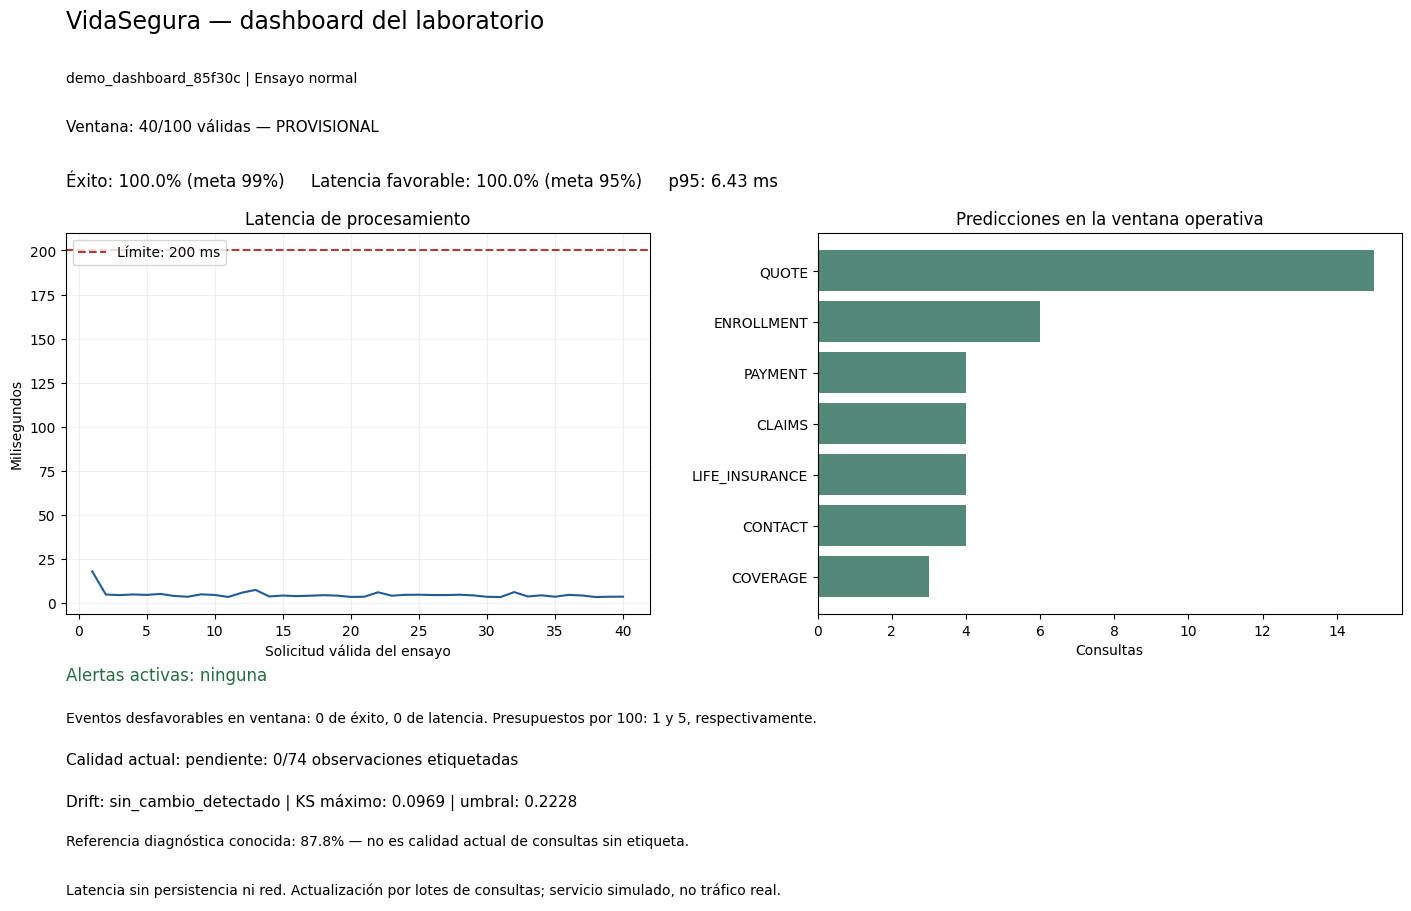

✅ Paso 16 completado: dashboard actualizado durante el ensayo normal.
🔄 Actualizaciones realizadas: 10, 20, 30 y 40 consultas.
📊 Ventana operativa provisional: 40/100; calidad actual sin etiquetas.
💾 Vista PNG, indicadores JSON y observaciones guardados en Drive.
➡️ Siguiente paso: preparar la respuesta automatizada de los incidentes.


In [25]:
# ============================================================
# 16.2 ENSAYO NORMAL DEL DASHBOARD
# ============================================================
# Propósito:
#   Comprobar la actualización durante el procesamiento.
#
# Procedimiento:
#   1. Procesar 40 consultas normales.
#   2. Evaluar señales y actualizar cada 10 solicitudes.
#   3. Guardar las observaciones con sus fechas.
#
# Resultado esperado:
#   Cuatro actualizaciones y evidencia PNG/JSON en Drive.
#   Este ensayo no cuenta como incidente formal.
# ============================================================

PANEL_DASHBOARD = None
ESCENARIO_DEMO = "demo_dashboard_" + uuid.uuid4().hex[:6]

REGISTROS_DEMO = []
TEXTOS_DEMO = []
EVENTOS_DEMO = []
ACTUALIZACIONES_DEMO = []

consultas_demo = (
    carga_operativa["consulta_es"].head(40).tolist()
)

for numero, texto in enumerate(consultas_demo, 1):
    REGISTROS_DEMO.append(
        procesar_consulta(
            texto, escenario=ESCENARIO_DEMO
        )
    )
    TEXTOS_DEMO.append(texto)

    if numero % 10 == 0:
        DRIFT_DEMO = detectar_drift(TEXTOS_DEMO)

        EVENTOS_DEMO.extend(
            evaluar_alertas(
                REGISTROS_DEMO,
                ESCENARIO_DEMO,
                DRIFT_DEMO,
            )
        )

        SNAPSHOT_DEMO = mostrar_dashboard(
            REGISTROS_DEMO,
            ESCENARIO_DEMO,
            DRIFT_DEMO,
            fase="Ensayo normal",
            guardar=(numero == len(consultas_demo)),
        )
        ACTUALIZACIONES_DEMO.append(SNAPSHOT_DEMO)

guardar_json(
    RUTAS["evidencias"] / f"{ESCENARIO_DEMO}_actualizaciones.json",
    {
        "consultas_procesadas": len(REGISTROS_DEMO),
        "actualizaciones_en": [10, 20, 30, 40],
        "actualizaciones": ACTUALIZACIONES_DEMO,
        "eventos_alertas": EVENTOS_DEMO,
        "nota": (
            "Ensayo normal de visualización; "
            "no es incidente formal."
        ),
    },
)

print("✅ Paso 16 completado: dashboard actualizado durante el ensayo normal.")
print("🔄 Actualizaciones realizadas: 10, 20, 30 y 40 consultas.")
print("📊 Ventana operativa provisional: 40/100; calidad actual sin etiquetas.")
print("💾 Vista PNG, indicadores JSON y observaciones guardados en Drive.")
print("➡️ Siguiente paso: preparar la respuesta automatizada de los incidentes.")

### 🧠 **17. Preparación de la respuesta automatizada**

**Objetivo:** preparar acciones correctivas para dos incidentes
controlados, conservando intacto el modelo original.

### **17.1 Incidente de latencia**
Introduciremos posteriormente una demora artificial de 300 ms.
Al detectar la alerta correspondiente, el servicio retirará
automáticamente esa demora.

### **17.2 Incidente de calidad**
Prepararemos una copia de V3 con una correspondencia incorrecta
entre índices y categorías, simulando un error de configuración.

Si se confirma la degradación mediante consultas etiquetadas,
la respuesta restaurará el modelo V3 estable en memoria.

### **17.3 Controles**
- Actuar únicamente sobre el escenario y fallo preparados.
- Ejecutar como máximo una corrección por ensayo.
- Registrar la alerta, acción, versión y hora.
- Comprobar después la recuperación mediante nuevas consultas.
- No cambiar el modelo automáticamente solo por detectar drift.

**Resultado esperado:** funciones preparadas y servicio normal.
Todavía no se activará ningún incidente formal.

Aplicar una corrección no demuestra recuperación:
esta deberá medirse en los siguientes pasos.

In [27]:
# ============================================================
# 17. PREPARACIÓN DE LA RESPUESTA AUTOMATIZADA
# ============================================================
# Propósito:
#   Preparar respuestas para incidentes controlados conservando
#   el modelo original y sin activar fallos todavía.
#
# Procedimiento:
#   1. Preparar una copia degradada únicamente en memoria.
#   2. Definir el servicio y el contexto de cada ensayo.
#   3. Vincular aperturas de alerta con acciones autorizadas.
#   4. Registrar inyecciones y acciones para auditarlas.
#
# Resultado esperado:
#   Funciones disponibles y servicio normal con V3 estable.
#   La recuperación se verificará durante los incidentes.
# ============================================================

import copy
import numpy as np
from datetime import datetime, timezone

if any(nombre not in globals() for nombre in [
    "MODELO_V3", "procesar_consulta", "evaluar_alertas"
]):
    raise RuntimeError("Completa los pasos anteriores.")

if globals().get("CONTEXTO_INCIDENTE", {}).get("activo"):
    raise RuntimeError(
        "Hay un ensayo activo; no reinicies su estado."
    )

# Simular un error de correspondencia entre índices y categorías.
# Se modifica solo esta copia: no el modelo original ni el ZIP.
MODELO_DEGRADADO = copy.deepcopy(MODELO_V3)

clasificador_copia = (
    MODELO_DEGRADADO.named_steps["clasificador"]
)
clasificador_copia.classes_ = np.roll(
    clasificador_copia.classes_.copy(), 1
)

SERVICIO_ACTIVO = {
    "modelo": MODELO_V3,
    "variante": "V3",
    "retardo_ms": 0,
}
CONTEXTO_INCIDENTE = {"activo": False}


def registrar_accion_servicio(evento, detalles):
    """
    Guarda un evento auditable del servicio.

    Parámetros:
        evento (str): acción o cambio observado.
        detalles (dict): información sin objetos del modelo.

    Retorna:
        dict guardado con hora UTC y contexto del ensayo.
    """
    registro = {
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "id_ejecucion": ID_EJECUCION,
        "escenario": CONTEXTO_INCIDENTE.get("escenario"),
        "tipo_incidente": CONTEXTO_INCIDENTE.get("tipo"),
        "evento": evento,
        **detalles,
    }

    anexar_jsonl(
        RUTAS["incidentes"] / "acciones_servicio.jsonl",
        [registro],
    )
    return registro


def preparar_incidente(escenario, tipo):
    """
    Prepara un ensayo en estado normal, sin inyectar el problema.

    Parámetros:
        escenario (str): identificador único del ensayo.
        tipo (str): latencia o calidad.

    Retorna:
        None. Prepara el contexto para antes/durante/después.
    """
    if CONTEXTO_INCIDENTE.get("activo"):
        raise RuntimeError(
            "Primero termina el ensayo activo."
        )

    if tipo not in {"latencia", "calidad"}:
        raise ValueError("Tipo de incidente no admitido.")

    archivo_modelo = (
        RUTA_ENTRENAMIENTO / METADATOS_V3["archivo"]
    )

    if calcular_sha256(archivo_modelo) != METADATOS_V3["sha256"]:
        raise ValueError(
            "La huella del modelo estable no coincide."
        )

    SERVICIO_ACTIVO.update(
        modelo=MODELO_V3, variante="V3", retardo_ms=0
    )

    CONTEXTO_INCIDENTE.clear()
    CONTEXTO_INCIDENTE.update({
        "activo": True,
        "escenario": escenario,
        "tipo": tipo,
        "fase": "antes",
        "inyeccion_confirmada": False,
        "accion_ejecutada": False,
        "inicio_fallo_utc": None,
    })

    registrar_accion_servicio(
        "PREPARACION_ENSAYO", {"variante": "V3"}
    )


def inyectar_incidente():
    """
    Activa la demora o la copia con categorías desordenadas.

    Parámetros:
        Ninguno. Utiliza el contexto previamente preparado.

    Retorna:
        None. Guarda la hora y causa de la simulación.
    """
    if not CONTEXTO_INCIDENTE.get("activo"):
        raise RuntimeError("Primero prepara el incidente.")

    if CONTEXTO_INCIDENTE["inyeccion_confirmada"]:
        raise RuntimeError(
            "No se permite repetir la inyección en el mismo ensayo."
        )

    if CONTEXTO_INCIDENTE["tipo"] == "latencia":
        SERVICIO_ACTIVO["retardo_ms"] = 300
        causa = "Demora artificial de 300 ms por solicitud"
    else:
        SERVICIO_ACTIVO.update(
            modelo=MODELO_DEGRADADO,
            variante="V3_etiquetas_desordenadas_simulada",
        )
        causa = (
            "Correspondencia de categorías alterada en una copia"
        )

    CONTEXTO_INCIDENTE.update({
        "fase": "durante",
        "inyeccion_confirmada": True,
        "inicio_fallo_utc": datetime.now(timezone.utc).isoformat(),
    })

    registrar_accion_servicio(
        "INYECCION_CONTROLADA",
        {
            "causa": causa,
            "inicio_fallo_utc": (
                CONTEXTO_INCIDENTE["inicio_fallo_utc"]
            ),
            "variante": SERVICIO_ACTIVO["variante"],
        },
    )


def atender_consulta_servicio(texto, categoria_real=None):
    """
    Procesa una consulta con la configuración activa.

    Parámetros:
        texto (str): consulta que se atenderá.
        categoria_real: etiqueta correcta o None.

    Retorna:
        dict de inferencia con fase del ensayo.
        Registra el vínculo entre solicitud, variante y fase.
    """
    escenario = (
        CONTEXTO_INCIDENTE.get("escenario")
        or "servicio_normal"
    )
    fase = CONTEXTO_INCIDENTE.get("fase", "normal")

    resultado = procesar_consulta(
        texto,
        categoria_real=categoria_real,
        escenario=escenario,
        modelo=SERVICIO_ACTIVO["modelo"],
        variante=SERVICIO_ACTIVO["variante"],
        retardo_ms=SERVICIO_ACTIVO["retardo_ms"],
    )
    resultado["fase"] = fase

    anexar_jsonl(
        RUTAS["incidentes"] / "contexto_solicitudes.jsonl",
        [{
            "request_id": resultado["request_id"],
            "escenario": escenario,
            "fase": fase,
            "variante": SERVICIO_ACTIVO["variante"],
        }],
    )

    return resultado


def responder_alertas(eventos):
    """
    Aplica una corrección por ensayo controlado confirmado.

    Parámetros:
        eventos (list): salida de evaluar_alertas.

    Retorna:
        list de acciones registradas.

    Controles:
        Actúa solo ante una apertura del escenario y tipo preparados.
        No declara recuperación ni modifica casos desconocidos.
    """
    acciones = []

    for alerta in eventos:
        if alerta["evento"] != "APERTURA":
            continue

        autorizado = (
            CONTEXTO_INCIDENTE.get("activo")
            and CONTEXTO_INCIDENTE.get("inyeccion_confirmada")
            and alerta["escenario"]
            == CONTEXTO_INCIDENTE.get("escenario")
            and alerta["tipo"]
            == CONTEXTO_INCIDENTE.get("tipo")
        )

        if not autorizado:
            registrar_accion_servicio(
                "REVISION_REQUERIDA",
                {
                    "alerta_id": alerta["alerta_id"],
                    "motivo": (
                        "No corresponde a la inyección controlada; "
                        "sin cambio automático."
                    ),
                },
            )
            continue

        if CONTEXTO_INCIDENTE["accion_ejecutada"]:
            continue

        anterior = SERVICIO_ACTIVO["variante"]

        if (
            alerta["tipo"] == "latencia"
            and SERVICIO_ACTIVO["retardo_ms"] > 0
        ):
            SERVICIO_ACTIVO["retardo_ms"] = 0
            accion = "RETIRAR_RETARDO"

        elif (
            alerta["tipo"] == "calidad"
            and anterior == "V3_etiquetas_desordenadas_simulada"
        ):
            SERVICIO_ACTIVO.update(
                modelo=MODELO_V3,
                variante="V3",
                retardo_ms=0,
            )
            accion = "ROLLBACK_V3_ESTABLE"

        else:
            continue

        CONTEXTO_INCIDENTE.update({
            "accion_ejecutada": True,
            "fase": "recuperacion",
            "deteccion_utc": alerta["timestamp_utc"],
            "accion_utc": datetime.now(timezone.utc).isoformat(),
        })

        acciones.append(
            registrar_accion_servicio(
                "ACCION_AUTOMATICA",
                {
                    "accion": accion,
                    "alerta_id": alerta["alerta_id"],
                    "runbook": alerta["runbook"],
                    "variante_anterior": anterior,
                    "variante_nueva": SERVICIO_ACTIVO["variante"],
                    "estado": (
                        "Corrección aplicada; "
                        "validación de recuperación pendiente."
                    ),
                },
            )
        )

    return acciones


# Comprobar que la copia no alteró el modelo estable.
assert list(MODELO_V3.classes_) == METADATOS_V3["categorias"]
assert not np.array_equal(
    MODELO_V3.classes_, MODELO_DEGRADADO.classes_
)

guardar_json(
    RUTAS["configuracion"] / "respuesta_automatizada.json",
    {
        "acciones": [
            "RETIRAR_RETARDO",
            "ROLLBACK_V3_ESTABLE",
        ],
        "condicion": (
            "Apertura del escenario y tipo "
            "de una inyección confirmada."
        ),
        "maximo_acciones_por_ensayo": 1,
        "modelo_original_modificado": False,
        "validacion_recuperacion": (
            "Se realizará con consultas posteriores a la acción."
        ),
        "limite": (
            "Laboratorio controlado; otros errores "
            "requieren revisión del operador."
        ),
    },
)

print("✅ Paso 17 completado: respuesta automatizada preparada.")
print("🧠 Servicio activo: V3 estable, sin retardo artificial.")
print("🧪 Copia degradada preparada en memoria, todavía no activada.")
print("🔒 Correcciones limitadas a la inyección y escenario confirmados.")
print("💾 Configuración guardada; las acciones quedarán auditadas al ejecutarse.")
print("ℹ️ Aún no se ha simulado ningún incidente formal.")
print("➡️ Siguiente paso: incidente 1, latencia y recuperación automática.")

✅ Paso 17 completado: respuesta automatizada preparada.
🧠 Servicio activo: V3 estable, sin retardo artificial.
🧪 Copia degradada preparada en memoria, todavía no activada.
🔒 Correcciones limitadas a la inyección y escenario confirmados.
💾 Configuración guardada; las acciones quedarán auditadas al ejecutarse.
ℹ️ Aún no se ha simulado ningún incidente formal.
➡️ Siguiente paso: incidente 1, latencia y recuperación automática.


## 🧠 **18. Incidente 1: aumento de latencia y recuperación automática**

**Objetivo:** demostrar detección, ejecución del runbook,
corrección automática y recuperación medida.

### **18.1 Antes**
Procesaremos 100 solicitudes sin alterar el servicio.

### **18.2 Durante**
Introduciremos una demora artificial de 300 ms por solicitud.
El motor detectará el consumo acelerado del presupuesto de latencia.

La respuesta automática retirará el retardo cuando se produzca
la alerta correspondiente. Guardaremos el diagnóstico y la acción.

### **18.3 Después**
Procesaremos 100 solicitudes nuevas reutilizando la misma carga.
Comprobaremos los objetivos de latencia y éxito técnico y el cierre
de la alerta.

### **18.4 Evidencias**
Guardaremos mediciones, eventos, acción, imágenes del dashboard
y tiempos de detección y recuperación. Registraremos el incidente
en MLflow y generaremos un nuevo respaldo.

Los tiempos corresponden a este ensayo individual: no son promedios.
Incluyen el procesamiento del ensayo y su observabilidad.

**Resultado esperado:** incidente detectado, corregido y recuperación
verificada con datos posteriores a la acción.

La demora es una inyección controlada del laboratorio, no un fallo
real del modelo ni tráfico de clientes.

In [28]:
# ============================================================
# 18.1 FUNCIONES PARA EJECUTAR Y DOCUMENTAR INCIDENTES
# ============================================================
# Propósito:
#   Procesar fases, medir resultados y conservar evidencias.
#
# Resultado esperado:
#   Funciones reutilizables para los dos incidentes.
#   Esta celda todavía no activa ninguna falla.
# ============================================================

from datetime import datetime, timezone
from IPython.display import display
import pandas as pd
import numpy as np
import uuid
import copy
import subprocess
import sys
import json


def resumir_fase_incidente(registros):
    """
    Resume las mediciones reales de una fase.

    Parámetros:
        registros: solicitudes procesadas durante esa fase.

    Retorna:
        dict con operación, latencia y calidad si hay etiquetas.
    """
    validas = [
        r for r in registros if r["solicitud_valida"]
    ]
    if not validas:
        raise ValueError("La fase no tiene solicitudes válidas.")

    etiquetadas = [
        r for r in validas
        if r.get("categoria_real") is not None
    ]

    resumen = {
        "solicitudes": len(validas),
        "exito_tecnico": sum(
            r["exito_tecnico"] for r in validas
        ) / len(validas),
        "latencia_favorable": sum(
            r["latencia_favorable"] for r in validas
        ) / len(validas),
        "latencia_p95_ms": float(np.percentile(
            [r["latencia_ms"] for r in validas], 95
        )),
        "exactitud": None,
        "f1_macro": None,
    }

    if etiquetadas:
        from sklearn.metrics import f1_score

        resumen["exactitud"] = sum(
            r.get("acierto") is True for r in etiquetadas
        ) / len(etiquetadas)

        resumen["f1_macro"] = float(f1_score(
            [r["categoria_real"] for r in etiquetadas],
            [
                r["categoria"] or "SIN_PREDICCION"
                for r in etiquetadas
            ],
            labels=METADATOS_V3["categorias"],
            average="macro",
            zero_division=0,
        ))

    return resumen


def ejecutar_bloque_incidente(
    textos,
    etiquetas,
    historial,
    textos_historial,
    eventos,
    acciones,
    nombre_fase,
    detener_tras_accion=False,
    diferir_respuesta=False,
):
    """
    Procesa un bloque y aplica la respuesta habilitada.

    Parámetros:
        textos: consultas del bloque.
        etiquetas: categorías correctas o None.
        historial/textos_historial: listas acumuladas del ensayo.
        eventos/acciones: listas donde se conservarán resultados.
        nombre_fase: etiqueta del dashboard.
        detener_tras_accion: terminar al aplicar la corrección.
        diferir_respuesta: completar el diagnóstico antes de corregir.

    Retorna:
        Lista de mediciones de la fase.

    Nota:
        Un fallo interno no previsto interrumpe el ensayo.
    """
    escenario = CONTEXTO_INCIDENTE["escenario"]
    resultados = []
    eventos_bloque = []

    for i, texto in enumerate(textos):
        referencia = (
            None if etiquetas is None else etiquetas[i]
        )
        resultado = atender_consulta_servicio(
            texto, referencia
        )

        resultados.append(resultado)
        historial.append(resultado)
        textos_historial.append(texto)

        if not resultado["exito_tecnico"]:
            raise RuntimeError(
                "Fallo interno no previsto: "
                + str(resultado["tipo_error"])
            )

        drift = detectar_drift(textos_historial)
        nuevos = evaluar_alertas(
            historial, escenario, drift
        )
        eventos.extend(nuevos)
        eventos_bloque.extend(nuevos)

        apertura_objetivo = [
            evento for evento in nuevos
            if (
                evento["evento"] == "APERTURA"
                and evento["tipo"] == CONTEXTO_INCIDENTE["tipo"]
            )
        ]

        # Documentar el diagnóstico antes de aplicar la corrección.
        if apertura_objetivo:
            for alerta in apertura_objetivo:
                registrar_accion_servicio(
                    "RUNBOOK_DIAGNOSTICO",
                    {
                        "runbook": alerta["runbook"],
                        "alerta_id": alerta["alerta_id"],
                        "metricas": alerta["metricas"],
                        "inyeccion_confirmada": (
                            CONTEXTO_INCIDENTE["inyeccion_confirmada"]
                        ),
                        "variante": SERVICIO_ACTIVO["variante"],
                        "retardo_ms": SERVICIO_ACTIVO["retardo_ms"],
                    },
                )

            mostrar_dashboard(
                historial, escenario, drift,
                fase=nombre_fase, guardar=True,
            )

        aplicadas = (
            [] if diferir_respuesta
            else responder_alertas(nuevos)
        )
        acciones.extend(aplicadas)

        if (i + 1) % 20 == 0:
            mostrar_dashboard(
                historial, escenario, drift,
                fase=nombre_fase,
            )
            print(
                f"   {nombre_fase}: {i + 1} consultas.",
                flush=True,
            )

        if detener_tras_accion and aplicadas:
            break

    mostrar_dashboard(
        historial,
        escenario,
        detectar_drift(textos_historial),
        fase=nombre_fase,
        guardar=True,
    )

    if diferir_respuesta:
        acciones.extend(
            responder_alertas(eventos_bloque)
        )

    return resultados


def registrar_incidente_mlflow(escenario, resumen, carpeta):
    """
    Registra fases y evidencias en el experimento existente.

    Parámetros:
        escenario (str): identificador del incidente.
        resumen (dict): mediciones de las fases y recuperación.
        carpeta (Path): ubicación de sus evidencias.

    Retorna:
        dict con run_id y métricas recuperadas y verificadas.

    Nota:
        No repite inferencias ni entrenamiento.
    """
    especificacion = copy.deepcopy(
        ESPECIFICACION_BASELINE
    )
    especificacion["nombre_run"] = escenario
    especificacion["etiquetas"].update(
        tipo="incidente_controlado",
        escenario=escenario,
    )

    especificacion["metricas"] = {
        fase + "_" + clave: valor
        for fase, valores in resumen["fases"].items()
        for clave, valor in valores.items()
        if valor is not None
    }

    especificacion["metricas"].update({
        "tiempo_deteccion_s": resumen["tiempo_deteccion_s"],
        "tiempo_recuperacion_validada_s": (
            resumen["tiempo_recuperacion_validada_s"]
        ),
        "acciones_automaticas": resumen["acciones_automaticas"],
        "duplicados_suprimidos": resumen["duplicados_suprimidos"],
    })

    especificacion["archivos"] = [
        {"ruta": str(archivo), "grupo": "incidente"}
        for archivo in carpeta.iterdir()
        if archivo.is_file()
    ] + [
        {
            "ruta": str(
                RUTA_RUNBOOKS / resumen["runbook"]
            ),
            "grupo": "runbook",
        }
    ]

    prefijo = "dashboard_" + escenario + "_"
    especificacion["archivos"] += [
        {"ruta": str(archivo), "grupo": "dashboard"}
        for archivo in RUTAS["evidencias"].glob(
            prefijo + "*.png"
        )
    ]

    entrada = carpeta / "mlflow_entrada.json"
    salida = carpeta / "mlflow_registro.json"
    guardar_json(entrada, especificacion)

    proceso = subprocess.run(
        [
            sys.executable,
            str(RUTA_REGISTRADOR_MLFLOW),
            str(entrada),
            str(salida),
        ],
        env=ENTORNO_MLFLOW,
        capture_output=True,
        text=True,
    )

    (carpeta / "mlflow_salida.txt").write_text(
        proceso.stdout + "\n" + proceso.stderr,
        encoding="utf-8",
    )

    if proceso.returncode != 0:
        raise RuntimeError(
            "Incidente guardado, pero registro MLflow pendiente:\n"
            + proceso.stderr[-3000:]
        )

    return json.loads(
        salida.read_text(encoding="utf-8")
    )


print("✅ Paso 18.1 completado: funciones del ensayo preparadas.")
print("➡️ Ejecuta la siguiente celda para iniciar el incidente 1.")

✅ Paso 18.1 completado: funciones del ensayo preparadas.
➡️ Ejecuta la siguiente celda para iniciar el incidente 1.


⏳ Fase 1: midiendo 100 consultas antes de la falla...


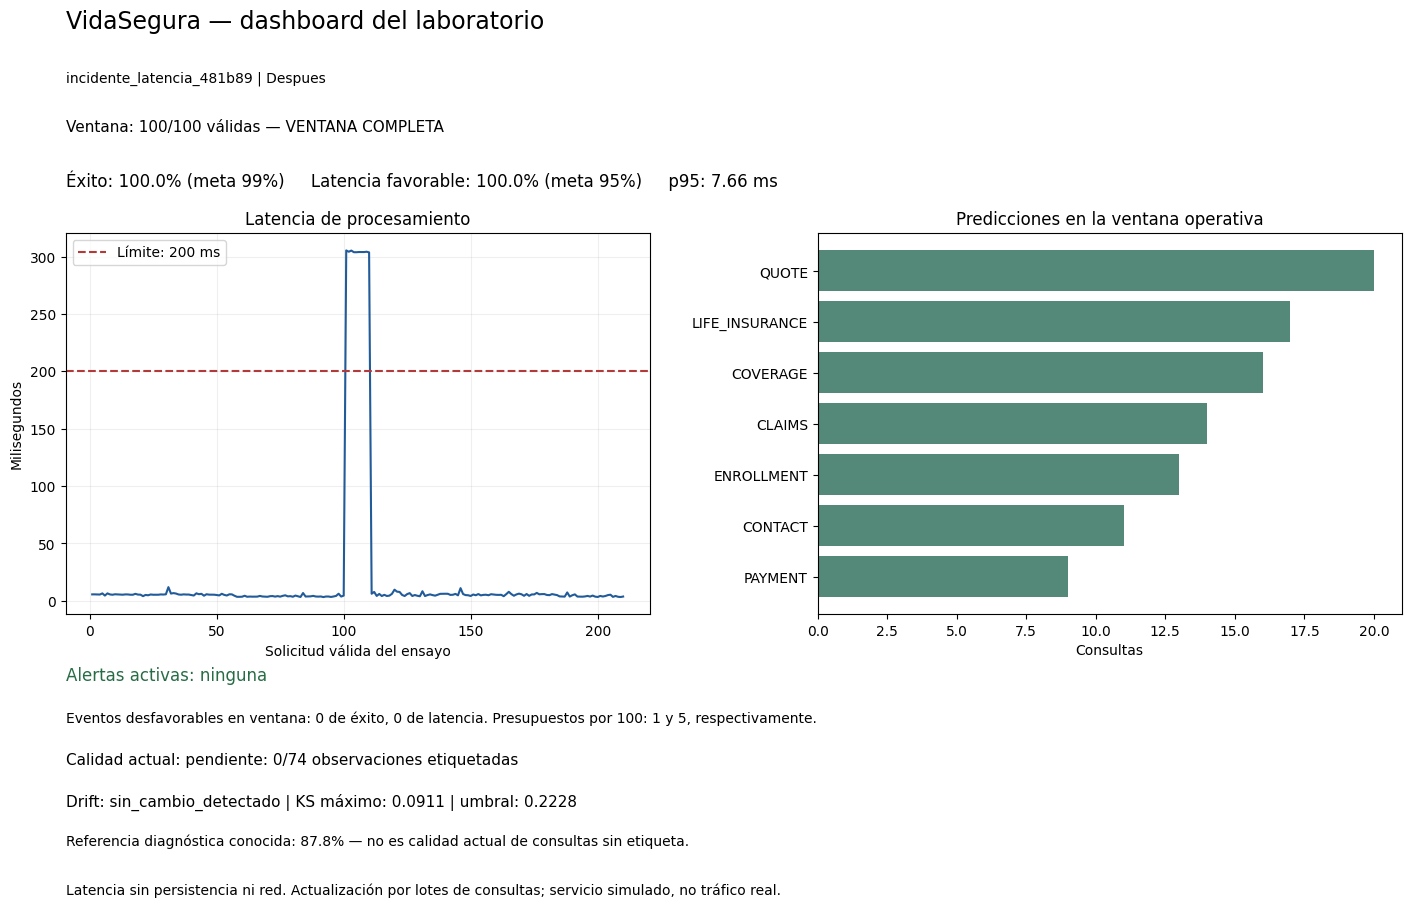

   Antes: 20 consultas.
   Antes: 40 consultas.
   Antes: 60 consultas.
   Antes: 80 consultas.
   Antes: 100 consultas.
⏳ Fase 2: inyectando 300 ms y esperando la respuesta...
⏳ Fase 3: verificando recuperación con 100 solicitudes...
   Despues: 20 consultas.
   Despues: 40 consultas.
   Despues: 60 consultas.
   Despues: 80 consultas.
   Despues: 100 consultas.
✅ Paso 18 completado: incidente 1 detectado, corregido y recuperación verificada.


,solicitudes,exito_tecnico,latencia_favorable,latencia_p95_ms
antes,100.0,1.0,1.0,6.3805
durante,10.0,1.0,0.0,305.3031
despues,100.0,1.0,1.0,7.6556


🛠️ Acción automática: RETIRAR_RETARDO
🔕 Duplicados suprimidos: 18
⏱️ Tiempo de detección: 3.33 s
⏱️ Recuperación validada: 14.25 s
🧪 MLflow run: d340f9f8937e4a3da702b8a7dfff1e17
📁 Evidencias: /content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/asistente-seguros-ia/Actividad8/resultados/act8_20261115T183737Z_2601a7/incidentes/incidente_latencia_481b89
➡️ Siguiente paso: incidente 2, degradación de calidad y rollback a V3.


In [29]:
# ============================================================
# 18.2 INCIDENTE 1: LATENCIA Y RECUPERACIÓN AUTOMÁTICA
# ============================================================
# Propósito:
#   Ejecutar y documentar el ciclo completo del incidente.
#
# Procedimiento:
#   1. Medir 100 solicitudes antes de la falla.
#   2. Inyectar 300 ms y esperar alerta y corrección.
#   3. Verificar recuperación con 100 solicitudes posteriores.
#   4. Guardar evidencia, registrar MLflow y respaldarlo.
#
# Resultado esperado:
#   Recuperación comprobada, alerta cerrada y una sola corrección.
# ============================================================

ESCENARIO_LATENCIA = (
    "incidente_latencia_" + uuid.uuid4().hex[:6]
)
CARPETA_LATENCIA = (
    RUTAS["incidentes"] / ESCENARIO_LATENCIA
)
CARPETA_LATENCIA.mkdir(exist_ok=False)

PANEL_DASHBOARD = None
HISTORIAL_LATENCIA = []
TEXTOS_LATENCIA = []
EVENTOS_LATENCIA = []
ACCIONES_LATENCIA = []

consultas_latencia = (
    carga_operativa["consulta_es"].tolist()
)
suprimidos_iniciales = (
    MEMORIA_ALERTAS["duplicados_suprimidos"]
)

preparar_incidente(ESCENARIO_LATENCIA, "latencia")

try:
    print(
        "⏳ Fase 1: midiendo 100 consultas antes de la falla...",
        flush=True,
    )
    antes_latencia = ejecutar_bloque_incidente(
        consultas_latencia, None,
        HISTORIAL_LATENCIA, TEXTOS_LATENCIA,
        EVENTOS_LATENCIA, ACCIONES_LATENCIA,
        "Antes",
    )

    print(
        "⏳ Fase 2: inyectando 300 ms y esperando la respuesta...",
        flush=True,
    )
    inyectar_incidente()

    durante_latencia = ejecutar_bloque_incidente(
        consultas_latencia, None,
        HISTORIAL_LATENCIA, TEXTOS_LATENCIA,
        EVENTOS_LATENCIA, ACCIONES_LATENCIA,
        "Durante",
        detener_tras_accion=True,
    )

    if not CONTEXTO_INCIDENTE["accion_ejecutada"]:
        raise RuntimeError(
            "No se aplicó la respuesta automática esperada."
        )

    print(
        "⏳ Fase 3: verificando recuperación con 100 solicitudes...",
        flush=True,
    )
    despues_latencia = ejecutar_bloque_incidente(
        consultas_latencia, None,
        HISTORIAL_LATENCIA, TEXTOS_LATENCIA,
        EVENTOS_LATENCIA, ACCIONES_LATENCIA,
        "Despues",
    )

    fases_latencia = {
        "antes": resumir_fase_incidente(antes_latencia),
        "durante": resumir_fase_incidente(durante_latencia),
        "despues": resumir_fase_incidente(despues_latencia),
    }

    despues = fases_latencia["despues"]
    regla_latencia = REGLAS_ALERTAS["latencia"]

    estado_regla = MEMORIA_ALERTAS["reglas"][
        ESCENARIO_LATENCIA + "::" + regla_latencia["id"]
    ]

    recuperado = (
        despues["solicitudes"] == 100
        and despues["exito_tecnico"] >= .99 - 1e-12
        and despues["latencia_favorable"] >= .95 - 1e-12
        and not estado_regla["activa"]
        and SERVICIO_ACTIVO["retardo_ms"] == 0
    )

    if not recuperado:
        raise RuntimeError(
            "La corrección se aplicó, pero la recuperación "
            "no cumplió todos los criterios."
        )

    validacion_utc = datetime.now(timezone.utc)
    inicio = datetime.fromisoformat(
        CONTEXTO_INCIDENTE["inicio_fallo_utc"]
    )
    deteccion = datetime.fromisoformat(
        CONTEXTO_INCIDENTE["deteccion_utc"]
    )

    RESUMEN_INCIDENTE_LATENCIA = {
        "escenario": ESCENARIO_LATENCIA,
        "tipo": "latencia",
        "runbook": "RB01_LATENCIA.md",
        "causa": "Retardo artificial de 300 ms",
        "fases": fases_latencia,
        "recuperacion_confirmada": recuperado,
        "inicio_fallo_utc": inicio.isoformat(),
        "deteccion_utc": deteccion.isoformat(),
        "validacion_utc": validacion_utc.isoformat(),
        "tiempo_deteccion_s": (
            deteccion - inicio
        ).total_seconds(),
        "tiempo_recuperacion_validada_s": (
            validacion_utc - inicio
        ).total_seconds(),
        "acciones_automaticas": len(ACCIONES_LATENCIA),
        "duplicados_suprimidos": (
            MEMORIA_ALERTAS["duplicados_suprimidos"]
            - suprimidos_iniciales
        ),
        "nota_tiempos": (
            "Una observación por incidente, no promedios. "
            "Incluye el ensayo y su observabilidad."
        ),
    }

    registrar_accion_servicio(
        "RUNBOOK_VALIDACION",
        {
            "runbook": "RB01_LATENCIA.md",
            "recuperacion_confirmada": recuperado,
            "metricas_despues": despues,
        },
    )

    guardar_json(
        CARPETA_LATENCIA / "resumen_incidente.json",
        RESUMEN_INCIDENTE_LATENCIA,
    )
    guardar_json(
        CARPETA_LATENCIA / "eventos_alertas.json",
        EVENTOS_LATENCIA,
    )
    guardar_json(
        CARPETA_LATENCIA / "acciones_automaticas.json",
        ACCIONES_LATENCIA,
    )

    pd.DataFrame(HISTORIAL_LATENCIA).to_csv(
        CARPETA_LATENCIA / "solicitudes_incidente.csv",
        index=False,
        encoding="utf-8-sig",
    )

except Exception as error:
    # Restauración preventiva si el ensayo se interrumpe.
    # No se presenta como recuperación validada.
    SERVICIO_ACTIVO.update(
        modelo=MODELO_V3, variante="V3", retardo_ms=0
    )
    registrar_accion_servicio(
        "ENSAYO_INTERRUMPIDO",
        {
            "tipo_error": type(error).__name__,
            "restauracion_preventiva": True,
            "nota": (
                "No se declara recuperación validada "
                "ni incidente completado."
            ),
        },
    )
    raise

finally:
    CONTEXTO_INCIDENTE["activo"] = False

# Registrar los resultados ya obtenidos, sin repetir consultas.
REGISTRO_MLFLOW_LATENCIA = registrar_incidente_mlflow(
    ESCENARIO_LATENCIA,
    RESUMEN_INCIDENTE_LATENCIA,
    CARPETA_LATENCIA,
)

RESPALDO_MLFLOW = respaldar_mlflow()

guardar_json(
    CARPETA_LATENCIA / "respaldo_mlflow.json",
    {"ruta": str(RESPALDO_MLFLOW)},
)

print("✅ Paso 18 completado: incidente 1 detectado, corregido y recuperación verificada.")

display(
    pd.DataFrame(fases_latencia).T[[
        "solicitudes",
        "exito_tecnico",
        "latencia_favorable",
        "latencia_p95_ms",
    ]].round(4)
)

print("🛠️ Acción automática:", ACCIONES_LATENCIA[0]["accion"])
print("🔕 Duplicados suprimidos:", RESUMEN_INCIDENTE_LATENCIA["duplicados_suprimidos"])
print(f"⏱️ Tiempo de detección: {RESUMEN_INCIDENTE_LATENCIA['tiempo_deteccion_s']:.2f} s")
print(f"⏱️ Recuperación validada: {RESUMEN_INCIDENTE_LATENCIA['tiempo_recuperacion_validada_s']:.2f} s")
print("🧪 MLflow run:", REGISTRO_MLFLOW_LATENCIA["run_id"])
print("📁 Evidencias:", CARPETA_LATENCIA)
print("➡️ Siguiente paso: incidente 2, degradación de calidad y rollback a V3.")

### 🧠 **19. Incidente 2: degradación de calidad y rollback a V3**

**Objetivo:** detectar pérdida de exactitud, restaurar V3 estable
y comprobar que recupera sus predicciones anteriores.

### **19.1 Antes de la falla**
Evaluaremos las 74 preguntas etiquetadas con V3 estable.

### **19.2 Durante la falla**
Activaremos la copia con categorías desordenadas y evaluaremos
las mismas 74 preguntas, sin cambiar sus etiquetas correctas.

La alerta puede abrirse antes, pero completaremos el bloque
diagnóstico antes de aplicar el rollback automático.

### **19.3 Después del rollback**
Repetiremos las 74 preguntas con V3 restaurada y comprobaremos:

- Exactitud mínima del 80 %.
- Predicciones iguales a las obtenidas antes de la falla.
- Atención sin fallos internos.
- Cierre de la alerta de calidad.
- Archivo del modelo original sin modificaciones.

### **19.4 Diferencia entre calidad y drift**
Las preguntas del Excel pueden activar una alerta de drift
porque su redacción difiere de la referencia sintética.

Restaurar el modelo no cambia las entradas. Por eso, una señal
de drift puede permanecer para revisión aunque la calidad
se haya recuperado. No la cerraremos artificialmente.

**Resultado esperado:** degradación y rollback demostrados,
con evidencias antes/durante/después y registro en MLflow.

Son consultas conocidas de diagnóstico, no una prueba ciega.
En producción, medir exactitud requiere obtener etiquetas correctas.

⏳ Fase 1: evaluando 74 preguntas con V3 estable...


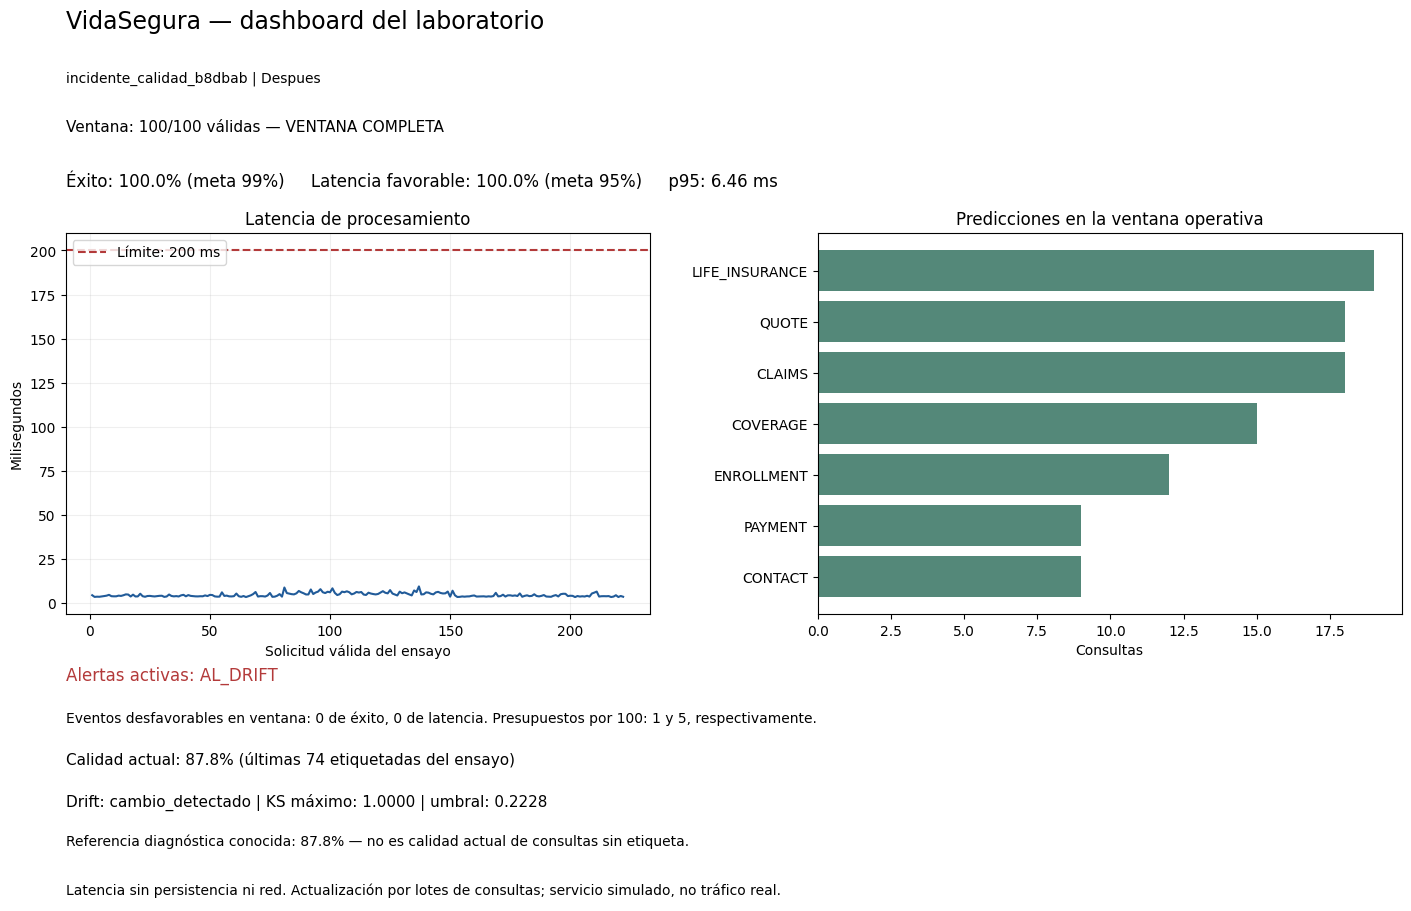

   Antes: 20 consultas.
   Antes: 40 consultas.
   Antes: 60 consultas.
⏳ Fase 2: activando la copia degradada y completando el diagnóstico...
   Durante: 20 consultas.
   Durante: 40 consultas.
   Durante: 60 consultas.
⏳ Fase 3: comprobando las 74 preguntas con V3 restaurada...
   Despues: 20 consultas.
   Despues: 40 consultas.
   Despues: 60 consultas.
✅ Paso 19 completado: incidente 2 detectado y rollback verificado.


,solicitudes,exito_tecnico,exactitud,f1_macro
antes,74.0,1.0,0.8784,0.8762
durante,74.0,1.0,0.0135,0.0168
despues,74.0,1.0,0.8784,0.8762


🛠️ Acción automática: ROLLBACK_V3_ESTABLE
🔁 Predicciones anteriores recuperadas: True
🔕 Duplicados suprimidos: 318
⏱️ Tiempo de detección: 0.21 s
⏱️ Recuperación validada: 14.11 s
🔎 Drift final: cambio_detectado
ℹ️ La señal de drift puede continuar: las entradas no cambian al restaurar el modelo.
🧪 MLflow run: 4496fa585030405283b224226e749b6d
📁 Evidencias: /content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/asistente-seguros-ia/Actividad8/resultados/act8_20261115T183737Z_2601a7/incidentes/incidente_calidad_b8dbab
➡️ Siguiente paso: consolidar y verificar las evidencias de la actividad.


In [30]:
# ============================================================
# 19. INCIDENTE 2: DEGRADACIÓN DE CALIDAD Y ROLLBACK
# ============================================================
# Propósito:
#   Detectar pérdida de exactitud, restaurar V3 estable y
#   comprobar que recupera las predicciones anteriores.
#
# Procedimiento:
#   1. Evaluar 74 preguntas con V3 estable.
#   2. Evaluar las mismas 74 con la copia degradada.
#   3. Aplicar rollback al completar el diagnóstico.
#   4. Repetir 74 con V3 restaurada y verificar recuperación.
#   5. Guardar resultados, registrar MLflow y respaldarlo.
#
# Resultado esperado:
#   Recuperación demostrada sin reentrenar el modelo.
# ============================================================

# Verificación previa separada del incidente formal.
# Comprobar que las variantes simuladas se identifican en los logs.
comprobacion_bandera = procesar_consulta(
    CONSULTA_EJEMPLO,
    modelo=MODELO_DEGRADADO,
    variante="V3_etiquetas_desordenadas_simulada",
    escenario="verificacion_bandera_calidad",
)

if not comprobacion_bandera["simulacion_activa"]:
    raise RuntimeError(
        "Actualiza simulacion_activa del paso 8 "
        "como se indicó en el paso 17 y ejecuta esa celda "
        "antes de continuar."
    )

# Crear un escenario independiente, sin sobrescribir el incidente 1.
ESCENARIO_CALIDAD = (
    "incidente_calidad_" + uuid.uuid4().hex[:6]
)
CARPETA_CALIDAD = (
    RUTAS["incidentes"] / ESCENARIO_CALIDAD
)
CARPETA_CALIDAD.mkdir(exist_ok=False)

PANEL_DASHBOARD = None
HISTORIAL_CALIDAD = []
TEXTOS_CALIDAD = []
EVENTOS_CALIDAD = []
ACCIONES_CALIDAD = []

datos_calidad = pd.read_csv(
    RUTA_INSUMOS / "referencia_humana_74.csv",
    keep_default_na=False,
)

assert len(datos_calidad) == 74
assert datos_calidad["id"].is_unique

consultas_calidad = datos_calidad["pregunta"].tolist()
etiquetas_calidad = (
    datos_calidad["categoria_referencia"].tolist()
)
suprimidos_iniciales = (
    MEMORIA_ALERTAS["duplicados_suprimidos"]
)

preparar_incidente(ESCENARIO_CALIDAD, "calidad")

try:
    print(
        "⏳ Fase 1: evaluando 74 preguntas con V3 estable...",
        flush=True,
    )
    antes_calidad = ejecutar_bloque_incidente(
        consultas_calidad,
        etiquetas_calidad,
        HISTORIAL_CALIDAD,
        TEXTOS_CALIDAD,
        EVENTOS_CALIDAD,
        ACCIONES_CALIDAD,
        "Antes",
    )

    print(
        "⏳ Fase 2: activando la copia degradada "
        "y completando el diagnóstico...",
        flush=True,
    )
    inyectar_incidente()

    durante_calidad = ejecutar_bloque_incidente(
        consultas_calidad,
        etiquetas_calidad,
        HISTORIAL_CALIDAD,
        TEXTOS_CALIDAD,
        EVENTOS_CALIDAD,
        ACCIONES_CALIDAD,
        "Durante",
        diferir_respuesta=True,
    )

    if not CONTEXTO_INCIDENTE["accion_ejecutada"]:
        raise RuntimeError(
            "No se aplicó el rollback automático esperado."
        )

    print(
        "⏳ Fase 3: comprobando las 74 preguntas "
        "con V3 restaurada...",
        flush=True,
    )
    despues_calidad = ejecutar_bloque_incidente(
        consultas_calidad,
        etiquetas_calidad,
        HISTORIAL_CALIDAD,
        TEXTOS_CALIDAD,
        EVENTOS_CALIDAD,
        ACCIONES_CALIDAD,
        "Despues",
    )

    # Asociar las mediciones con los IDs originales,
    # sin guardar el texto completo en estos registros.
    for fase in [
        antes_calidad, durante_calidad, despues_calidad
    ]:
        assert len(fase) == 74

        for registro, identificador in zip(
            fase, datos_calidad["id"]
        ):
            registro["id_pregunta"] = identificador

    fases_calidad = {
        "antes": resumir_fase_incidente(antes_calidad),
        "durante": resumir_fase_incidente(durante_calidad),
        "despues": resumir_fase_incidente(despues_calidad),
    }

    despues = fases_calidad["despues"]

    predicciones_restauradas = (
        [r["categoria"] for r in antes_calidad]
        == [r["categoria"] for r in despues_calidad]
    )

    estado_regla = MEMORIA_ALERTAS["reglas"][
        ESCENARIO_CALIDAD + "::AL_CALIDAD"
    ]

    recuperado = (
        despues["solicitudes"] == 74
        and despues["exactitud"]
        >= POLITICA_OBSERVABILIDAD["calidad"]["objetivo"]
        and despues["exito_tecnico"] >= .99 - 1e-12
        and predicciones_restauradas
        and not estado_regla["activa"]
        and SERVICIO_ACTIVO["modelo"] is MODELO_V3
        and SERVICIO_ACTIVO["variante"] == "V3"
    )

    if not recuperado:
        raise RuntimeError(
            "El rollback se aplicó, pero no se confirmó "
            "toda la recuperación."
        )

    # Comprobar que el archivo original permanece intacto.
    assert calcular_sha256(
        RUTA_ENTRENAMIENTO / METADATOS_V3["archivo"]
    ) == METADATOS_V3["sha256"]

    validacion_utc = datetime.now(timezone.utc)
    inicio = datetime.fromisoformat(
        CONTEXTO_INCIDENTE["inicio_fallo_utc"]
    )
    deteccion = datetime.fromisoformat(
        CONTEXTO_INCIDENTE["deteccion_utc"]
    )
    DRIFT_FINAL_CALIDAD = detectar_drift(TEXTOS_CALIDAD)

    RESUMEN_INCIDENTE_CALIDAD = {
        "escenario": ESCENARIO_CALIDAD,
        "tipo": "calidad",
        "runbook": "RB02_CALIDAD.md",
        "causa": (
            "Correspondencia de categorías alterada "
            "en una copia de V3"
        ),
        "fases": fases_calidad,
        "recuperacion_confirmada": recuperado,
        "predicciones_restauradas": predicciones_restauradas,
        "inicio_fallo_utc": inicio.isoformat(),
        "deteccion_utc": deteccion.isoformat(),
        "validacion_utc": validacion_utc.isoformat(),
        "tiempo_deteccion_s": (
            deteccion - inicio
        ).total_seconds(),
        "tiempo_recuperacion_validada_s": (
            validacion_utc - inicio
        ).total_seconds(),
        "acciones_automaticas": len(ACCIONES_CALIDAD),
        "duplicados_suprimidos": (
            MEMORIA_ALERTAS["duplicados_suprimidos"]
            - suprimidos_iniciales
        ),
        "drift_final": DRIFT_FINAL_CALIDAD,
        "respuesta_diferida": (
            "La alerta puede abrirse antes; rollback después "
            "de completar las 74 preguntas degradadas "
            "para confirmar el diagnóstico."
        ),
        "limite": (
            "Consultas conocidas y simulación controlada; "
            "no prueba ciega ni promedios de tiempos."
        ),
    }

    registrar_accion_servicio(
        "RUNBOOK_VALIDACION",
        {
            "runbook": "RB02_CALIDAD.md",
            "recuperacion_confirmada": recuperado,
            "predicciones_restauradas": predicciones_restauradas,
            "metricas_despues": despues,
        },
    )

    # Mantener la distinción entre recuperación de calidad
    # y diferencias en los datos de entrada.
    if DRIFT_FINAL_CALIDAD.get("drift"):
        registrar_accion_servicio(
            "DRIFT_PERSISTENTE_TRAS_ROLLBACK",
            {
                "evidencia": DRIFT_FINAL_CALIDAD,
                "interpretacion": (
                    "Las entradas siguen siendo distintas "
                    "de la referencia; recuperar calidad "
                    "no elimina el cambio de entradas."
                ),
                "accion": (
                    "Se mantiene para revisión, "
                    "sin cambiar automáticamente el modelo."
                ),
            },
        )

    guardar_json(
        CARPETA_CALIDAD / "resumen_incidente.json",
        RESUMEN_INCIDENTE_CALIDAD,
    )
    guardar_json(
        CARPETA_CALIDAD / "eventos_alertas.json",
        EVENTOS_CALIDAD,
    )
    guardar_json(
        CARPETA_CALIDAD / "acciones_automaticas.json",
        ACCIONES_CALIDAD,
    )

    pd.DataFrame(HISTORIAL_CALIDAD).to_csv(
        CARPETA_CALIDAD / "solicitudes_incidente.csv",
        index=False,
        encoding="utf-8-sig",
    )

except Exception as error:
    SERVICIO_ACTIVO.update(
        modelo=MODELO_V3, variante="V3", retardo_ms=0
    )
    registrar_accion_servicio(
        "ENSAYO_INTERRUMPIDO",
        {
            "tipo_error": type(error).__name__,
            "restauracion_preventiva": True,
            "nota": (
                "No se declara recuperación validada "
                "ni incidente completado."
            ),
        },
    )
    raise

finally:
    CONTEXTO_INCIDENTE["activo"] = False

# Registrar las mediciones ya obtenidas y respaldar MLflow.
REGISTRO_MLFLOW_CALIDAD = registrar_incidente_mlflow(
    ESCENARIO_CALIDAD,
    RESUMEN_INCIDENTE_CALIDAD,
    CARPETA_CALIDAD,
)

RESPALDO_MLFLOW = respaldar_mlflow()

guardar_json(
    CARPETA_CALIDAD / "respaldo_mlflow.json",
    {"ruta": str(RESPALDO_MLFLOW)},
)

print("✅ Paso 19 completado: incidente 2 detectado y rollback verificado.")

display(
    pd.DataFrame(fases_calidad).T[[
        "solicitudes",
        "exito_tecnico",
        "exactitud",
        "f1_macro",
    ]].round(4)
)

print("🛠️ Acción automática:", ACCIONES_CALIDAD[0]["accion"])
print("🔁 Predicciones anteriores recuperadas:", predicciones_restauradas)
print("🔕 Duplicados suprimidos:", RESUMEN_INCIDENTE_CALIDAD["duplicados_suprimidos"])
print(f"⏱️ Tiempo de detección: {RESUMEN_INCIDENTE_CALIDAD['tiempo_deteccion_s']:.2f} s")
print(f"⏱️ Recuperación validada: {RESUMEN_INCIDENTE_CALIDAD['tiempo_recuperacion_validada_s']:.2f} s")
print("🔎 Drift final:", DRIFT_FINAL_CALIDAD["estado"])
print("ℹ️ La señal de drift puede continuar: las entradas no cambian al restaurar el modelo.")
print("🧪 MLflow run:", REGISTRO_MLFLOW_CALIDAD["run_id"])
print("📁 Evidencias:", CARPETA_CALIDAD)
print("➡️ Siguiente paso: consolidar y verificar las evidencias de la actividad.")

### 🧠 **20. Verificación y exportación de evidencias**

**Objetivo:** comprobar la integridad y correspondencia de los
resultados antes de elaborar los entregables.

### **20.1 Auditoría experimental**
Verificaremos:

- Integridad del paquete, modelo y runbooks.
- Correlación entre solicitudes y trazas.
- Recuperación y acción única en cada incidente.
- Apertura y cierre de las alertas correspondientes.
- Estado y métricas de las tres ejecuciones en MLflow.
- Ausencia de alertas P1 y P2 activas.

La señal P3 de drift se documentará por separado:
no se cerrará artificialmente para presentar todo en verde.

### **20.2 Exportación**
Crearemos un respaldo de MLflow y un ZIP verificable con las
evidencias de esta ejecución.

**Resultado esperado:** auditoría guardada y ZIP de evidencias
disponible para descargar.

Este ZIP todavía no es la entrega final: faltan los tres documentos
y la revisión del notebook ejecutado.

In [31]:
# ============================================================
# 20.1 AUDITORÍA DE EVIDENCIAS EXPERIMENTALES
# ============================================================
# Propósito:
#   Verificar los archivos reales antes de redactar entregables.
#
# Procedimiento:
#   1. Comprobar integridad del modelo, paquete y runbooks.
#   2. Correlacionar solicitudes y trazas.
#   3. Revisar las recuperaciones de los dos incidentes.
#   4. Consultar las tres ejecuciones directamente en MLflow.
#   5. Documentar las señales que requieren seguimiento.
#
# Resultado esperado:
#   Controles verificados y auditoría guardada.
#   No se repiten inferencias ni incidentes.
# ============================================================

from datetime import datetime, timezone
import pandas as pd
import subprocess
import sys
import json
import math
import copy


def leer_jsonl(ruta):
    """
    Lee un archivo JSONL sin modificarlo.

    Parámetros:
        ruta (Path): archivo que contiene los registros.

    Retorna:
        list de diccionarios. Ignora únicamente líneas vacías.
    """
    with ruta.open(encoding="utf-8") as archivo:
        return [
            json.loads(linea)
            for linea in archivo if linea.strip()
        ]


CONTROLES_FINALES = {}

CONTROLES_FINALES["ZIP original íntegro"] = (
    calcular_sha256(RUTA_PAQUETE) == SHA256_ESPERADO
)

CONTROLES_FINALES["Modelo original íntegro"] = (
    calcular_sha256(
        RUTA_ENTRENAMIENTO / METADATOS_V3["archivo"]
    ) == METADATOS_V3["sha256"]
)

CONTROLES_FINALES["Servicio V3 estable y sin inyección"] = (
    SERVICIO_ACTIVO["modelo"] is MODELO_V3
    and SERVICIO_ACTIVO["variante"] == "V3"
    and SERVICIO_ACTIVO["retardo_ms"] == 0
    and not CONTEXTO_INCIDENTE["activo"]
)

CONTROLES_FINALES["Runbooks originales íntegros"] = all(
    calcular_sha256(RUTA_RUNBOOKS / nombre) == huella
    for nombre, huella
    in CONFIGURACION_ALERTAS["sha256_runbooks"].items()
)

# Comprobar la correlación de los registros reales.
solicitudes_auditadas = leer_jsonl(
    RUTAS["logs"] / "solicitudes.jsonl"
)
trazas_auditadas = leer_jsonl(
    RUTAS["trazas"] / "etapas.jsonl"
)

ids_solicitudes = [
    registro["request_id"]
    for registro in solicitudes_auditadas
]

etapas_por_solicitud = {}

for traza in trazas_auditadas:
    etapas_por_solicitud.setdefault(
        traza["request_id"], []
    ).append(traza["etapa"])

CONTROLES_FINALES["Solicitudes con IDs únicos"] = (
    len(ids_solicitudes) == len(set(ids_solicitudes))
)

CONTROLES_FINALES["Trazas vinculadas con solicitudes"] = (
    set(etapas_por_solicitud) == set(ids_solicitudes)
)

CONTROLES_FINALES["Etapas completas en inferencias atendidas"] = all(
    sorted(
        etapas_por_solicitud.get(registro["request_id"], [])
    ) == ["prediccion", "transformacion", "validacion"]
    for registro in solicitudes_auditadas
    if registro["exito_tecnico"]
)

# Revisar los archivos de cada incidente.
casos_auditados = {}

for tipo, carpeta, registro_mlflow in [
    ("latencia", CARPETA_LATENCIA, REGISTRO_MLFLOW_LATENCIA),
    ("calidad", CARPETA_CALIDAD, REGISTRO_MLFLOW_CALIDAD),
]:
    resumen = json.loads(
        (carpeta / "resumen_incidente.json")
        .read_text(encoding="utf-8")
    )
    acciones = json.loads(
        (carpeta / "acciones_automaticas.json")
        .read_text(encoding="utf-8")
    )
    eventos = json.loads(
        (carpeta / "eventos_alertas.json")
        .read_text(encoding="utf-8")
    )

    regla = REGLAS_ALERTAS[tipo]["id"]

    aperturas = [
        evento for evento in eventos
        if evento["regla"] == regla
        and evento["evento"] == "APERTURA"
    ]
    cierres = [
        evento for evento in eventos
        if evento["regla"] == regla
        and evento["evento"] == "RESOLUCION"
    ]

    CONTROLES_FINALES[f"{tipo}: recuperación y acción única"] = (
        resumen["recuperacion_confirmada"] is True
        and len(acciones) == 1
        and resumen["acciones_automaticas"] == 1
    )

    CONTROLES_FINALES[f"{tipo}: apertura y cierre correlacionados"] = (
        len(aperturas) == 1
        and len(cierres) == 1
        and aperturas[0]["alerta_id"]
        == cierres[0]["alerta_id"]
        == acciones[0]["alerta_id"]
    )

    CONTROLES_FINALES[f"{tipo}: tiempos y procedimiento previo"] = (
        0
        <= resumen["tiempo_deteccion_s"]
        <= resumen["tiempo_recuperacion_validada_s"]
        and datetime.fromisoformat(
            CONFIGURACION_ALERTAS["fecha_preparacion_utc"]
        ) <= datetime.fromisoformat(
            resumen["inicio_fallo_utc"]
        )
    )

    CONTROLES_FINALES[f"{tipo}: tres vistas del dashboard"] = all(
        (
            RUTAS["evidencias"]
            / f"dashboard_{resumen['escenario']}_{fase}.png"
        ).is_file()
        for fase in ["Antes", "Durante", "Despues"]
    )

    casos_auditados[tipo] = {
        "carpeta": str(carpeta),
        "resumen": resumen,
        "run_id": registro_mlflow["run_id"],
    }

# Consultar las tres ejecuciones sin utilizar el servidor web.
consultas_mlflow_finales = {}

for nombre, run_id, entrada in [
    (
        "baseline",
        RUN_ID_MLFLOW_BASELINE,
        RUTAS["configuracion"] / "mlflow_baseline_entrada.json",
    ),
    (
        "latencia",
        REGISTRO_MLFLOW_LATENCIA["run_id"],
        CARPETA_LATENCIA / "mlflow_entrada.json",
    ),
    (
        "calidad",
        REGISTRO_MLFLOW_CALIDAD["run_id"],
        CARPETA_CALIDAD / "mlflow_entrada.json",
    ),
]:
    salida = (
        RUTAS["evidencias"]
        / f"mlflow_auditoria_{nombre}.json"
    )

    proceso = subprocess.run(
        [
            sys.executable,
            str(RUTAS["configuracion"] / "consultar_mlflow.py"),
            URI_MLFLOW,
            run_id,
            str(salida),
        ],
        env=ENTORNO_MLFLOW,
        capture_output=True,
        text=True,
    )

    if proceso.returncode != 0:
        raise RuntimeError(
            "Consulta MLflow fallida:\n"
            + proceso.stderr[-3000:]
        )

    datos = json.loads(
        salida.read_text(encoding="utf-8")
    )
    esperadas = json.loads(
        entrada.read_text(encoding="utf-8")
    )["metricas"]

    CONTROLES_FINALES[
        f"MLflow {nombre}: FINISHED y métricas verificadas"
    ] = (
        datos["estado"] == "FINISHED"
        and datos["run_id"] == run_id
        and all(
            clave in datos["metricas"]
            and math.isclose(
                float(datos["metricas"][clave]),
                float(valor),
                rel_tol=1e-9,
                abs_tol=1e-9,
            )
            for clave, valor in esperadas.items()
        )
        and bool(datos["artefactos"])
    )

    consultas_mlflow_finales[nombre] = datos

# Separar señales P3 de fallas críticas no recuperadas.
prioridades = {
    regla["id"]: regla["prioridad"]
    for regla in REGLAS_ALERTAS.values()
}

alertas_revision = [
    {
        "escenario": clave.rsplit("::", 1)[0],
        "regla": clave.rsplit("::", 1)[1],
        "prioridad": prioridades[clave.rsplit("::", 1)[1]],
    }
    for clave, estado in MEMORIA_ALERTAS["reglas"].items()
    if estado["activa"]
]

CONTROLES_FINALES["Sin alertas P1 o P2 activas"] = all(
    alerta["prioridad"] == "P3"
    for alerta in alertas_revision
)

AUDITORIA_EXPERIMENTAL = {
    "id_ejecucion": ID_EJECUCION,
    "fecha_utc": datetime.now(timezone.utc).isoformat(),
    "controles": CONTROLES_FINALES,
    "solicitudes_registradas": len(solicitudes_auditadas),
    "trazas_registradas": len(trazas_auditadas),
    "incidentes": casos_auditados,
    "alertas_revision": alertas_revision,
    "interpretacion_drift": (
        "Diferencia de entradas frente a referencia sintética; "
        "no equivale a fallo del rollback. Requiere seguimiento, "
        "no cierre artificial."
    ),
    "alcance": (
        "Auditoría experimental; no evalúa todavía "
        "los documentos finales ni el notebook entregable."
    ),
}

guardar_json(
    RUTAS["evidencias"] / "auditoria_experimental.json",
    AUDITORIA_EXPERIMENTAL,
)

tabla_controles = pd.DataFrame([
    {"Control": nombre, "Correcto": resultado}
    for nombre, resultado in CONTROLES_FINALES.items()
])

tabla_controles.to_csv(
    RUTAS["evidencias"] / "auditoria_controles.csv",
    index=False,
    encoding="utf-8-sig",
)

# Crear configuraciones finales sin alterar las históricas.
politica_final = copy.deepcopy(POLITICA_OBSERVABILIDAD)
politica_final["estado"] = (
    "Implementada y evaluada en laboratorio; "
    "incidentes y recuperación documentados."
)
guardar_json(
    RUTAS["configuracion"] / "politica_observabilidad_final.json",
    politica_final,
)

alertas_final = copy.deepcopy(CONFIGURACION_ALERTAS)
alertas_final["estado"] = (
    "Motor probado y ejecutado en dos incidentes; "
    "ver auditoría experimental."
)
guardar_json(
    RUTAS["configuracion"] / "alertas_configuracion_final.json",
    alertas_final,
)

display(tabla_controles)

if not all(CONTROLES_FINALES.values()):
    raise RuntimeError(
        "Hay controles que revisar. No exportes todavía."
    )

print("✅ Paso 20.1 completado: evidencias experimentales verificadas.")
print("📋 Dos incidentes y tres ejecuciones MLflow comprobados.")
print("🔎 Señales P3 para revisión:", len(alertas_revision))
print("➡️ Ejecuta la siguiente celda para exportar las evidencias.")

,Control,Correcto
0,ZIP original íntegro,True
1,Modelo original íntegro,True
2,Servicio V3 estable y sin inyección,True
3,Runbooks originales íntegros,True
4,Solicitudes con IDs únicos,True
5,Trazas vinculadas con solicitudes,True
6,Etapas completas en inferencias atendidas,True
7,latencia: recuperación y acción única,True
8,latencia: apertura y cierre correlacionados,True
9,latencia: tiempos y procedimiento previo,True


✅ Paso 20.1 completado: evidencias experimentales verificadas.
📋 Dos incidentes y tres ejecuciones MLflow comprobados.
🔎 Señales P3 para revisión: 1
➡️ Ejecuta la siguiente celda para exportar las evidencias.


In [32]:
# ============================================================
# 20.2 EXPORTACIÓN DE EVIDENCIAS EXPERIMENTALES
# ============================================================
# Propósito:
#   Crear una copia verificable de los resultados de Colab.
#
# Procedimiento:
#   1. Respaldar MLflow.
#   2. Crear una copia local fija de las evidencias.
#   3. Generar un manifiesto SHA-256 y comprimir.
#   4. Verificar el ZIP y descargarlo.
#
# Resultado esperado:
#   ZIP de evidencias guardado en Drive y descargado.
#   NO es todavía el ZIP final de entrega.
# ============================================================

from pathlib import Path
import shutil
import zipfile
import tempfile
import hashlib

if not all(CONTROLES_FINALES.values()):
    raise RuntimeError(
        "Primero resuelve los controles del paso 20.1."
    )

RESPALDO_MLFLOW = respaldar_mlflow()

guardar_json(
    RUTAS["configuracion"] / "ultimo_respaldo_mlflow.json",
    {
        "ruta": str(RESPALDO_MLFLOW),
        "fecha_utc": datetime.now(timezone.utc).isoformat(),
    },
)

carpeta_exportaciones = (
    RUTA_ACTIVIDAD8 / "exportaciones"
)
carpeta_exportaciones.mkdir(
    parents=True, exist_ok=True
)

# Evitar incluir el propio ZIP dentro de sí mismo.
if carpeta_exportaciones.resolve().is_relative_to(
    RUTA_EJECUCION.resolve()
):
    raise RuntimeError(
        "La exportación no debe estar dentro de la ejecución."
    )

base_zip = (
    carpeta_exportaciones
    / f"Evidencias_Actividad8_{ID_EJECUCION}"
)

# Trabajar con una copia fija por si un log continúa creciendo.
with tempfile.TemporaryDirectory(
    prefix="act8_export_"
) as temporal:
    copia = Path(temporal) / RUTA_EJECUCION.name
    shutil.copytree(RUTA_EJECUCION, copia)

    ruta_manifiesto = (
        copia / "MANIFEST_EVIDENCIAS_SHA256.json"
    )
    manifiesto = {
        str(ruta.relative_to(copia)): calcular_sha256(ruta)
        for ruta in copia.rglob("*")
        if ruta.is_file() and ruta != ruta_manifiesto
    }
    guardar_json(ruta_manifiesto, manifiesto)

    ZIP_EVIDENCIAS = Path(
        shutil.make_archive(
            str(base_zip),
            "zip",
            root_dir=temporal,
            base_dir=RUTA_EJECUCION.name,
        )
    )

# Verificar la integridad de la copia comprimida.
with zipfile.ZipFile(ZIP_EVIDENCIAS) as archivo:
    if archivo.testzip() is not None:
        raise RuntimeError("La comprobación del ZIP falló.")

    for nombre, huella in manifiesto.items():
        contenido = archivo.read(
            RUTA_EJECUCION.name + "/" + nombre
        )
        if hashlib.sha256(contenido).hexdigest() != huella:
            raise ValueError(
                "La copia no coincide con el manifiesto: " + nombre
            )

huella_zip = calcular_sha256(ZIP_EVIDENCIAS)

ZIP_EVIDENCIAS.with_suffix(".zip.sha256").write_text(
    huella_zip + "  " + ZIP_EVIDENCIAS.name + "\n",
    encoding="utf-8",
)

print("✅ Paso 20 completado: evidencias exportadas y verificadas.")
print("📁 ZIP:", ZIP_EVIDENCIAS)
print("📦 Archivos incluidos:", len(manifiesto) + 1)
print("🔎 SHA-256:", huella_zip)
print("ℹ️ Faltan los documentos finales y la revisión del notebook.")

# Descargar una copia; el archivo permanece también en Drive.
from google.colab import files
files.download(str(ZIP_EVIDENCIAS))

✅ Paso 20 completado: evidencias exportadas y verificadas.
📁 ZIP: /content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/asistente-seguros-ia/Actividad8/exportaciones/Evidencias_Actividad8_act8_20261115T183737Z_2601a7.zip
📦 Archivos incluidos: 85
🔎 SHA-256: c3240152f5c0a8b636a5d6e02d2a9e617c3eb4df37338c3a5c089bde3117c596
ℹ️ Faltan los documentos finales y la revisión del notebook.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
# ============================================================
# VERIFICACIÓN ADICIONAL: UBICACIÓN DEL PAQUETE ORIGINAL
# ============================================================
# Propósito:
#   Comprobar si el ZIP sigue en su ubicación original y buscarlo
#   dentro del proyecto. Esta celda no modifica ningún archivo.
# ============================================================

print("📁 Ubicación original:", RUTA_PAQUETE)
print("🔎 ¿Sigue ahí?:", RUTA_PAQUETE.is_file())

# Buscar únicamente dentro de la carpeta del proyecto.
coincidencias_zip = list(
    RUTA_PROYECTO.rglob(
        "Modelo_VidaSegura_ES_V3_Base_Actividad8.zip"
    )
)

if coincidencias_zip:
    for ruta in coincidencias_zip:
        coincide = calcular_sha256(ruta) == SHA256_ESPERADO
        print("📦 Encontrado:", ruta)
        print("🔎 ¿Coincide con el original?:", coincide)
else:
    print("⚠️ No se encontró el ZIP dentro de la carpeta del proyecto.")

print("✅ Verificación terminada. No se modificó ningún archivo.")

📁 Ubicación original: /content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/asistente-seguros-ia/Preparacion_Modelo_Espanol/Modelo_VidaSegura_ES_V3_Base_Actividad8.zip
🔎 ¿Sigue ahí?: True
📦 Encontrado: /content/drive/MyDrive/Master IA/5-Gestión de Proyectos de Inteligencia Artificial/asistente-seguros-ia/Preparacion_Modelo_Espanol/Modelo_VidaSegura_ES_V3_Base_Actividad8.zip
🔎 ¿Coincide con el original?: True
✅ Verificación terminada. No se modificó ningún archivo.


In [17]:
# Reiniciar únicamente la interfaz de MLflow.
# El modelo, la base de datos y las evidencias se conservan.

if "PROCESO_MLFLOW" in globals():
    if PROCESO_MLFLOW.poll() is None:
        PROCESO_MLFLOW.terminate()

        try:
            PROCESO_MLFLOW.wait(timeout=5)
        except subprocess.TimeoutExpired:
            PROCESO_MLFLOW.kill()
            PROCESO_MLFLOW.wait()

    del PROCESO_MLFLOW

print("✅ Interfaz preparada para reiniciarse con los dominios corregidos.")

✅ Interfaz preparada para reiniciarse con los dominios corregidos.
